<a href="https://colab.research.google.com/github/LuckCsta/ProjetoIntegrador/blob/main/Projeto_Integrador_WORKFLOW_PARTE_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 1 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: Lucas da Silva Ferreira Costa

LINK PARA SEU PRÓPRIO COLAB: [Aqui](https://colab.research.google.com/drive/1_4oCr2DPnhBzlyvv-PpC6axXj7baK8Fl?usp=sharing)

<center>

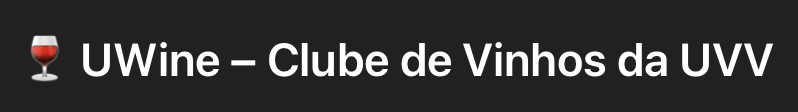

<center>

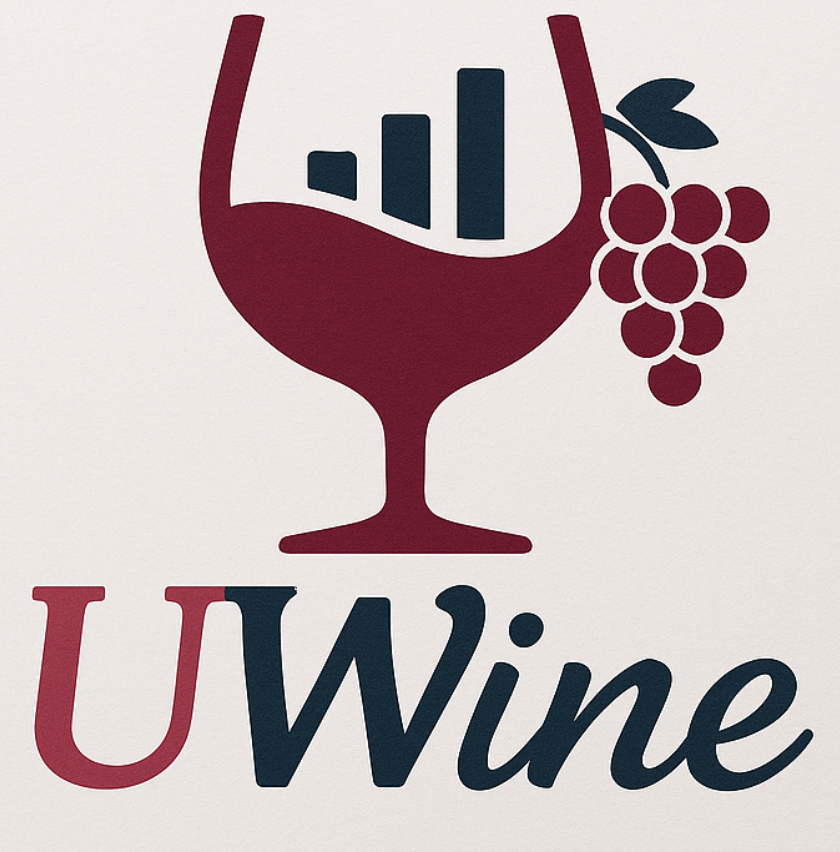

# **Cenário Fictício**:

Prezados(as) alunos(as),

É com entusiasmo que apresento a proposta do **Projeto de Conclusão de Curso (TCC)** para os estudantes do curso de Ciência de Dados da Universidade Vila Velha: o UWine – Clube de Vinhos da UVV.

A proposta do projeto consiste na análise de um Clube de Vinhos universitário fictício, com base em dados simulados, que será totalmente orientado por técnicas e práticas de Ciência de Dados.

Sendo assim, você foi designado como **Consultor em Ciência de Dados** ( ***Data Science Consultant*** ) para fazer uma análise completa dos dados dos clientes a partir de um conjunto de dados (Amostra) com mais de 1 milhão de notas fiscais (~ 350 Megabytes). Além disso, há uma entrada diária de aproximadamente umas 5000 novas notas fiscais no sistema.

O objetivo é permitir que cada consultor(a) percorra foco analíticos diferentes dentro do mesmo ecossistema de dados, aplicando modelos de machine learning supervisionado ou não supervisionado, análise preditiva, dashboards interativos, entre outros.

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do ***Projeto UWine***, adotaremos um workflow composto por cinco etapas principais, alinhadas às boas práticas da Ciência de Dados. Cada etapa representa um marco do processo analítico, permitindo que cada analista avance de forma estruturada do entendimento inicial dos dados até a entrega final dos insights.

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

## ETL: Extração, tratamento e carga dos dados

Nesta etapa carrego o table42, verifico a estrutura da base e trato os problemas encontrados antes de qualquer análise. O objetivo é garantir que as próximas etapas, principalmente o cálculo do tamanho ideal da amostra, sejam feitas sobre dados confiáveis.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import bootstrap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from scipy.stats import anderson
from statsmodels.stats.diagnostic import normal_ad
import statsmodels.api as sm
import statsmodels.formula.api as smf
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
# load do seu TABLE aqui: Numero 42
table42 = pd.read_csv('table42.csv', index_col=0)

In [3]:
table42.head()

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,MEAN: ash,MEAN: alcalinity_of_ash,MEAN: magnesium,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,8521649,SUDESTE,FEMININO,SOLTEIRO,0,"18,484.6200",Entrega foi boa e rápida na UVVine,68.6800,12.0717,2.4084,2.6995,19.8567,66.1197,2.5157,2.3387,0.3864,2.9250,7.5380,1.1814,3.1487,612.4571,PRIME,926.2200
1,3448596,SUDESTE,MASCULINO,CASADO,1,"7,994.9200","Experiência regular, não atendeu a política de...",68.6800,13.7819,3.1351,2.2500,23.0748,101.9861,1.5944,2.9766,0.4176,2.3619,8.2314,1.0903,2.8611,795.5766,VIP,481.6900
2,6258915,SUDESTE,MASCULINO,SOLTEIRO,1,"3,128.6700",Não tenho muito a dizer sobre a UVVine,68.6800,12.9153,2.6115,2.4241,25.6898,115.4285,2.5632,2.3867,0.3013,2.4859,7.6599,1.0357,2.6223,849.7808,ESSENTIAL,440.0000
3,7208207,SUDESTE,MASCULINO,CASADO,0,"21,151.0800",Não gostei do atendimento na UVVine,68.6800,12.0088,3.7262,2.5726,18.2137,73.0825,1.6374,1.6101,0.2473,0.5879,3.9333,1.2779,2.3927,578.8342,PRIME,"1,482.5700"
4,2991721,SUL,MASCULINO,SOLTEIRO,0,"15,781.7300","Serviço eficiente, recomendo o clube: UVVine",71.7100,13.8762,2.5767,2.7753,20.3108,101.0921,1.5881,3.2436,0.1968,1.6200,3.4026,1.3234,2.3237,"1,136.2552",PRIME,"1,580.1600"


In [4]:
table42.shape

(1120000, 23)

### Diagnóstico inicial

A base tem 1.120.000 notas fiscais e 23 colunas, sem valores nulos e sem linhas duplicadas. A coluna NOTA FISCAL é única em todas as linhas. Os tipos foram lidos corretamente.

Identifiquei o papel de cada coluna no projeto:
- **Alvo (o que quero explicar):** TOTAL (R$), o quanto o cliente gasta.
- **Estratos:** TIPO DA CONTA (ESSENTIAL, VIP e PRIME).
- **Pesquisa de satisfação:** OPINIÃO DO CLIENTE e NOTA DE SATISFAÇÃO (%).
- **Perfil do cliente:** região, sexo, estado civil, dependentes e renda.
- **Características do vinho:** as 13 colunas MEAN, baseadas no conjunto Wine.

Três pontos chamaram atenção e foram investigados a seguir: valores negativos em medidas do vinho, uma nota de satisfação quase sempre igual e uma forte assimetria no gasto.

In [5]:
# Diagnóstico inicial
resumo = pd.DataFrame({
    "tipo": table42.dtypes.astype(str),
    "nulos": table42.isna().sum(),
    "%_nulos": (table42.isna().mean() * 100).round(3),
    "valores_unicos": table42.nunique(dropna=True),
    "exemplo": table42.iloc[0],
})
display(resumo)

n_dup = table42.duplicated().sum()
print(f"Linhas totalmente duplicadas: {n_dup:,} ({n_dup/len(table42)*100:.3f}%)")

display(table42.describe().T)

,tipo,nulos,%_nulos,valores_unicos,exemplo
NOTA FISCAL,int64,0,0.0000,1120000,8521649
REGIÃO,object,0,0.0000,5,SUDESTE
SEXO,object,0,0.0000,2,FEMININO
ESTADO CIVIL,object,0,0.0000,3,SOLTEIRO
DEPENDENTES,int64,0,0.0000,5,0
RENDA BRUTO (R$),float64,0,0.0000,388901,"18,484.6200"
OPINIÃO DO CLIENTE,object,0,0.0000,25,Entrega foi boa e rápida na UVVine
NOTA DE SATISFAÇÃO (%),float64,0,0.0000,214,68.6800
MEAN: alcohol,float64,0,0.0000,1120000,12.0717
MEAN: malic_acid,float64,0,0.0000,1120000,2.4084


Linhas totalmente duplicadas: 0 (0.000%)


,count,mean,std,min,25%,50%,75%,max
NOTA FISCAL,"1,120,000.0000","4,999,945.6288","2,308,417.7572","1,000,011.0000","3,002,747.0000","4,997,232.5000","7,000,745.5000","9,000,009.0000"
DEPENDENTES,"1,120,000.0000",1.0604,0.9573,0.0000,0.0000,1.0000,1.0000,4.0000
RENDA BRUTO (R$),"1,120,000.0000","7,533.1488","6,588.1200","1,743.2000","3,237.3000","3,349.8000","7,983.9000","32,236.5200"
NOTA DE SATISFAÇÃO (%),"1,120,000.0000",69.0155,1.4882,68.6800,68.6800,68.6800,68.6800,92.2130
MEAN: alcohol,"1,120,000.0000",12.9995,0.8103,9.0280,12.4525,12.9996,13.5463,17.0840
MEAN: malic_acid,"1,120,000.0000",2.3368,1.1156,-3.1805,1.5853,2.3370,3.0887,7.6919
MEAN: ash,"1,120,000.0000",2.3666,0.2735,1.0996,2.1814,2.3663,2.5516,3.6953
MEAN: alcalinity_of_ash,"1,120,000.0000",19.4959,3.3311,3.8393,17.2449,19.4941,21.7472,35.0270
MEAN: magnesium,"1,120,000.0000",99.7532,14.2411,31.0928,90.1419,99.7362,109.3523,163.4239
MEAN: total_phenols,"1,120,000.0000",2.2948,0.6242,-0.7930,1.8734,2.2952,2.7166,5.4403


In [6]:
# Bloco 2 (ETL): checando a consistência.

pd.set_option("display.max_colwidth", None)

ALVO    = "TOTAL (R$)"
ESTRATO = "TIPO DA CONTA"
NOTA    = "NOTA DE SATISFAÇÃO (%)"
RENDA   = "RENDA BRUTO (R$)"
COLS_VINHO = [c for c in table42.columns if c.startswith("MEAN:")]

# Quantas notas fiscais existem em cada tipo de conta
est = table42[ESTRATO].value_counts().to_frame("qtd")
est["%"] = (est["qtd"] / len(table42) * 100).round(2)
print("2.1 Distribuição dos estratos")
display(est)

# Função que resume uma coluna numérica: centro, dispersão e formato da distribuição
def resumo(s):
    return pd.Series({
        "n": s.size, "media": s.mean(), "desvio": s.std(),
        "cv_%": s.std() / s.mean() * 100,
        "min": s.min(), "q1": s.quantile(.25), "mediana": s.median(),
        "q3": s.quantile(.75), "max": s.max(),
        "assimetria": s.skew(), "curtose": s.kurt(),
    })

# Comparo o gasto e a renda entre os estratos e com o conjunto geral
for col in (ALVO, RENDA):
    tab = table42.groupby(ESTRATO)[col].apply(resumo).unstack()
    tab.loc["GERAL"] = resumo(table42[col])
    print(f"\n2.2 {col} por estrato")
    display(tab)

# Conto os outliers do gasto pelo critério do IQR (1,5 vezes a distância interquartil)
def n_outliers_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - k * iqr) | (s > q3 + k * iqr)).sum()

out = table42.groupby(ESTRATO)[ALVO].agg(n="size", outliers=n_outliers_iqr)
out.loc["GERAL"] = [len(table42), n_outliers_iqr(table42[ALVO])]
out["%"] = (out["outliers"] / out["n"] * 100).round(3)
print(f"\n2.3 Outliers IQR em {ALVO}")
display(out)

# As medidas do vinho não deveriam ser negativas, então verifico quantas são
neg = table42[COLS_VINHO] < 0
tab_neg = pd.DataFrame({
    "qtd_negativos": neg.sum(),
    "%": (neg.mean() * 100).round(3),
    "min": table42[COLS_VINHO].min(),
})
print("\n2.4 Valores negativos nas variáveis do vinho")
display(tab_neg)

# Mais importante que a contagem por coluna é saber quantas notas fiscais seriam afetadas
linhas_neg = neg.any(axis=1)
print(f"Linhas com pelo menos 1 negativo: {linhas_neg.sum():,} ({linhas_neg.mean()*100:.3f}%)")
print("Percentual dessas linhas em cada estrato:")
display(linhas_neg.groupby(table42[ESTRATO]).mean().mul(100).round(3).to_frame("%_linhas_neg"))

# A nota de satisfação parece repetida demais, então vejo se ela é por cliente ou por grupo
vc = table42[NOTA].value_counts()
print(f"\n2.5 {NOTA}: os 10 valores mais frequentes")
display(pd.DataFrame({"qtd": vc.head(10), "%": (vc.head(10) / len(table42) * 100).round(3)}))
for grupo in ("REGIÃO", ESTRATO):
    print(f"\nNota de satisfação por {grupo}")
    display(table42.groupby(grupo)[NOTA].agg(["nunique", "min", "median", "mean", "max", "count"]))

# Por fim, a frequência de cada categoria do perfil do cliente e das opiniões
for col in ("REGIÃO", "SEXO", "ESTADO CIVIL", "DEPENDENTES", "OPINIÃO DO CLIENTE"):
    vc = table42[col].value_counts()
    print(f"\n2.6 {col}")
    display(pd.DataFrame({"qtd": vc, "%": (vc / len(table42) * 100).round(2)}))

2.1 Distribuição dos estratos


,qtd,%
TIPO DA CONTA,,
ESSENTIAL,666569,59.5200
VIP,261791,23.3700
PRIME,191640,17.1100



2.2 TOTAL (R$) por estrato


,n,media,desvio,cv_%,min,q1,mediana,q3,max,assimetria,curtose
TIPO DA CONTA,,,,,,,,,,,
ESSENTIAL,"666,569.0000",415.6124,328.0072,78.9214,71.7200,239.4200,370.3900,498.8100,"3,810.5000",4.7394,30.2474
PRIME,"191,640.0000","2,148.1214","1,057.5188",49.2299,76.2500,"1,264.4575","2,072.5200","2,981.6650","5,588.2200",0.2181,-0.8644
VIP,"261,791.0000",919.9538,477.8268,51.9403,74.2400,560.3900,872.6500,"1,188.0850","3,817.5900",1.5986,5.0242
GERAL,"1,120,000.0000",829.9428,842.6942,101.5364,71.7200,319.9700,499.1700,"1,025.3000","5,588.2200",2.0483,3.8691



2.2 RENDA BRUTO (R$) por estrato


,n,media,desvio,cv_%,min,q1,mediana,q3,max,assimetria,curtose
TIPO DA CONTA,,,,,,,,,,,
ESSENTIAL,"666,569.0000","3,760.1224","2,415.6502",64.2439,"1,743.2000","3,198.1200","3,257.3100","3,320.3500","21,194.4000",5.1359,26.5932
PRIME,"191,640.0000","19,538.0139","5,410.1992",27.6906,"1,855.9100","18,338.8950","20,898.8900","22,921.3575","32,236.5200",-1.4675,1.7922
VIP,"261,791.0000","8,352.0084","2,643.5736",31.6520,"1,800.0400","7,553.4850","7,776.9100","8,020.2400","21,244.4500",2.8207,9.2383
GERAL,"1,120,000.0000","7,533.1488","6,588.1200",87.4551,"1,743.2000","3,237.3000","3,349.8000","7,983.9000","32,236.5200",1.4855,0.8382


... (18 outputs left out)


2.6 DEPENDENTES


,qtd,%
DEPENDENTES,,
1,593858,53.0200
0,302086,26.9700
2,111931,9.9900
3,78519,7.0100
4,33606,3.0000



2.6 OPINIÃO DO CLIENTE


,qtd,%
OPINIÃO DO CLIENTE,,
Entrega foi boa e rápida na UVVine,172818,15.4300
Funcionou bem e me atendeu no prazo certo a UVVine,172639,15.4100
Fiquei satisfeito com o serviço da UVVine,172523,15.4000
"Serviço eficiente, recomendo o clube: UVVine",172238,15.3800
Gostei do atendimento prestado pela UVVine,172182,15.3700
Nada digno de nota com a UVVine,33859,3.0200
Foi indiferente minha experiência com a UVVine,33673,3.0100
Não tenho muito a dizer sobre a UVVine,33549,3.0000
Sem opinião formada sobre a UVVine,33483,2.9900


### Auditoria de consistência

- **Estratos:** ESSENTIAL 59,5%, VIP 23,4% e PRIME 17,1%. Todos têm volume suficiente para amostragem.
- **Gasto por estrato:** as médias são bem diferentes (R$ 416, R$ 920 e R$ 2.148), o que confirma a necessidade de analisar por estrato. O ESSENTIAL tem assimetria e curtose muito altas por causa de pontos extremos. Os mínimos quase iguais nos três estratos indicam outliers aleatórios inseridos na base.
- **Outliers:** pelo critério do IQR, o geral aponta 9,8%, mas esse número é enganoso porque mistura estratos. Por estrato, são 3,7% no ESSENTIAL, 2,7% no VIP e praticamente 0% no PRIME. A decisão sobre eles fica para a A2.
- **Negativos no vinho:** 72.477 linhas (6,47%) têm alguma medida negativa, o que é fisicamente impossível. Os percentuais batem com a cauda de uma distribuição normal simulada e são iguais nos três estratos.
- **Nota de satisfação:** 92,4% das notas são exatamente 68,68. Ela é constante no ESSENTIAL e só varia no PRIME. A hipótese de ser uma nota por região foi descartada.
- **Opinião do cliente:** as 25 frases formam 5 grupos com frequências idênticas, o que indica uma escala de satisfação de 5 níveis.
- **Categóricas:** sem grafias diferentes ou categorias inválidas.

In [7]:
# Bloco 3 (ETL): limpeza e organização da base.
# O table42 original continua intacto. Todas as mudanças são feitas na nova tabela, a table42_limpa.

from scipy import stats

# Marco as notas fiscais que têm pelo menos uma medida de vinho negativa
flag_neg = (table42[COLS_VINHO] < 0).any(axis=1).to_numpy()

# Antes de remover, confiro se essas notas gastam diferente das outras dentro de cada estrato.
# Se o gasto for parecido, tirar essas linhas não distorce o nosso alvo.
aux = table42[[ESTRATO, ALVO]].assign(tem_negativo=flag_neg)
print("3.1 Gasto das notas com e sem medidas negativas")
display(aux.groupby([ESTRATO, "tem_negativo"])[ALVO].agg(["count", "mean", "median", "std"]))

# O teste KS compara as duas distribuições inteiras, e não só a média.
# Um p-valor acima de 0,05 indica que não há evidência de diferença entre os grupos.
for nome, g in aux.groupby(ESTRATO):
    ks = stats.ks_2samp(g.loc[g["tem_negativo"], ALVO], g.loc[~g["tem_negativo"], ALVO])
    print(f"{nome}: KS = {ks.statistic:.4f} | p-valor = {ks.pvalue:.4f}")

# Removo as linhas com valores fisicamente impossíveis
table42_limpa = table42.loc[~flag_neg].copy()

# Confiro se a proporção dos estratos se manteve depois da remoção
prop = pd.DataFrame({
    "antes_%": table42[ESTRATO].value_counts(normalize=True) * 100,
    "depois_%": table42_limpa[ESTRATO].value_counts(normalize=True) * 100,
}).round(3)
print("\n3.2 Proporção dos estratos antes e depois da remoção")
display(prop)
print(f"Linhas removidas: {flag_neg.sum():,} | Linhas restantes: {len(table42_limpa):,}")

# As 25 opiniões formam 5 grupos de frequência idêntica.
# Transformo esses grupos numa escala de 1 (ruim) a 5 (excelente).
NIVEIS_OPINIAO = {
    5: ["Serviço impecável, adorei o clube: UVVine",
        "Superou expectativas o atendimento na UVVine",
        "Ótimo! Tudo ocorreu maravilhosamente bem com a UVVine",
        "Produto perfeito, chegou antes do prazo de previsão. Top demais a UVVine",
        "Excelente experiência, recomendo muito a UVVine"],
    4: ["Entrega foi boa e rápida na UVVine",
        "Funcionou bem e me atendeu no prazo certo a UVVine",
        "Fiquei satisfeito com o serviço da UVVine",
        "Serviço eficiente, recomendo o clube: UVVine",
        "Gostei do atendimento prestado pela UVVine"],
    3: ["Nada digno de nota com a UVVine",
        "Foi indiferente minha experiência com a UVVine",
        "Não tenho muito a dizer sobre a UVVine",
        "Sem opinião formada sobre a UVVine",
        "Compro exponenciamente, opinião neutra sobre UVVine"],
    2: ["Atendimento comum, poderia melhorar em cordialidade a UVVine",
        "Nada demais, serviço regular na UVVine",
        "Experiência regular, não atendeu a política de cashback da UVVine",
        "Foi aceitável, esperava mais da UVVine",
        "Razoável, com margem de melhora no preço médio da UVVine"],
    1: ["Senti que faltou qualidade no atendimento da UVVine",
        "Tive uma experiência ruim com a UVVine",
        "Não gostei do atendimento na UVVine",
        "Serviço deixou a desejar na UVVine",
        "Produto chegou atrasado na UVVine"],
}
ROTULOS_OPINIAO = {1: "Ruim", 2: "Regular", 3: "Neutro", 4: "Bom", 5: "Excelente"}

mapa_opiniao = {frase: nivel for nivel, frases in NIVEIS_OPINIAO.items() for frase in frases}
table42_limpa["NÍVEL DA OPINIÃO"] = table42_limpa["OPINIÃO DO CLIENTE"].map(mapa_opiniao)

# Se alguma frase tiver ficado sem nível, ela aparece aqui. O esperado é zero.
print(f"\nOpiniões sem nível atribuído: {table42_limpa['NÍVEL DA OPINIÃO'].isna().sum()}")

contagem = table42_limpa["NÍVEL DA OPINIÃO"].value_counts().sort_index()
print("\n3.3 Escala de opinião criada")
display(pd.DataFrame({
    "rótulo": contagem.index.map(ROTULOS_OPINIAO),
    "qtd": contagem,
    "%": (contagem / len(table42_limpa) * 100).round(2),
}))

# As colunas de texto viram 'category', que ocupa bem menos memória e não altera nenhum valor
mem_antes = table42_limpa.memory_usage(deep=True).sum() / 1024**2
for col in ["REGIÃO", "SEXO", "ESTADO CIVIL", "OPINIÃO DO CLIENTE", ESTRATO]:
    table42_limpa[col] = table42_limpa[col].astype("category")
mem_depois = table42_limpa.memory_usage(deep=True).sum() / 1024**2
print(f"\n3.4 Memória: {mem_antes:,.1f} MB antes e {mem_depois:,.1f} MB depois")
print(f"Shape final da table42_limpa: {table42_limpa.shape}")

3.1 Gasto das notas com e sem medidas negativas


count       mean     median        std
TIPO DA CONTA tem_negativo                                         
ESSENTIAL     False         623497   415.6167   370.3700   327.9431
              True           43072   415.5503   370.6950   328.9372
PRIME         False         179132 2,149.3293 2,072.9100 1,057.5067
              True           12508 2,130.8224 2,064.9600 1,057.5834
VIP           False         244894   919.4916   872.2550   477.4157
              True           16897   926.6534   879.1500   483.7104

ESSENTIAL: KS = 0.0030 | p-valor = 0.8609
PRIME: KS = 0.0144 | p-valor = 0.0154
VIP: KS = 0.0110 | p-valor = 0.0439

3.2 Proporção dos estratos antes e depois da remoção


,antes_%,depois_%
TIPO DA CONTA,,
ESSENTIAL,59.5150,59.5210
VIP,23.3740,23.3780
PRIME,17.1110,17.1010


Linhas removidas: 72,477 | Linhas restantes: 1,047,523

Opiniões sem nível atribuído: 173755

3.3 Escala de opinião criada


,rótulo,qtd,%
NÍVEL DA OPINIÃO,,,
1.0000,Ruim,10473,1.0000
2.0000,Regular,41874,4.0000
3.0000,Neutro,157083,15.0000
4.0000,Bom,645627,61.6300
5.0000,Excelente,18711,1.7900



3.4 Memória: 519.5 MB antes e 164.8 MB depois
Shape final da table42_limpa: (1047523, 24)


### Limpeza

Removi as 72.477 notas com medidas de vinho negativas. Elas gastam praticamente o mesmo que as demais: no ESSENTIAL o teste KS não indicou diferença (p = 0,86). No PRIME (p = 0,015) e no VIP (p = 0,044) o teste acusou diferença, mas a estatística KS ficou abaixo de 0,015 e as médias diferem menos de 1%. É uma significância causada pelo tamanho enorme da amostra, sem relevância prática. A proporção dos estratos se manteve igual depois da remoção.

Também criei a coluna NÍVEL DA OPINIÃO (1 = Ruim até 5 = Excelente) e converti as colunas de texto para category, o que reduziu a memória de 519 MB para 165 MB.

O mapeamento das opiniões deixou 173.755 notas sem nível. O bloco seguinte investiga o motivo e corrige.

In [8]:
# Bloco 3b (ETL): corrijo a escala de opinião e meço o impacto real da remoção no gasto.
import unicodedata, re

# Primeiro mostro exatamente como estão escritas as frases que não encontraram nível.
# O repr revela espaços extras e caracteres invisíveis que não aparecem na tela.
sem_nivel = table42_limpa.loc[table42_limpa["NÍVEL DA OPINIÃO"].isna(), "OPINIÃO DO CLIENTE"]
print("3.5 Frases que não bateram com o dicionário (texto exato)")
for frase, qtd in sem_nivel.value_counts().items():
    if qtd > 0:
        print(f"{qtd:>9,}  {repr(frase)}")

# Para comparar, padronizo os acentos, troco qualquer sequência de espaços por um só
# e ignoro maiúsculas e minúsculas, tanto no dicionário quanto nos dados.
def normalizar(texto):
    texto = unicodedata.normalize("NFC", str(texto))
    return re.sub(r"\s+", " ", texto).strip().casefold()

mapa_normalizado = {normalizar(frase): nivel for frase, nivel in mapa_opiniao.items()}
frases_reais = table42_limpa["OPINIÃO DO CLIENTE"].cat.categories
nivel_por_frase = {frase: mapa_normalizado.get(normalizar(frase)) for frase in frases_reais}

table42_limpa["NÍVEL DA OPINIÃO"] = (
    table42_limpa["OPINIÃO DO CLIENTE"].astype(str).map(nivel_por_frase).astype("Int64")
)

# Se ainda sobrar alguma frase sem nível, ela aparece aqui com o texto exato
restantes = [repr(f) for f, n in nivel_por_frase.items() if n is None]
print(f"\nFrases ainda sem nível após a normalização: {len(restantes)}")
for f in restantes:
    print("  ", f)
print(f"Notas fiscais sem nível: {table42_limpa['NÍVEL DA OPINIÃO'].isna().sum():,}")

contagem = table42_limpa["NÍVEL DA OPINIÃO"].value_counts().sort_index()
print("\n3.6 Escala de opinião corrigida")
display(pd.DataFrame({
    "rótulo": contagem.index.map(ROTULOS_OPINIAO),
    "qtd": contagem,
    "%": (contagem / len(table42_limpa) * 100).round(2),
}))

# Por fim, comparo média e desvio do gasto antes e depois da remoção, estrato por estrato.
# Isso mostra o tamanho prático da mudança, que é o que importa para a decisão.
def media_desvio(df):
    return df[ALVO].groupby(df[ESTRATO].astype(str)).agg(["mean", "std"])

antes, depois = media_desvio(table42), media_desvio(table42_limpa)
impacto = pd.DataFrame({
    "media_original": antes["mean"],
    "media_limpa": depois["mean"],
    "dif_media_R$": depois["mean"] - antes["mean"],
    "dif_media_%": (depois["mean"] / antes["mean"] - 1) * 100,
    "desvio_original": antes["std"],
    "desvio_limpo": depois["std"],
})
print("\n3.7 Impacto da remoção no gasto (TOTAL R$)")
display(impacto)

3.5 Frases que não bateram com o dicionário (texto exato)
  161,105  'Serviço eficiente, recomendo o clube:  UVVine'
    6,399  'Serviço impecável, adorei o clube:  UVVine'
    6,251  'Ótimo! Tudo ocorreu maravilhosamente bem com a  UVVine'

Frases ainda sem nível após a normalização: 0
Notas fiscais sem nível: 0

3.6 Escala de opinião corrigida


,rótulo,qtd,%
NÍVEL DA OPINIÃO,,,
1,Ruim,10473,1.0000
2,Regular,41874,4.0000
3,Neutro,157083,15.0000
4,Bom,806732,77.0100
5,Excelente,31361,2.9900



3.7 Impacto da remoção no gasto (TOTAL R$)


,media_original,media_limpa,dif_media_R$,dif_media_%,desvio_original,desvio_limpo
TIPO DA CONTA,,,,,,
ESSENTIAL,415.6124,415.6167,0.0043,0.0010,328.0072,327.9431
PRIME,"2,148.1214","2,149.3293",1.2079,0.0562,"1,057.5188","1,057.5067"
VIP,919.9538,919.4916,-0.4623,-0.0502,477.8268,477.4157


### Correção da escala de opinião e impacto da limpeza

As 173.755 notas sem nível vinham de três frases com um espaço duplo antes de "UVVine" (por exemplo, "recomendo o clube:  UVVine"), invisível na tela. Depois de padronizar os textos, todas as opiniões foram classificadas: Ruim 1%, Regular 4%, Neutro 15%, Bom 77% e Excelente 3%.

A remoção das linhas com medidas negativas mudou a média do gasto em no máximo 0,056% (R$ 1,21 no PRIME), e os desvios praticamente não mudaram. Isso confirma que a limpeza não distorceu o alvo.

**Base final da A1:** 1.047.523 notas fiscais e 24 colunas.

In [9]:
# Bloco 4 (ETL): fechamento da limpeza.

# Corrijo o espaço duplo direto no texto das opiniões, para que apareçam limpas nos gráficos.
# Como a coluna é category, basta renomear as 25 categorias, sem percorrer o milhão de linhas.
table42_limpa["OPINIÃO DO CLIENTE"] = table42_limpa["OPINIÃO DO CLIENTE"].cat.rename_categories(
    lambda frase: re.sub(r"\s+", " ", frase).strip()
)
print("Frases com espaço duplo restantes:",
      sum("  " in f for f in table42_limpa["OPINIÃO DO CLIENTE"].cat.categories))

# Resumo da base que segue para a exploração
print(f"Shape final: {table42_limpa.shape}")
print(f"Memória: {table42_limpa.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")
print("\nTipos das colunas:")
print(table42_limpa.dtypes.value_counts())

Frases com espaço duplo restantes: 0
Shape final: (1047523, 24)
Memória: 165.8 MB

Tipos das colunas:
float64     16
int64        2
category     1
category     1
category     1
category     1
category     1
Int64        1
Name: count, dtype: int64


### Fechamento

Para terminar a limpeza, corrigi o espaço duplo diretamente no texto das três opiniões afetadas, para que as frases apareçam corretas nos gráficos da pesquisa de satisfação.

A base tratada, table42_limpa, segue para a exploração com 1.047.523 notas fiscais e 24 colunas. Ela não tem nulos, duplicados nem medidas impossíveis, e as categóricas foram convertidas para category, ocupando cerca de 165 MB. O table42 original foi mantido intacto para comparação.

In [10]:
def optimal_stratified_sample_size(
    df,
    value_column,
    strata_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the optimal sample size for an infinite stratified population
    using Neyman allocation and consecutive marginal stabilization of the
    stratified standard error.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataset.

    value_column : str
        Numerical target variable used to estimate the mean.

    strata_column : str
        Categorical stratification variable.

    n_min : int, default=100
        Minimum total sample size evaluated.

    n_max : int, default=50000
        Maximum total sample size evaluated.

    step : int, default=100
        Increment between consecutive sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum relative reduction accepted for standard error stabilization.
        Example: 0.01 means 1%.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions that must remain below
        the stabilization threshold.

    plot : bool, default=True
        If True, plot the standard error stabilization curve.

    Returns
    -------
    summary : pandas.DataFrame
        Sample allocation per stratum.

    results : dict
        Dictionary containing:
        - optimal_n
        - optimal_standard_error
        - sample_sizes
        - standard_error_curve
        - marginal_reduction
        - stabilization_threshold
        - consecutive_points
        - strata_statistics
    """

    # Keep only the required columns and remove missing values
    data = df[[value_column, strata_column]].dropna().copy()

    # Convert the target variable to numeric
    data[value_column] = pd.to_numeric(data[value_column], errors="coerce")
    data = data.dropna()

    if data.empty:
        raise ValueError("The dataset is empty after removing missing or invalid values.")

    # Estimate stratum weights
    weights = (
        data[strata_column]
        .value_counts(normalize=True)
        .sort_index()
    )

    # Estimate stratum standard deviations
    stds = (
        data.groupby(strata_column)[value_column]
        .std()
        .sort_index()
    )

    # Align both series
    stds = stds.loc[weights.index]

    strata = weights.index.values
    Wh = weights.values
    Sh = stds.values

    if np.any(np.isnan(Sh)):
        raise ValueError(
            "At least one stratum has insufficient observations "
            "to calculate standard deviation."
        )

    if np.any(Sh == 0):
        print(
            "Warning: At least one stratum has zero standard deviation. "
            "Neyman allocation may assign a very small sample to this stratum."
        )

    # Neyman allocation weights
    neyman_weights = Wh * Sh

    if neyman_weights.sum() == 0:
        raise ValueError(
            "Neyman weights are zero. Check the variability of the target variable."
        )

    sample_sizes = np.arange(n_min, n_max + step, step)

    standard_errors = []
    allocations = []

    for n in sample_sizes:

        nh = n * neyman_weights / neyman_weights.sum()

        se = np.sqrt(
            np.sum(
                (Wh ** 2) * (Sh ** 2) / nh
            )
        )

        standard_errors.append(se)
        allocations.append(nh)

    standard_errors = np.array(standard_errors)
    allocations = np.array(allocations)

    # Marginal relative reduction of the standard error
    marginal_reduction = (
        np.abs(np.diff(standard_errors)) / standard_errors[:-1]
    )

    stable_sequence_index = None

    for i in range(0, len(marginal_reduction) - consecutive_points + 1):

        window = marginal_reduction[i:i + consecutive_points]

        if np.all(window < stabilization_threshold):
            stable_sequence_index = i
            break

    if stable_sequence_index is None:
        raise ValueError(
            "No consecutive stabilization point found within the evaluated interval. "
            "Try increasing n_max, increasing step, or using a larger threshold."
        )

    optimal_index = stable_sequence_index + consecutive_points

    optimal_n = sample_sizes[optimal_index]
    optimal_se = standard_errors[optimal_index]
    optimal_allocation = allocations[optimal_index]

    summary = pd.DataFrame({
        "Stratum": strata,
        "Population Weight (Wh)": Wh,
        "Std. Deviation (Sh)": Sh,
        "Neyman Weight (Wh x Sh)": neyman_weights,
        "Allocated Sample (nh)": np.round(optimal_allocation).astype(int)
    })

    summary["Allocated Sample (%)"] = (
        summary["Allocated Sample (nh)"] /
        summary["Allocated Sample (nh)"].sum()
    )

    strata_statistics = pd.DataFrame({
        "Stratum": strata,
        "Wh": Wh,
        "Sh": Sh,
        "Wh_x_Sh": neyman_weights
    })

    if plot:

        plt.figure(figsize=(11, 6))

        plt.plot(
            sample_sizes,
            standard_errors,
            linewidth=3,
            label="Stratified standard error"
        )

        plt.scatter(
            optimal_n,
            optimal_se,
            s=120,
            label="Optimal sample size"
        )

        plt.axvline(
            optimal_n,
            linestyle="--"
        )

        plt.text(
            optimal_n,
            optimal_se,
            f"  n = {optimal_n}\n  SE = {optimal_se:.4f}",
            verticalalignment="bottom"
        )

        plt.xlabel("Total Sample Size (n)")
        plt.ylabel("Stratified Standard Error")
        plt.title("Consecutive Marginal Stabilization of the Standard Error")
        plt.grid(True)
        plt.legend()
        plt.show()

    results = {
        "optimal_n": int(optimal_n),
        "optimal_standard_error": float(optimal_se),
        "sample_sizes": sample_sizes,
        "standard_error_curve": standard_errors,
        "marginal_reduction": marginal_reduction,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "strata_statistics": strata_statistics
    }

    return summary, results

In [11]:
def bootstrap_distribution_eda(data, metric=np.mean, bins=30, confidence_level=0.95):
    """
    Compute and visualize the bootstrap sampling distribution of a statistic
    using Seaborn for advanced Exploratory Data Analysis (EDA).

    Parameters
    ----------
    data : array-like
        One-dimensional numeric sample.

    metric : callable, default=np.mean
        Statistic applied to each bootstrap resample.

    bins : int, default=30
        Number of histogram bins.

    confidence_level : float, default=0.90
        Confidence level for the bootstrap interval.

    Returns
    -------
    res : BootstrapResult
        Object containing bootstrap distribution, CI, and standard error.
    """

    rng = np.random.default_rng()
    data = (data,)

    # Bootstrap computation
    res = bootstrap(
        data,
        metric,
        confidence_level=confidence_level,
        random_state=rng
    )

    dist = res.bootstrap_distribution

    # ---- Advanced Visualization with Seaborn ----
    plt.figure(figsize=(10, 6))

    # Histogram + KDE
    sns.histplot(dist, bins=bins, kde=True, stat="density")

    # Mean of bootstrap distribution
    plt.axvline(np.mean(dist), linestyle='-', label='Bootstrap Mean')

    # Confidence interval bounds
    plt.axvline(res.confidence_interval.low, linestyle='--', label='CI Lower')
    plt.axvline(res.confidence_interval.high, linestyle='--', label='CI Upper')

    plt.title("Bootstrap Sampling Distribution")
    plt.xlabel("Statistic Value")
    plt.ylabel("Density")
    plt.legend()
    plt.show()

    print("CONFIDENCE INTERVAL")
    print(f"LOW  : {res.confidence_interval.low:.4f}")
    print(f"HIGH : {res.confidence_interval.high:.4f}")
    print(f"SE   : {res.standard_error:.4f}")

    return res

In [12]:
def SE(dataset):
  '''
    HELP: Standart Error (Erro Padrão)
    O Erro-Padrão é uma métrica única que resume a variabilidade na distribuição de amostragem para uma estatística.
    Ele pode ser estimado utilizando uma estatística baseada no desvio-padrão (Sigma) dos valores da amostra e no tamanho de amostra N:
  '''
  return dataset.std() / (len(dataset) ** 0.5)

In [13]:
def optimal_sample_size(
    df,
    value_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the operational sample size for an infinite population
    using consecutive marginal stabilization of the standard error.

    Stabilization is confirmed when the marginal reduction in the
    projected standard error is less than or equal to the specified
    threshold for a given number of consecutive sample-size increments.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing the reference or pilot data.

    value_column : str
        Name of the numerical variable used to estimate variability.

    n_min : int, default=100
        Minimum candidate sample size.

    n_max : int, default=50000
        Maximum candidate sample size.

    step : int, default=100
        Increment between candidate sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum acceptable marginal reduction in the standard error.
        For a monetary variable, 0.01 represents R$ 0.01.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions required to confirm
        stabilization.

    plot : bool, default=True
        If True, displays the standard-error curve, the mean
        standard-error line and a zoom window around the stabilization
        sequence.

    Returns
    -------
    dict
        Dictionary containing:

        - optimal_sample_size:
          Sample size at which stabilization is confirmed.

        - stabilization_start:
          First sample size in the confirmed sequence.

        - standard_error:
          Standard error at the recommended sample size.

        - mean_standard_error:
          Mean of the projected standard errors.

        - marginal_reduction:
          Marginal reduction at the confirmation point.

        - population_standard_deviation:
          Standard deviation estimated from the reference data.

        - stabilization_found:
          Indicates whether stabilization was found.

        - results:
          DataFrame containing all calculated points.

    Notes
    -----
    For an infinite population, the projected standard error is:

        SE(n) = s / sqrt(n)

    The marginal reduction is:

        Delta_SE(n) = SE(n - step) - SE(n)

    No finite population correction is applied.

    The returned sample size is an operational recommendation conditioned
    on the parameters of the function. It is not a universal mathematical
    optimum.
    """

    # ==============================================================
    # 1. Input validation
    # ==============================================================
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if value_column not in df.columns:
        raise KeyError(
            f"Column '{value_column}' was not found in the DataFrame."
        )

    if (
        not isinstance(n_min, int)
        or isinstance(n_min, bool)
        or n_min < 2
    ):
        raise ValueError(
            "n_min must be an integer greater than or equal to 2."
        )

    if (
        not isinstance(n_max, int)
        or isinstance(n_max, bool)
        or n_max <= n_min
    ):
        raise ValueError(
            "n_max must be an integer greater than n_min."
        )

    if (
        not isinstance(step, int)
        or isinstance(step, bool)
        or step <= 0
    ):
        raise ValueError(
            "step must be a positive integer."
        )

    if (
        not isinstance(stabilization_threshold, (int, float))
        or isinstance(stabilization_threshold, bool)
        or not np.isfinite(stabilization_threshold)
        or stabilization_threshold <= 0
    ):
        raise ValueError(
            "stabilization_threshold must be a finite number "
            "greater than zero."
        )

    if (
        not isinstance(consecutive_points, int)
        or isinstance(consecutive_points, bool)
        or consecutive_points < 1
    ):
        raise ValueError(
            "consecutive_points must be a positive integer."
        )

    # ==============================================================
    # 2. Numerical data preparation
    # ==============================================================
    values = pd.to_numeric(
        df[value_column],
        errors="coerce"
    ).dropna()

    if len(values) < 2:
        raise ValueError(
            "The selected column must contain at least two valid "
            "numerical observations."
        )

    standard_deviation = float(
        values.std(ddof=1)
    )

    if not np.isfinite(standard_deviation):
        raise ValueError(
            "The standard deviation could not be estimated."
        )

    if standard_deviation == 0:
        raise ValueError(
            "The selected variable has zero variability."
        )

    # ==============================================================
    # 3. Candidate sample sizes
    # ==============================================================
    sample_sizes = np.arange(
        n_min,
        n_max + 1,
        step,
        dtype=int
    )

    if len(sample_sizes) <= consecutive_points:
        raise ValueError(
            "The search interval must contain more candidate sizes "
            "than consecutive_points."
        )

    # Projected standard error for an infinite population:
    # SE(n) = s / sqrt(n)
    standard_errors = (
        standard_deviation / np.sqrt(sample_sizes)
    )

    # Mean of the projected standard errors
    mean_standard_error = float(
        np.mean(standard_errors)
    )

    # Marginal reduction:
    # SE at the previous point minus SE at the current point
    marginal_reductions = np.full(
        len(standard_errors),
        np.nan,
        dtype=float
    )

    marginal_reductions[1:] = (
        standard_errors[:-1]
        - standard_errors[1:]
    )

    # A point is stable when the marginal reduction is less than
    # or equal to the defined threshold.
    stable_points = np.zeros(
        len(sample_sizes),
        dtype=bool
    )

    stable_points[1:] = (
        marginal_reductions[1:]
        <= stabilization_threshold
    )

    # ==============================================================
    # 4. Consecutive stabilization search
    # ==============================================================
    confirmation_index = None
    consecutive_count = 0

    for index in range(1, len(sample_sizes)):

        if stable_points[index]:
            consecutive_count += 1
        else:
            consecutive_count = 0

        if consecutive_count >= consecutive_points:
            confirmation_index = index
            break

    if confirmation_index is not None:

        start_index = (
            confirmation_index
            - consecutive_points
            + 1
        )

        stabilization_indices = np.arange(
            start_index,
            confirmation_index + 1
        )

        stabilization_start = int(
            sample_sizes[start_index]
        )

        optimal_n = int(
            sample_sizes[confirmation_index]
        )

        optimal_se = float(
            standard_errors[confirmation_index]
        )

        optimal_reduction = float(
            marginal_reductions[confirmation_index]
        )

        stabilization_found = True

    else:

        start_index = None

        stabilization_indices = np.array(
            [],
            dtype=int
        )

        stabilization_start = None
        optimal_n = None
        optimal_se = None
        optimal_reduction = None
        stabilization_found = False

    # ==============================================================
    # 5. Complete result table
    # ==============================================================
    results = pd.DataFrame({
        "sample_size": sample_sizes,
        "standard_error": standard_errors,
        "marginal_reduction": marginal_reductions,
        "stable_point": stable_points,
        "consecutive_confirmation": False
    })

    if stabilization_found:
        results.loc[
            stabilization_indices,
            "consecutive_confirmation"
        ] = True

    # ==============================================================
    # 6. Visualization
    # ==============================================================
    if plot:

        # Constrained layout avoids the tight_layout warning.
        figure, axis = plt.subplots(
            figsize=(15, 8),
            layout="constrained"
        )

        # Main standard-error curve
        axis.plot(
            sample_sizes,
            standard_errors,
            color="#2878B5",
            linewidth=2.6
        )

        # Mean standard-error horizontal line
        axis.axhline(
            y=mean_standard_error,
            color="#D62728",
            linestyle="--",
            linewidth=2
        )

        # Identification of the mean standard-error line
        axis.text(
            n_max,
            mean_standard_error,
            (
                "  Erro-padrão médio = "
                f"{mean_standard_error:.4f}"
            ),
            color="#D62728",
            fontsize=10,
            va="bottom",
            ha="right"
        )

        if stabilization_found:

            zoom_x = sample_sizes[
                stabilization_indices
            ]

            zoom_y = standard_errors[
                stabilization_indices
            ]

            # Consecutive stabilization points
            axis.scatter(
                zoom_x,
                zoom_y,
                s=95,
                color="#FF9F1C",
                edgecolor="white",
                linewidth=1.2,
                zorder=5
            )

            # Recommended sample size
            axis.scatter(
                optimal_n,
                optimal_se,
                s=190,
                color="#D62728",
                edgecolor="white",
                linewidth=1.8,
                zorder=6
            )

            # Vertical line at the confirmation point
            axis.axvline(
                x=optimal_n,
                color="#D62728",
                linestyle=":",
                linewidth=1.8
            )

            annotation = (
                f"n recomendado = {optimal_n:,}\n"
                f"EP = {optimal_se:.4f}\n"
                f"ΔEP = {optimal_reduction:.4f}"
            ).replace(",", ".")

            axis.annotate(
                annotation,
                xy=(optimal_n, optimal_se),
                xytext=(20, 38),
                textcoords="offset points",
                fontsize=10.5,
                bbox={
                    "boxstyle": "round,pad=0.45",
                    "facecolor": "white",
                    "edgecolor": "#D62728",
                    "alpha": 0.95
                },
                arrowprops={
                    "arrowstyle": "->",
                    "color": "#D62728",
                    "linewidth": 1.4
                }
            )

            # ======================================================
            # 6.1 Zoom window
            # ======================================================
            inset_axis = inset_axes(
                axis,
                width="43%",
                height="43%",
                loc="upper right",
                borderpad=1.8
            )

            # Includes one point before and one point after the
            # stabilization sequence, whenever available.
            context_start = max(
                start_index - 1,
                0
            )

            context_end = min(
                confirmation_index + 1,
                len(sample_sizes) - 1
            )

            context_indices = np.arange(
                context_start,
                context_end + 1
            )

            # Standard-error curve inside the zoom window
            inset_axis.plot(
                sample_sizes[context_indices],
                standard_errors[context_indices],
                color="#2878B5",
                linewidth=2.2,
                marker="o",
                markersize=5
            )

            # Consecutive stabilization points
            inset_axis.scatter(
                zoom_x,
                zoom_y,
                s=90,
                color="#FF9F1C",
                edgecolor="white",
                linewidth=1.1,
                zorder=5
            )

            # Confirmation point
            inset_axis.scatter(
                optimal_n,
                optimal_se,
                s=145,
                color="#D62728",
                edgecolor="white",
                linewidth=1.5,
                zorder=6
            )

            # Mean standard-error line inside the zoom
            inset_axis.axhline(
                y=mean_standard_error,
                color="#D62728",
                linestyle="--",
                linewidth=1.2,
                alpha=0.8
            )

            # Numerical labels for consecutive stabilization points
            for point_number, point_index in enumerate(
                stabilization_indices,
                start=1
            ):

                point_n = sample_sizes[point_index]
                point_se = standard_errors[point_index]

                inset_axis.annotate(
                    str(point_number),
                    xy=(point_n, point_se),
                    xytext=(0, 10),
                    textcoords="offset points",
                    ha="center",
                    fontsize=9,
                    fontweight="bold",
                    color="#8C4A00"
                )

            # Horizontal limits of the zoom window
            x_margin = max(
                step * 0.4,
                1
            )

            inset_axis.set_xlim(
                sample_sizes[context_start] - x_margin,
                sample_sizes[context_end] + x_margin
            )

            # Vertical limits of the zoom window
            local_standard_errors = standard_errors[
                context_indices
            ]

            y_range = float(
                local_standard_errors.max()
                - local_standard_errors.min()
            )

            if y_range == 0:

                y_margin = max(
                    abs(
                        float(
                            local_standard_errors.mean()
                        )
                    ) * 0.05,
                    1e-6
                )

            else:

                y_margin = y_range * 0.30

            inset_axis.set_ylim(
                float(local_standard_errors.min())
                - y_margin,
                float(local_standard_errors.max())
                + y_margin
            )

            inset_axis.set_title(
                (
                    "Janela ampliada: "
                    f"{consecutive_points} pontos consecutivos"
                ),
                fontsize=10,
                fontweight="bold"
            )

            inset_axis.set_xlabel(
                "Tamanho da amostra",
                fontsize=8
            )

            inset_axis.set_ylabel(
                "Erro-padrão",
                fontsize=8
            )

            inset_axis.tick_params(
                axis="both",
                labelsize=8
            )

            inset_axis.grid(
                True,
                linestyle="--",
                linewidth=0.6,
                alpha=0.5
            )

            # Rectangle and connectors identifying the zoom region
            mark_inset(
                axis,
                inset_axis,
                loc1=2,
                loc2=4,
                fc="none",
                ec="#E76F8A",
                linewidth=1.5
            )

            title = (
                "Estabilização Marginal Consecutiva "
                "do Erro-Padrão\n"
                f"Estabilização confirmada em n = {optimal_n:,}"
            ).replace(",", ".")

        else:

            title = (
                "Estabilização Marginal Consecutiva "
                "do Erro-Padrão\n"
                "Estabilização não encontrada no intervalo analisado"
            )

        axis.set_title(
            title,
            fontsize=15,
            fontweight="bold",
            pad=12
        )

        axis.set_xlabel(
            "Tamanho total da amostra (n)",
            fontsize=12
        )

        axis.set_ylabel(
            "Erro-padrão",
            fontsize=12
        )

        axis.grid(
            True,
            linestyle="--",
            linewidth=0.7,
            alpha=0.45
        )

        # A legenda foi intencionalmente retirada.
        # Não utilizar axis.legend() ou plt.legend().

        plt.show()

    # ==============================================================
    # 7. Structured return
    # ==============================================================
    return {
        "optimal_sample_size": optimal_n,
        "stabilization_start": stabilization_start,
        "standard_error": optimal_se,
        "mean_standard_error": mean_standard_error,
        "marginal_reduction": optimal_reduction,
        "population_standard_deviation": standard_deviation,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "step": step,
        "stabilization_found": stabilization_found,
        "results": results
    }

In [14]:
def bootstrap_media(dados, nome, cor, ax, confianca=0.95, n_reamostras=9999, semente=42):
    """
    HELP: estima por bootstrap a distribuição da média de uma amostra grande e desenha o resultado.

    Segue a mesma ideia da bootstrap_distribution_eda do professor: histograma com KDE,
    média bootstrap e limites do intervalo de confiança. A diferença é que usa o método
    percentil e processa as reamostragens em lotes. Com amostras de dezenas de milhares
    de notas, o método padrão (BCa) precisaria de dezenas de GB de memória e derrubaria o Colab.

    Parâmetros
    dados: valores do gasto do grupo analisado.
    nome: nome do grupo, usado no título do gráfico.
    cor: cor do grupo no gráfico.
    ax: área do gráfico onde o resultado é desenhado.
    confianca: nível de confiança do intervalo.
    n_reamostras: quantidade de reamostragens (o mesmo padrão do scipy).
    semente: garante que o resultado seja reproduzível.

    Retorna um dicionário com a média, o intervalo de confiança e os erros padrão bootstrap e teórico.
    """
    valores = np.asarray(dados, dtype=float)

    res = bootstrap(
        (valores,),
        np.mean,
        confidence_level=confianca,
        n_resamples=n_reamostras,
        method="percentile",
        batch=250,
        random_state=np.random.default_rng(semente),
    )
    dist = res.bootstrap_distribution
    baixo, alto = res.confidence_interval.low, res.confidence_interval.high

    sns.histplot(dist, bins=40, kde=True, stat="density", color=cor,
                 alpha=0.6, edgecolor="white", ax=ax)
    ax.axvline(dist.mean(), color="#0b0b0b", linewidth=1.5,
               label=f"Média bootstrap: R$ {dist.mean():,.2f}")
    ax.axvline(baixo, color="#0b0b0b", linestyle="--", linewidth=1.2,
               label=f"IC {confianca:.0%}: R$ {baixo:,.2f} a R$ {alto:,.2f}")
    ax.axvline(alto, color="#0b0b0b", linestyle="--", linewidth=1.2)
    ax.set_title(f"{nome} (n = {len(valores):,})", loc="left", fontweight="bold")
    ax.set_xlabel("Média do TOTAL (R$) nas reamostragens")
    ax.set_ylabel("Densidade")
    ax.legend(fontsize=9, frameon=False)

    return {
        "grupo": nome,
        "n": len(valores),
        "media_amostral": valores.mean(),
        "ic_inferior": baixo,
        "ic_superior": alto,
        "amplitude_ic": alto - baixo,
        "erro_padrao_bootstrap": res.standard_error,
        "erro_padrao_teorico": SE(pd.Series(valores)),
    }

In [15]:
def AtividadeA1_1(df=None, alvo="TOTAL (R$)", estrato="TIPO DA CONTA",
                  n_max=200_000, passo=100, limiar=0.001, pontos_consecutivos=10,
                  confianca=0.95, semente=42):
    """
    HELP: Atividade A1.1, determinação do tamanho ideal da amostra.

    O que a função faz, em ordem:
    1. Procedimento empírico (optimal_sample_size): curva de estabilização do erro padrão
       do gasto para ESSENTIAL, VIP, PRIME e GERAL, em 4 gráficos.
    2. Procedimento teórico-empírico (optimal_stratified_sample_size): erro padrão
       estratificado com alocação ótima de Neyman, em 1 gráfico.
    3. Define o tamanho ideal como o maior dos cinco resultados.
    4. Sorteia uma amostra com o tamanho ideal e faz a análise bootstrap da média do gasto
       em cada grupo, com intervalo de confiança e erro padrão.

    Parâmetros
    df: base usada como referência da população. Se não for informada, usa a table42_limpa.
    alvo: variável quantitativa analisada (o gasto do cliente).
    estrato: coluna com os tipos de conta.
    n_max, passo: faixa de tamanhos testados, de 100 até n_max, de passo em passo.
    limiar: critério de estabilização. No procedimento empírico vale em reais
        (0,001 = R$ 0,001); no de Neyman é relativo (0,001 = 0,1% de redução).
    pontos_consecutivos: quantos passos seguidos o critério precisa ser atendido.
    confianca: nível de confiança do bootstrap.
    semente: garante que o sorteio da amostra seja reproduzível.

    Retorna um dicionário com as tabelas de resultados, o tamanho ideal e a amostra sorteada.
    """
    if df is None:
        df = table42_limpa

    ordem = ["ESSENTIAL", "VIP", "PRIME", "GERAL"]
    cores = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a", "GERAL": "#898781"}

    # Procedimento empírico: uma curva para cada tipo de conta e uma para a base inteira
    grupos = {nome: df[df[estrato] == nome] for nome in ordem[:3]}
    grupos["GERAL"] = df

    linhas = []
    for nome in ordem:
        print(f"\nProcedimento empírico: {nome}")
        r = optimal_sample_size(
            grupos[nome], alvo,
            n_min=100, n_max=n_max, step=passo,
            stabilization_threshold=limiar,
            consecutive_points=pontos_consecutivos,
            plot=True,
        )
        if not r["stabilization_found"]:
            raise ValueError(f"{nome}: a curva não estabilizou até {n_max:,}. Aumente o n_max.")
        linhas.append({
            "procedimento": "Empírico (erro padrão)",
            "grupo": nome,
            "desvio_padrao": r["population_standard_deviation"],
            "inicio_estabilizacao": r["stabilization_start"],
            "n_recomendado": r["optimal_sample_size"],
            "erro_padrao_no_n": r["standard_error"],
        })

    # Procedimento teórico-empírico: a base inteira, considerando os três estratos ao mesmo tempo
    print("\nProcedimento teórico-empírico: estratificado com alocação de Neyman")
    alocacao, r_ney = optimal_stratified_sample_size(
        df, alvo, estrato,
        n_min=100, n_max=n_max, step=passo,
        stabilization_threshold=limiar,
        consecutive_points=pontos_consecutivos,
        plot=True,
    )
    linhas.append({
        "procedimento": "Teórico-empírico (Neyman)",
        "grupo": "ESTRATIFICADO",
        "desvio_padrao": np.nan,
        "inicio_estabilizacao": np.nan,
        "n_recomendado": r_ney["optimal_n"],
        "erro_padrao_no_n": r_ney["optimal_standard_error"],
    })

    tabela = pd.DataFrame(linhas)
    print("\nResumo dos cinco resultados")
    display(tabela)
    print("\nAlocação de Neyman no tamanho encontrado por esse procedimento")
    display(alocacao)

    # O tamanho ideal é o maior dos cinco, porque ele também atende a todos os outros
    linha_max = tabela.loc[tabela["n_recomendado"].idxmax()]
    n_ideal = int(linha_max["n_recomendado"])
    print(f"\nTamanho ideal da amostra: {n_ideal:,} notas fiscais "
          f"({linha_max['procedimento']}, grupo {linha_max['grupo']}).")

    # Sorteio da amostra com o tamanho ideal e bootstrap da média do gasto em cada grupo
    amostra = df.sample(n=n_ideal, random_state=semente)

    fig, eixos = plt.subplots(2, 2, figsize=(15, 10), layout="constrained")
    resumo_boot = []
    for ax, nome in zip(eixos.flat, ordem):
        if nome == "GERAL":
            dados = amostra[alvo]
        else:
            dados = amostra.loc[amostra[estrato] == nome, alvo]
        resumo_boot.append(bootstrap_media(dados, nome, cores[nome], ax, confianca, semente=semente))
    fig.suptitle(f"Bootstrap da média do gasto na amostra de tamanho ideal (n = {n_ideal:,})",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    tabela_boot = pd.DataFrame(resumo_boot).set_index("grupo")
    print("\nAnálise bootstrap: intervalo de confiança e erro padrão")
    display(tabela_boot)

    return {
        "tabela_procedimentos": tabela,
        "alocacao_neyman": alocacao,
        "n_ideal": n_ideal,
        "amostra_ideal": amostra,
        "tabela_bootstrap": tabela_boot,
    }

In [16]:
def AtividadeA1_2(amostra=None, alvo="TOTAL (R$)", estrato="TIPO DA CONTA", k=1.5,
                  n_max=200_000, passo=100, limiar=0.001, pontos_consecutivos=10):
    """
    HELP: Atividade A1.2, análise dos outliers na amostra de tamanho ideal.

    O que a função faz, em ordem:
    1. Calcula os limites de outlier pelo critério do IQR dentro de cada tipo de conta.
       Misturar os estratos faria notas PRIME parecerem outliers só por gastarem mais.
    2. Mostra o boxplot do gasto por estrato e os histogramas em escala normal e
       logarítmica, com os limites do IQR marcados.
    3. Mede quanto os outliers mudam a média, o desvio padrão e o tamanho recomendado
       pelo procedimento empírico da A1.1, para decidir se é preciso recalcular o tamanho ideal.
    4. Resume o percentual de outliers de todas as variáveis quantitativas por estrato.

    Parâmetros
    amostra: amostra analisada. Se não for informada, usa a amostra de tamanho ideal da A1.1.
    alvo: variável quantitativa principal (o gasto do cliente).
    estrato: coluna com os tipos de conta.
    k: multiplicador do IQR (1,5 é o padrão do boxplot).
    n_max, passo, limiar, pontos_consecutivos: os mesmos parâmetros da A1.1, para que os
        tamanhos recomendados sejam comparáveis.

    Retorna um dicionário com os limites, as tabelas de impacto e a marcação dos outliers.
    """
    if amostra is None:
        amostra = resultado_A1_1["amostra_ideal"]

    ordem = ["ESSENTIAL", "VIP", "PRIME"]
    cores = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a"}
    tipo = amostra[estrato].astype(str)

    # Limites do IQR calculados separadamente em cada estrato
    limites = {}
    for nome in ordem:
        q1, q3 = amostra.loc[tipo == nome, alvo].quantile([0.25, 0.75])
        limites[nome] = (q1 - k * (q3 - q1), q3 + k * (q3 - q1))
    tabela_limites = pd.DataFrame(limites, index=["limite_inferior", "limite_superior"]).T
    print("Limites do IQR por estrato")
    display(tabela_limites)

    inferior = tipo.map({n: l[0] for n, l in limites.items()}).astype(float)
    superior = tipo.map({n: l[1] for n, l in limites.items()}).astype(float)
    e_outlier = (amostra[alvo] < inferior) | (amostra[alvo] > superior)

    # O boxplot resume cada estrato e deixa os outliers visíveis como pontos
    fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
    caixas = ax.boxplot(
        [amostra.loc[tipo == nome, alvo] for nome in ordem],
        whis=k, patch_artist=True, widths=0.5,
        medianprops=dict(color="#0b0b0b", linewidth=1.5),
        flierprops=dict(marker="o", markersize=2, alpha=0.3, markeredgewidth=0),
    )
    for caixa, pontos, nome in zip(caixas["boxes"], caixas["fliers"], ordem):
        caixa.set_facecolor(cores[nome])
        caixa.set_edgecolor("white")
        pontos.set_markerfacecolor(cores[nome])
    ax.set_xticks(range(1, len(ordem) + 1), ordem)
    ax.set_ylabel(alvo)
    ax.set_title(f"Boxplot do gasto por estrato (amostra de {len(amostra):,} notas)",
                 loc="left", fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    plt.show()

    # Histogramas em escala normal (formato) e logarítmica (caudas), com os limites do IQR
    fig, eixos = plt.subplots(3, 2, figsize=(15, 10), sharex=True, layout="constrained")
    bordas = np.linspace(amostra[alvo].min(), amostra[alvo].max(), 121)
    for linha, nome in enumerate(ordem):
        valores = amostra.loc[tipo == nome, alvo]
        for coluna, escala in enumerate(["linear", "log"]):
            ax = eixos[linha, coluna]
            ax.hist(valores, bins=bordas, color=cores[nome], edgecolor="white", linewidth=0.3)
            ax.set_yscale(escala)
            for limite in limites[nome]:
                if limite > bordas[0]:
                    ax.axvline(limite, color="#0b0b0b", linestyle="--", linewidth=1)
            sufixo = "" if escala == "linear" else " (escala log)"
            ax.set_title(f"{nome}{sufixo}", loc="left", fontweight="bold")
            ax.set_ylabel("notas fiscais")
            ax.grid(axis="y", linestyle="--", alpha=0.4)
    for ax in eixos[-1]:
        ax.set_xlabel(alvo)
    fig.suptitle("Distribuição do gasto por estrato (linhas tracejadas: limites do IQR)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    # Impacto dos outliers na média, no desvio e no tamanho recomendado
    def n_recomendado(valores):
        r = optimal_sample_size(
            valores.to_frame(), alvo,
            n_min=100, n_max=n_max, step=passo,
            stabilization_threshold=limiar,
            consecutive_points=pontos_consecutivos,
            plot=False,
        )
        return r["optimal_sample_size"]

    filtros = {nome: tipo == nome for nome in ordem}
    filtros["GERAL"] = pd.Series(True, index=amostra.index)

    linhas = []
    for nome, filtro in filtros.items():
        com = amostra.loc[filtro, alvo]
        sem = amostra.loc[filtro & ~e_outlier, alvo]
        linhas.append({
            "grupo": nome,
            "n": len(com),
            "outliers": len(com) - len(sem),
            "%_outliers": (len(com) - len(sem)) / len(com) * 100,
            "media_com": com.mean(),
            "media_sem": sem.mean(),
            "dif_media_%": (sem.mean() / com.mean() - 1) * 100,
            "desvio_com": com.std(),
            "desvio_sem": sem.std(),
            "n_recomendado_com": n_recomendado(com),
            "n_recomendado_sem": n_recomendado(sem),
        })
    impacto = pd.DataFrame(linhas).set_index("grupo")
    print("\nImpacto dos outliers no gasto e no tamanho recomendado")
    display(impacto)

    ideal_com = int(impacto["n_recomendado_com"].max())
    ideal_sem = int(impacto["n_recomendado_sem"].max())
    print(f"\nTamanho ideal pelo procedimento empírico: {ideal_com:,} com outliers "
          f"e {ideal_sem:,} sem outliers.")

    # Visão geral: percentual de outliers de cada variável quantitativa, por estrato
    quantitativas = [alvo, "RENDA BRUTO (R$)"] + [c for c in amostra.columns if c.startswith("MEAN:")]
    percentuais = {}
    for nome in ordem:
        sub = amostra.loc[tipo == nome, quantitativas]
        q1, q3 = sub.quantile(0.25), sub.quantile(0.75)
        iqr = q3 - q1
        percentuais[nome] = ((sub < q1 - k * iqr) | (sub > q3 + k * iqr)).mean() * 100
    tabela_variaveis = pd.DataFrame(percentuais).round(2)
    print("\nPercentual de outliers (IQR) por variável e estrato")
    display(tabela_variaveis)

    return {
        "limites": tabela_limites,
        "impacto": impacto,
        "outliers_por_variavel": tabela_variaveis,
        "e_outlier": e_outlier,
    }

In [17]:
# Anderson-Darling Normality Test
def Normality_Test(data):
	result = anderson(data)
	print(f'DISTRIBUIÇÃO AMOSTRAL: stat = {result.statistic:.3f}')
	#print(f'DISTRIBUIÇÃO AMOSTRAL: stat = {result}')
	for i in range(len(result.critical_values)):
		sl, cv = result.significance_level[i], result.critical_values[i]
		if result.statistic < cv:
			print(f'Intervalo de Confiança ({sl:.1f} %): Probably Gaussian.')
		else:
			print(f'Intervalo de Confiança ({sl:.1f} %): Probably Not Gaussian.')

In [18]:
def AtividadeA1_3(df=None, n=None, semente=42):
    """
    HELP: Atividade A1.3, sorteio do SAMPLE 1 e do SAMPLE 2 para os testes de hipóteses.

    Sorteia duas amostras com o tamanho ideal definido na A1.1, sem nenhuma nota fiscal em
    comum entre elas, a partir da base tratada. Mostra um resumo do gasto por estrato em
    cada amostra, para conferir que as duas representam a mesma população.

    Parâmetros
    df: base de onde as amostras são sorteadas. Se não for informada, usa a table42_limpa.
    n: tamanho de cada amostra. Se não for informado, usa o tamanho ideal da A1.1.
    semente: garante que o sorteio seja reproduzível.

    Retorna um dicionário com o sample1, o sample2 e o resumo comparativo.
    """
    if df is None:
        df = table42_limpa
    if n is None:
        n = resultado_A1_1["n_ideal"]

    # Embaralho as posições da base uma única vez e corto dois blocos seguidos.
    # Assim as amostras são aleatórias e não compartilham nenhuma nota fiscal.
    posicoes = np.random.default_rng(semente).permutation(len(df))
    sample1 = df.iloc[posicoes[:n]]
    sample2 = df.iloc[posicoes[n:2 * n]]

    # Resumo do gasto por estrato em cada amostra, com uma linha para o geral
    def resumo_gasto(amostra):
        tabela = amostra.groupby(amostra["TIPO DA CONTA"].astype(str))["TOTAL (R$)"].agg(["count", "mean", "std"])
        tabela.loc["GERAL"] = [len(amostra), amostra["TOTAL (R$)"].mean(), amostra["TOTAL (R$)"].std()]
        return tabela

    resumo = pd.concat({"SAMPLE 1": resumo_gasto(sample1), "SAMPLE 2": resumo_gasto(sample2)}, axis=1)
    comuns = len(set(sample1["NOTA FISCAL"]) & set(sample2["NOTA FISCAL"]))

    print(f"SAMPLE 1: {len(sample1):,} notas | SAMPLE 2: {len(sample2):,} notas | notas em comum: {comuns}")
    display(resumo)

    return {"sample1": sample1, "sample2": sample2, "resumo": resumo}

In [19]:
def AtividadeA1_3_1(amostras=None, alvo="TOTAL (R$)", estrato="TIPO DA CONTA",
                     tamanho_subamostra=5000, semente=42):
    """
    HELP: Atividade A1.3.1, teste de normalidade de Anderson-Darling no SAMPLE 1 e no SAMPLE 2.

    Para cada amostra e para cada tipo de conta (e o geral, como referência):
    1. Roda a função Normality_Test do professor, que compara a estatística de
       Anderson-Darling com os valores críticos de 15%, 10%, 5%, 2,5% e 1%.
    2. Calcula o p-valor do mesmo teste na amostra inteira e numa subamostra de 5.000 notas,
       porque com amostras muito grandes o teste rejeita a normalidade até por diferenças mínimas.
    3. Calcula a assimetria e a curtose e aplica o critério heurístico do material do professor
       (normal quando as duas ficam entre -0,5 e 0,5).
    4. Desenha o histograma de cada grupo com a curva normal de mesma média e desvio.

    Hipóteses do teste
    H0: os dados seguem uma distribuição normal.
    H1: os dados não seguem uma distribuição normal.
    Com p-valor acima de 0,05, não se rejeita H0.

    Parâmetros
    amostras: dicionário com sample1 e sample2. Se não for informado, usa o resultado da A1.3.
    alvo: variável testada (o gasto do cliente).
    estrato: coluna com os tipos de conta.
    tamanho_subamostra: tamanho da subamostra usada no p-valor complementar.
    semente: garante que a subamostra seja reproduzível.

    Retorna a tabela com os resultados de todos os testes.
    """
    if amostras is None:
        amostras = resultado_A1_3

    grupos = ["ESSENTIAL", "VIP", "PRIME", "GERAL"]
    cores = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a", "GERAL": "#898781"}
    pares = [("SAMPLE 1", amostras["sample1"]), ("SAMPLE 2", amostras["sample2"])]

    linhas = []
    fig, eixos = plt.subplots(2, 4, figsize=(18, 8), layout="constrained")

    for i, (nome_amostra, amostra) in enumerate(pares):
        tipo = amostra[estrato].astype(str)
        for j, grupo in enumerate(grupos):
            valores = amostra[alvo] if grupo == "GERAL" else amostra.loc[tipo == grupo, alvo]

            # Teste do professor, com a leitura por nível de significância
            print(f"\n{nome_amostra} | {grupo} (n = {len(valores):,})")
            Normality_Test(valores)

            # p-valores do mesmo teste: amostra inteira e subamostra de 5.000 notas
            ad_total, p_total = normal_ad(valores.to_numpy())
            subamostra = valores.sample(n=min(tamanho_subamostra, len(valores)), random_state=semente)
            ad_sub, p_sub = normal_ad(subamostra.to_numpy())

            assimetria = stats.skew(valores)
            curtose = stats.kurtosis(valores)

            linhas.append({
                "amostra": nome_amostra,
                "grupo": grupo,
                "n": len(valores),
                "estatistica_AD": anderson(valores.to_numpy()).statistic,
                "p_valor": p_total,
                "p_valor_subamostra_5000": p_sub,
                "assimetria": assimetria,
                "curtose": curtose,
                "normal_pelo_teste_5%": p_total > 0.05,
                "normal_pela_subamostra_5%": p_sub > 0.05,
                "normal_pela_heuristica": abs(assimetria) <= 0.5 and abs(curtose) <= 0.5,
            })

            # Histograma do grupo com a curva normal de mesma média e desvio
            ax = eixos[i, j]
            ax.hist(valores, bins=60, density=True, color=cores[grupo], edgecolor="white", linewidth=0.3)
            x = np.linspace(valores.min(), valores.max(), 300)
            ax.plot(x, stats.norm.pdf(x, valores.mean(), valores.std()),
                    color="#0b0b0b", linestyle="--", linewidth=1.5)
            ax.set_title(f"{nome_amostra} | {grupo}", loc="left", fontweight="bold")
            ax.set_xlabel(alvo)
            ax.set_yticks([])

    fig.suptitle("Gasto de cada grupo comparado à curva normal ajustada (linha tracejada)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    tabela = pd.DataFrame(linhas)
    print("\nResumo do teste de normalidade de Anderson-Darling")
    display(tabela)
    return tabela

In [20]:
def AtividadeA1_3_2(amostras=None, alvo="TOTAL (R$)", estrato="TIPO DA CONTA",
                     n_reamostras=2000, confianca=0.95, semente=42):
    """
    HELP: Atividade A1.3.2, teste de independência entre o SAMPLE 1 e o SAMPLE 2.

    As notas das duas amostras são pareadas pela posição (a 1ª com a 1ª, a 2ª com a 2ª...).
    Como os sorteios foram aleatórios, amostras independentes não devem mostrar nenhuma
    relação entre o gasto de uma nota e o do seu par.

    Testes aplicados no geral e em cada tipo de conta:
    - Pearson (correlação linear, paramétrico);
    - Spearman e Kendall (correlação por postos, não paramétricos);
    - Qui-quadrado (independência entre os decis de gasto dos pares);
    - ANOVA da regressão (teste F: o SAMPLE 1 explica o SAMPLE 2?).

    Hipóteses: H0 = as amostras são independentes; H1 = existe dependência.
    Com p-valor acima de 5%, não se rejeita H0.

    Também desenha a distribuição bootstrap da correlação de Spearman em cada grupo,
    com o intervalo de confiança. Se ele contém o zero, as amostras são independentes.

    Parâmetros
    amostras: dicionário com sample1 e sample2. Se não for informado, usa o resultado da A1.3.
    alvo: variável testada (o gasto do cliente).
    estrato: coluna com os tipos de conta.
    n_reamostras: quantidade de reamostragens do bootstrap.
    confianca: nível de confiança do intervalo bootstrap.
    semente: garante que o bootstrap seja reproduzível.

    Retorna um dicionário com a tabela dos testes e a tabela do bootstrap.
    """
    if amostras is None:
        amostras = resultado_A1_3

    grupos = ["ESSENTIAL", "VIP", "PRIME", "GERAL"]
    cores = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a", "GERAL": "#898781"}
    rng = np.random.default_rng(semente)

    # Monta os pares do grupo. Nos estratos as amostras têm tamanhos um pouco diferentes,
    # então uso o menor tamanho para formar pares completos.
    def pares(grupo):
        s1, s2 = amostras["sample1"], amostras["sample2"]
        if grupo != "GERAL":
            s1 = s1[s1[estrato].astype(str) == grupo]
            s2 = s2[s2[estrato].astype(str) == grupo]
        n = min(len(s1), len(s2))
        return s1[alvo].to_numpy()[:n], s2[alvo].to_numpy()[:n]

    # Bootstrap da correlação de Spearman: reamostro os pares e recalculo a correlação dos postos
    def bootstrap_spearman(x1, x2, lote=50):
        r1, r2 = stats.rankdata(x1), stats.rankdata(x2)
        n = len(r1)
        dist = np.empty(n_reamostras)
        for inicio in range(0, n_reamostras, lote):
            k = min(lote, n_reamostras - inicio)
            idx = rng.integers(0, n, size=(k, n))
            a = r1[idx] - r1[idx].mean(axis=1, keepdims=True)
            b = r2[idx] - r2[idx].mean(axis=1, keepdims=True)
            dist[inicio:inicio + k] = (a * b).sum(axis=1) / np.sqrt((a * a).sum(axis=1) * (b * b).sum(axis=1))
        return dist

    def conclusao(p):
        return "Independentes" if p > 0.05 else "Dependentes"

    linhas_testes, linhas_boot = [], []
    fig, eixos = plt.subplots(2, 2, figsize=(15, 10), layout="constrained")

    for ax, grupo in zip(eixos.flat, grupos):
        x1, x2 = pares(grupo)

        pearson = stats.pearsonr(x1, x2)
        spearman = stats.spearmanr(x1, x2)
        kendall = stats.kendalltau(x1, x2)

        # Qui-quadrado sobre as faixas de gasto (decis) de cada nota do par
        tabela_decis = pd.crosstab(pd.qcut(x1, 10, labels=False), pd.qcut(x2, 10, labels=False))
        qui2, p_qui2, _, _ = stats.chi2_contingency(tabela_decis)

        # ANOVA da regressão: o gasto do SAMPLE 1 explica o gasto do SAMPLE 2?
        modelo = smf.ols("s2 ~ s1", data=pd.DataFrame({"s1": x1, "s2": x2})).fit()
        anova = sm.stats.anova_lm(modelo)

        for teste, estatistica, p in [
            ("Pearson", pearson.statistic, pearson.pvalue),
            ("Spearman", spearman.statistic, spearman.pvalue),
            ("Kendall", kendall.statistic, kendall.pvalue),
            ("Qui-quadrado (decis)", qui2, p_qui2),
            ("ANOVA da regressão (F)", anova.loc["s1", "F"], anova.loc["s1", "PR(>F)"]),
        ]:
            linhas_testes.append({
                "grupo": grupo, "pares": len(x1), "teste": teste,
                "estatistica": estatistica, "p_valor": p, "p_valor_%": p * 100,
                "conclusao_5%": conclusao(p),
            })

        dist = bootstrap_spearman(x1, x2)
        baixo, alto = np.quantile(dist, [(1 - confianca) / 2, 1 - (1 - confianca) / 2])
        linhas_boot.append({
            "grupo": grupo, "spearman": spearman.statistic,
            "ic_inferior": baixo, "ic_superior": alto,
            "contem_zero": baixo <= 0 <= alto,
        })

        sns.histplot(dist, bins=40, kde=True, stat="density", color=cores[grupo],
                     alpha=0.6, edgecolor="white", ax=ax)
        ax.axvline(0, color="#0b0b0b", linewidth=1.5, label="Correlação zero (independência)")
        ax.axvline(baixo, color="#0b0b0b", linestyle="--", linewidth=1.2,
                   label=f"IC {confianca:.0%}: {baixo:.4f} a {alto:.4f}")
        ax.axvline(alto, color="#0b0b0b", linestyle="--", linewidth=1.2)
        ax.set_title(f"{grupo} ({len(x1):,} pares)", loc="left", fontweight="bold")
        ax.set_xlabel("Correlação de Spearman entre SAMPLE 1 e SAMPLE 2")
        ax.set_ylabel("Densidade")
        ax.legend(fontsize=9, frameon=False)

    fig.suptitle("Bootstrap da correlação entre as amostras (independência quando o IC contém o zero)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    tabela_testes = pd.DataFrame(linhas_testes)
    tabela_boot = pd.DataFrame(linhas_boot).set_index("grupo")
    print("\nTestes de independência entre SAMPLE 1 e SAMPLE 2")
    display(tabela_testes)
    print("\nBootstrap da correlação de Spearman")
    display(tabela_boot)

    return {"testes": tabela_testes, "bootstrap": tabela_boot}

In [21]:
def AtividadeA1_3_3(amostras=None, alvo="TOTAL (R$)", estrato="TIPO DA CONTA",
                     n_reamostras=2000, confianca=0.95, semente=42):
    """
    HELP: Atividade A1.3.3, teste de mesma distribuição entre o SAMPLE 1 e o SAMPLE 2.

    Testes aplicados no geral e em cada tipo de conta:
    - Paramétricos: t de Student, t pareado e ANOVA;
    - Não paramétricos: Mann-Whitney U, Wilcoxon e Kruskal-Wallis;
    - Distribuição completa: Kolmogorov-Smirnov e Anderson-Darling para k amostras.
    O t pareado e o Wilcoxon exigem amostras pareadas. Como aqui elas são independentes,
    entram só como referência, usando os pares formados pela posição.

    Hipóteses: H0 = as amostras vêm da mesma distribuição; H1 = as distribuições são diferentes.
    Com p-valor acima de 5%, não se rejeita H0.

    Gráficos:
    1. Distribuição acumulada (ECDF) das duas amostras sobreposta, em cada grupo.
    2. Bootstrap da diferença entre as medianas (SAMPLE 1 - SAMPLE 2), com intervalo de confiança.

    Parâmetros
    amostras: dicionário com sample1 e sample2. Se não for informado, usa o resultado da A1.3.
    alvo: variável testada (o gasto do cliente).
    estrato: coluna com os tipos de conta.
    n_reamostras: quantidade de reamostragens do bootstrap.
    confianca: nível de confiança do intervalo bootstrap.
    semente: garante que o bootstrap seja reproduzível.

    Retorna um dicionário com a tabela dos testes e a tabela do bootstrap.
    """
    if amostras is None:
        amostras = resultado_A1_3

    grupos = ["ESSENTIAL", "VIP", "PRIME", "GERAL"]
    cores = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a", "GERAL": "#898781"}
    rng = np.random.default_rng(semente)

    # Valores do gasto de cada grupo nas duas amostras
    def valores(amostra, grupo):
        if grupo == "GERAL":
            return amostra[alvo].to_numpy()
        return amostra.loc[amostra[estrato].astype(str) == grupo, alvo].to_numpy()

    dados = {g: (valores(amostras["sample1"], g), valores(amostras["sample2"], g)) for g in grupos}

    # Bootstrap da diferença entre as medianas, reamostrando cada amostra de forma independente
    def bootstrap_dif_mediana(x1, x2, lote=50):
        dist = np.empty(n_reamostras)
        for inicio in range(0, n_reamostras, lote):
            k = min(lote, n_reamostras - inicio)
            m1 = np.median(x1[rng.integers(0, len(x1), size=(k, len(x1)))], axis=1)
            m2 = np.median(x2[rng.integers(0, len(x2), size=(k, len(x2)))], axis=1)
            dist[inicio:inicio + k] = m1 - m2
        return dist

    linhas_testes, linhas_boot, distribuicoes = [], [], {}

    for grupo in grupos:
        x1, x2 = dados[grupo]
        n_par = min(len(x1), len(x2))
        p1, p2 = x1[:n_par], x2[:n_par]

        testes = [
            ("t de Student", "Paramétrico", "compara as médias", stats.ttest_ind(x1, x2)),
            ("t pareado", "Paramétrico", "exige amostras pareadas (só referência)", stats.ttest_rel(p1, p2)),
            ("ANOVA", "Paramétrico", "compara as médias", stats.f_oneway(x1, x2)),
            ("Mann-Whitney U", "Não paramétrico", "compara a posição (postos)", stats.mannwhitneyu(x1, x2)),
            ("Wilcoxon", "Não paramétrico", "exige amostras pareadas (só referência)", stats.wilcoxon(p1, p2)),
            ("Kruskal-Wallis", "Não paramétrico", "compara a posição (postos)", stats.kruskal(x1, x2)),
            ("Kolmogorov-Smirnov", "Não paramétrico", "compara a distribuição inteira", stats.ks_2samp(x1, x2)),
        ]
        for nome, tipo, compara, r in testes:
            linhas_testes.append({"grupo": grupo, "teste": nome, "tipo": tipo, "o_que_compara": compara,
                                  "estatistica": r.statistic, "p_valor": r.pvalue})

        # O Anderson-Darling para k amostras informa o p-valor limitado entre 0,1% e 25%
        ad = stats.anderson_ksamp([x1, x2])
        linhas_testes.append({"grupo": grupo, "teste": "Anderson-Darling k-amostras", "tipo": "Não paramétrico",
                              "o_que_compara": "compara a distribuição inteira (p limitado a 25%)",
                              "estatistica": ad.statistic,
                              "p_valor": getattr(ad, "pvalue", ad.significance_level)})

        dist = bootstrap_dif_mediana(x1, x2)
        baixo, alto = np.quantile(dist, [(1 - confianca) / 2, 1 - (1 - confianca) / 2])
        distribuicoes[grupo] = (dist, baixo, alto)
        linhas_boot.append({"grupo": grupo, "mediana_sample1": np.median(x1), "mediana_sample2": np.median(x2),
                            "diferenca": np.median(x1) - np.median(x2),
                            "ic_inferior": baixo, "ic_superior": alto, "contem_zero": baixo <= 0 <= alto})

    # Distribuição acumulada das duas amostras: se as curvas coincidem, as distribuições são iguais
    fig, eixos = plt.subplots(2, 2, figsize=(15, 10), layout="constrained")
    for ax, grupo in zip(eixos.flat, grupos):
        x1, x2 = dados[grupo]
        for x, rotulo, estilo, cor in [(x1, "SAMPLE 1", "-", cores[grupo]), (x2, "SAMPLE 2", "--", "#0b0b0b")]:
            ordenado = np.sort(x)
            ax.step(ordenado, np.arange(1, len(x) + 1) / len(x), where="post",
                    linestyle=estilo, color=cor, linewidth=1.6, label=f"{rotulo} ({len(x):,} notas)")
        ax.set_title(grupo, loc="left", fontweight="bold")
        ax.set_xlabel(alvo)
        ax.set_ylabel("Proporção acumulada de notas")
        ax.grid(linestyle="--", alpha=0.4)
        ax.legend(frameon=False)
    fig.suptitle("Distribuição acumulada do gasto: SAMPLE 1 x SAMPLE 2",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    # Bootstrap da diferença entre as medianas
    fig, eixos = plt.subplots(2, 2, figsize=(15, 10), layout="constrained")
    for ax, grupo in zip(eixos.flat, grupos):
        dist, baixo, alto = distribuicoes[grupo]
        sns.histplot(dist, bins=40, kde=True, stat="density", color=cores[grupo],
                     alpha=0.6, edgecolor="white", ax=ax)
        ax.axvline(0, color="#0b0b0b", linewidth=1.5, label="Diferença zero (mesma distribuição)")
        ax.axvline(baixo, color="#0b0b0b", linestyle="--", linewidth=1.2,
                   label=f"IC {confianca:.0%}: {baixo:.2f} a {alto:.2f}")
        ax.axvline(alto, color="#0b0b0b", linestyle="--", linewidth=1.2)
        ax.set_title(grupo, loc="left", fontweight="bold")
        ax.set_xlabel("Diferença entre as medianas do gasto (SAMPLE 1 - SAMPLE 2)")
        ax.set_ylabel("Densidade")
        ax.legend(fontsize=9, frameon=False)
    fig.suptitle("Bootstrap da diferença entre as medianas (mesma distribuição quando o IC contém o zero)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    tabela_testes = pd.DataFrame(linhas_testes)
    tabela_testes["p_valor_%"] = tabela_testes["p_valor"] * 100
    tabela_testes["conclusao_5%"] = np.where(tabela_testes["p_valor"] > 0.05,
                                             "Mesma distribuição", "Distribuições diferentes")
    tabela_boot = pd.DataFrame(linhas_boot).set_index("grupo")

    print("\nTestes de mesma distribuição entre SAMPLE 1 e SAMPLE 2")
    display(tabela_testes)
    print("\nBootstrap da diferença entre as medianas")
    display(tabela_boot)

    return {"testes": tabela_testes, "bootstrap": tabela_boot}

In [22]:
def AtividadeA1_3_3_repeticao(df=None, n=None, alvo="TOTAL (R$)", estrato="TIPO DA CONTA",
                               repeticoes=200, alfa=0.05, semente=2026):
    """
    HELP: complemento do A1.3.3. Repete o sorteio do SAMPLE 1 e do SAMPLE 2 muitas vezes
    e mede com que frequência os testes apontam "distribuições diferentes".

    As duas amostras saem sempre da mesma base, então a hipótese H0 (mesma distribuição)
    é verdadeira por construção. Nesse caso, um teste bem calibrado rejeita H0 em cerca de
    5% dos sorteios, só por acaso (erro do tipo I). Se a taxa observada ficar perto de 5%,
    uma rejeição isolada num único sorteio é explicada pela variação amostral.

    Parâmetros
    df: base de onde as amostras são sorteadas. Se não for informada, usa a table42_limpa.
    n: tamanho de cada amostra. Se não for informado, usa o tamanho ideal da A1.1.
    alvo: variável testada (o gasto do cliente).
    estrato: coluna com os tipos de conta.
    repeticoes: quantas vezes o sorteio é repetido.
    alfa: nível de significância dos testes.
    semente: garante que as repetições sejam reproduzíveis. É diferente da semente
        da A1.3, para não repetir o sorteio original.

    Retorna um dicionário com a taxa de rejeição por grupo e todos os p-valores obtidos.
    """
    if df is None:
        df = table42_limpa
    if n is None:
        n = resultado_A1_1["n_ideal"]

    grupos = ["ESSENTIAL", "VIP", "PRIME", "GERAL"]
    cores = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a", "GERAL": "#898781"}
    gasto = df[alvo].to_numpy()
    tipo = df[estrato].astype(str).to_numpy()
    rng = np.random.default_rng(semente)

    # Cada repetição sorteia dois novos blocos sem notas em comum, como na A1.3
    registros = []
    for repeticao in range(repeticoes):
        posicoes = rng.permutation(len(df))
        i1, i2 = posicoes[:n], posicoes[n:2 * n]
        for grupo in grupos:
            if grupo == "GERAL":
                x1, x2 = gasto[i1], gasto[i2]
            else:
                x1, x2 = gasto[i1][tipo[i1] == grupo], gasto[i2][tipo[i2] == grupo]
            registros.append({
                "repeticao": repeticao,
                "grupo": grupo,
                "p_ks": stats.ks_2samp(x1, x2).pvalue,
                "p_anova": stats.f_oneway(x1, x2).pvalue,
            })
    resultados = pd.DataFrame(registros)

    taxa = (resultados.groupby("grupo")[["p_ks", "p_anova"]]
            .agg(lambda p: (p <= alfa).mean() * 100)
            .reindex(grupos))
    taxa.columns = ["%_rejeicao_KS", "%_rejeicao_ANOVA"]
    taxa["%_esperado"] = alfa * 100

    # Com H0 verdadeira, os p-valores se espalham de forma uniforme entre 0 e 1.
    # A linha pontilhada marca o p-valor do KS obtido no sorteio original da A1.3.3.
    p_original = {}
    if "resultado_A1_3_3" in globals():
        testes = resultado_A1_3_3["testes"]
        p_original = testes[testes["teste"] == "Kolmogorov-Smirnov"].set_index("grupo")["p_valor"].to_dict()

    fig, eixos = plt.subplots(2, 2, figsize=(15, 9), layout="constrained")
    for ax, grupo in zip(eixos.flat, grupos):
        p = resultados.loc[resultados["grupo"] == grupo, "p_ks"]
        ax.hist(p, bins=20, range=(0, 1), color=cores[grupo], edgecolor="white")
        ax.axhline(repeticoes / 20, color="#0b0b0b", linestyle="--", linewidth=1.2,
                   label="Esperado se H0 é verdadeira (uniforme)")
        ax.axvline(alfa, color="#d03b3b", linewidth=1.5, label=f"Limite de {alfa:.0%}")
        if grupo in p_original:
            ax.axvline(p_original[grupo], color="#0b0b0b", linestyle=":", linewidth=1.8,
                       label=f"Sorteio original: p = {p_original[grupo]:.2%}")
        ax.set_title(f"{grupo}: rejeição em {taxa.loc[grupo, '%_rejeicao_KS']:.1f}% dos sorteios",
                     loc="left", fontweight="bold")
        ax.set_xlabel("p-valor do Kolmogorov-Smirnov")
        ax.set_ylabel("Quantidade de sorteios")
        ax.legend(fontsize=9, frameon=False)
    fig.suptitle(f"p-valores do Kolmogorov-Smirnov em {repeticoes} sorteios independentes do SAMPLE 1 e do SAMPLE 2",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    print("\nTaxa de rejeição da mesma distribuição em repetidos sorteios")
    display(taxa)
    return {"taxa_rejeicao": taxa, "p_valores": resultados}

In [23]:
def AtividadeA1_3_4(amostras=None, alvo="TOTAL (R$)", estrato="TIPO DA CONTA",
                     n_reamostras=2000, confianca=0.95, semente=42):
    """
    HELP: Atividade A1.3.4, teste das médias amostrais entre o SAMPLE 1 e o SAMPLE 2.

    Testes aplicados no geral e em cada tipo de conta:
    - t de Student (variâncias iguais, como no exemplo do professor);
    - t de Welch (não exige variâncias iguais);
    - ANOVA (com dois grupos, equivale ao t de Student).

    Hipóteses: H0 = as médias são iguais; H1 = as médias são diferentes.
    Com p-valor acima de 5%, não se rejeita H0.

    Gráficos:
    1. Bootstrap da diferença entre as médias (SAMPLE 1 - SAMPLE 2), com intervalo de confiança.
    2. Médias das duas amostras com intervalo de confiança de 95%, em cada grupo.

    Se o complemento do A1.3.3 tiver sido executado, mostra também a taxa de rejeição
    da ANOVA nos sorteios repetidos.

    Parâmetros
    amostras: dicionário com sample1 e sample2. Se não for informado, usa o resultado da A1.3.
    alvo: variável testada (o gasto do cliente).
    estrato: coluna com os tipos de conta.
    n_reamostras: quantidade de reamostragens do bootstrap.
    confianca: nível de confiança dos intervalos.
    semente: garante que o bootstrap seja reproduzível.

    Retorna um dicionário com as tabelas de médias, testes e bootstrap.
    """
    if amostras is None:
        amostras = resultado_A1_3

    grupos = ["ESSENTIAL", "VIP", "PRIME", "GERAL"]
    cores = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a", "GERAL": "#898781"}
    rng = np.random.default_rng(semente)
    z = stats.norm.ppf(1 - (1 - confianca) / 2)

    # Valores do gasto de cada grupo nas duas amostras
    def valores(amostra, grupo):
        if grupo == "GERAL":
            return amostra[alvo].to_numpy()
        return amostra.loc[amostra[estrato].astype(str) == grupo, alvo].to_numpy()

    dados = {g: (valores(amostras["sample1"], g), valores(amostras["sample2"], g)) for g in grupos}

    # Bootstrap da diferença entre as médias, reamostrando cada amostra de forma independente
    def bootstrap_dif_media(x1, x2, lote=50):
        dist = np.empty(n_reamostras)
        for inicio in range(0, n_reamostras, lote):
            k = min(lote, n_reamostras - inicio)
            m1 = x1[rng.integers(0, len(x1), size=(k, len(x1)))].mean(axis=1)
            m2 = x2[rng.integers(0, len(x2), size=(k, len(x2)))].mean(axis=1)
            dist[inicio:inicio + k] = m1 - m2
        return dist

    linhas_medias, linhas_testes, linhas_boot, distribuicoes = [], [], [], {}

    for grupo in grupos:
        x1, x2 = dados[grupo]
        m1, m2 = x1.mean(), x2.mean()
        ep1, ep2 = x1.std(ddof=1) / np.sqrt(len(x1)), x2.std(ddof=1) / np.sqrt(len(x2))
        linhas_medias.append({
            "grupo": grupo,
            "media_sample1": m1, "ic_sample1": f"{m1 - z * ep1:,.2f} a {m1 + z * ep1:,.2f}",
            "media_sample2": m2, "ic_sample2": f"{m2 - z * ep2:,.2f} a {m2 + z * ep2:,.2f}",
            "diferenca": m1 - m2, "diferenca_%": (m1 / m2 - 1) * 100,
        })

        for nome, observacao, r in [
            ("t de Student", "variâncias iguais (exemplo do professor)", stats.ttest_ind(x1, x2)),
            ("t de Welch", "não exige variâncias iguais", stats.ttest_ind(x1, x2, equal_var=False)),
            ("ANOVA", "com dois grupos equivale ao t de Student", stats.f_oneway(x1, x2)),
        ]:
            linhas_testes.append({"grupo": grupo, "teste": nome, "observacao": observacao,
                                  "estatistica": r.statistic, "p_valor": r.pvalue})

        dist = bootstrap_dif_media(x1, x2)
        baixo, alto = np.quantile(dist, [(1 - confianca) / 2, 1 - (1 - confianca) / 2])
        distribuicoes[grupo] = (dist, baixo, alto)
        linhas_boot.append({"grupo": grupo, "diferenca_observada": m1 - m2,
                            "ic_inferior": baixo, "ic_superior": alto,
                            "erro_padrao_bootstrap": dist.std(ddof=1),
                            "contem_zero": baixo <= 0 <= alto})

    # Bootstrap da diferença entre as médias
    fig, eixos = plt.subplots(2, 2, figsize=(15, 10), layout="constrained")
    for ax, grupo in zip(eixos.flat, grupos):
        dist, baixo, alto = distribuicoes[grupo]
        sns.histplot(dist, bins=40, kde=True, stat="density", color=cores[grupo],
                     alpha=0.6, edgecolor="white", ax=ax)
        ax.axvline(0, color="#0b0b0b", linewidth=1.5, label="Diferença zero (médias iguais)")
        ax.axvline(baixo, color="#0b0b0b", linestyle="--", linewidth=1.2,
                   label=f"IC {confianca:.0%}: {baixo:.2f} a {alto:.2f}")
        ax.axvline(alto, color="#0b0b0b", linestyle="--", linewidth=1.2)
        ax.set_title(grupo, loc="left", fontweight="bold")
        ax.set_xlabel("Diferença entre as médias do gasto (SAMPLE 1 - SAMPLE 2)")
        ax.set_ylabel("Densidade")
        ax.legend(fontsize=9, frameon=False)
    fig.suptitle("Bootstrap da diferença entre as médias (médias iguais quando o IC contém o zero)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    # Médias de cada amostra com o intervalo de confiança, lado a lado
    fig, eixos = plt.subplots(1, 4, figsize=(18, 5), layout="constrained")
    for ax, grupo in zip(eixos, grupos):
        x1, x2 = dados[grupo]
        for posicao, (x, rotulo, cor) in enumerate([(x1, "SAMPLE 1", cores[grupo]), (x2, "SAMPLE 2", "#0b0b0b")]):
            media, ep = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
            ax.errorbar(posicao, media, yerr=z * ep, fmt="o", color=cor, markersize=9,
                        capsize=8, elinewidth=2, capthick=2)
            ax.annotate(f"{media:,.2f}", (posicao, media), xytext=(12, 0),
                        textcoords="offset points", va="center", fontsize=9)
        ax.set_xticks([0, 1], ["SAMPLE 1", "SAMPLE 2"])
        ax.set_xlim(-0.5, 1.8)
        ax.set_title(grupo, loc="left", fontweight="bold")
        ax.set_ylabel(f"Média do {alvo}")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
    fig.suptitle(f"Média do gasto em cada amostra, com intervalo de confiança de {confianca:.0%}",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    tabela_medias = pd.DataFrame(linhas_medias).set_index("grupo")
    tabela_testes = pd.DataFrame(linhas_testes)
    tabela_testes["p_valor_%"] = tabela_testes["p_valor"] * 100
    tabela_testes["conclusao_5%"] = np.where(tabela_testes["p_valor"] > 0.05,
                                             "Médias iguais", "Médias diferentes")
    tabela_boot = pd.DataFrame(linhas_boot).set_index("grupo")

    print("\nMédias do gasto em cada amostra")
    display(tabela_medias)
    print("\nTestes das médias amostrais entre SAMPLE 1 e SAMPLE 2")
    display(tabela_testes)
    print("\nBootstrap da diferença entre as médias")
    display(tabela_boot)

    # Evidência complementar: taxa de rejeição da ANOVA nos sorteios repetidos do A1.3.3
    if "resultado_A1_3_3_repeticao" in globals():
        print("\nTaxa de rejeição de médias iguais (ANOVA) nos sorteios repetidos do A1.3.3")
        display(resultado_A1_3_3_repeticao["taxa_rejeicao"][["%_rejeicao_ANOVA", "%_esperado"]])

    return {"medias": tabela_medias, "testes": tabela_testes, "bootstrap": tabela_boot}

In [35]:
def statistic(_dataset):
    """
      Compute descriptive statistics for a numerical dataset.

      This function extends the standard pandas `describe()` method
      by removing the count metric and adding:
      - Range (max - min)
      - Mode

      The output is a table of descriptive statistics commonly used
      in Exploratory Data Analysis (EDA).

      Parameters
      ----------
      _dataset : pandas.Series or pandas.DataFrame
          Input dataset containing numerical values.

      Returns
      -------
      pandas.DataFrame
          A DataFrame with descriptive statistics (excluding count),
          including range and mode, sorted and rounded to two decimals.
    """

    # Generate basic descriptive statistics using pandas
    # (count, mean, std, min, quartiles, and max)
    _describe = _dataset.describe()

    # Remove the 'count' row, as it is not used in this analysis
    _describe = _describe.drop('count')

    # Compute the range for each numerical column
    # Range = maximum value minus minimum value
    _describe.loc['range'] = _describe.loc['max'] - _describe.loc['min']

    # Compute the mode for each numerical column
    # stats.mode returns both mode and frequency;
    # [0] extracts only the modal value
    _describe.loc['mode'] = stats.mode(
        _dataset,
        keepdims=False,
        nan_policy='omit'
    )[0]

    # Sort the statistics (index) and round all values to two decimal places
    _describe = np.around(_describe.sort_values(), 2)

    # Return the final descriptive statistics table
    return _describe

In [36]:
def normalChart(data, yLabel=None):
    """
    Perform exploratory data analysis and assess distribution normality.

    The function generates a histogram with a kernel density estimate
    (KDE), highlights the mean, median and mode, calculates descriptive
    statistics and provides heuristic and statistical normality
    diagnostics.

    Parameters
    ----------
    data : pandas.Series or array-like
        Numerical observations to be analyzed. Missing and non-numerical
        values are removed before the calculations.

    yLabel : str, optional
        Descriptive name of the analyzed variable. It is used in the
        chart title, horizontal-axis label and diagnostic report.

    Returns
    -------
    dict
        Dictionary containing:

        - variable:
          Name of the analyzed variable.

        - sample_size:
          Number of valid observations.

        - bins:
          Number of histogram bins calculated using Sturges' rule.

        - minimum:
          Minimum observed value.

        - maximum:
          Maximum observed value.

        - range:
          Difference between the maximum and minimum values.

        - mean:
          Arithmetic mean.

        - median:
          Median.

        - mode:
          First mode identified in the data.

        - variance:
          Sample variance.

        - standard_deviation:
          Sample standard deviation.

        - coefficient_of_variation:
          Coefficient of variation expressed as a percentage.

        - skewness:
          Fisher-Pearson sample skewness.

        - kurtosis:
          Fisher's excess kurtosis.

        - quartile_1:
          First quartile.

        - quartile_3:
          Third quartile.

        - interquartile_range:
          Interquartile range.

        - cv_diagnosis:
          Classification of relative dispersion.

        - skewness_diagnosis:
          Classification of distribution asymmetry.

        - kurtosis_diagnosis:
          Classification of distribution shape.

        - heuristic_normality:
          Heuristic conclusion based on skewness and kurtosis.

        - shapiro_statistic:
          Shapiro-Wilk test statistic.

        - shapiro_p_value:
          Shapiro-Wilk test p-value.

        - shapiro_conclusion:
          Statistical conclusion at the 5% significance level.

        - descriptive_statistics:
          DataFrame containing the main descriptive statistics.

    Notes
    -----
    The number of histogram bins is estimated using Sturges' rule:

        k = ceil(1 + log2(n))

    The coefficient of variation is calculated as:

        CV = (s / |mean|) * 100

    where ``s`` is the sample standard deviation.

    The coefficient of variation measures relative dispersion and must
    not be interpreted as a formal normality criterion.

    The heuristic normality assessment uses the following conditions:

        |skewness| <= 0.5
        |excess kurtosis| <= 0.5

    The Shapiro-Wilk test evaluates:

        H0: the data follow a normal distribution.
        H1: the data do not follow a normal distribution.

    At the 5% significance level:

        p-value > 0.05  -> H0 is not rejected.
        p-value <= 0.05 -> H0 is rejected.

    For samples larger than 5,000 observations, the Shapiro-Wilk test
    is applied to a reproducible random sample of 5,000 observations
    because its p-value may be less reliable for larger datasets.

    Visual inspection, descriptive measures and formal statistical
    tests should be interpreted together.
    """

    # ==============================================================
    # 1. Data validation and preparation
    # ==============================================================
    if isinstance(data, pd.DataFrame):
        raise TypeError(
            "data must be a pandas Series or a one-dimensional array."
        )

    values = pd.Series(data, name=yLabel)

    values = pd.to_numeric(
        values,
        errors="coerce"
    ).dropna()

    if len(values) < 3:
        raise ValueError(
            "The analysis requires at least three valid numerical "
            "observations."
        )

    if values.nunique() < 2:
        raise ValueError(
            "The analyzed variable must contain at least two "
            "distinct values."
        )

    variable_name = (
        yLabel
        or getattr(data, "name", None)
        or "Variável"
    )

    # ==============================================================
    # 2. Basic descriptive statistics
    # ==============================================================
    n = int(len(values))

    bins = max(
        1,
        int(np.ceil(1 + np.log2(n)))
    )

    minimum = float(values.min())
    maximum = float(values.max())
    data_range = float(maximum - minimum)

    mean_value = float(values.mean())
    median_value = float(values.median())

    mode_values = values.mode()

    mode_value = (
        float(mode_values.iloc[0])
        if not mode_values.empty
        else np.nan
    )

    variance = float(values.var(ddof=1))
    standard_deviation = float(values.std(ddof=1))

    quartile_1 = float(values.quantile(0.25))
    quartile_3 = float(values.quantile(0.75))
    interquartile_range = float(quartile_3 - quartile_1)

    # The absolute mean prevents a negative CV.
    if np.isclose(mean_value, 0.0):
        coefficient_of_variation = np.nan
    else:
        coefficient_of_variation = float(
            (standard_deviation / abs(mean_value)) * 100
        )

    skewness = float(
        stats.skew(
            values,
            bias=False,
            nan_policy="omit"
        )
    )

    kurtosis = float(
        stats.kurtosis(
            values,
            fisher=True,
            bias=False,
            nan_policy="omit"
        )
    )

    # ==============================================================
    # 3. Exploratory diagnoses
    # ==============================================================
    if np.isnan(coefficient_of_variation):

        cv_diagnosis = (
            "CV indefinido: média igual ou muito próxima de zero"
        )

    elif coefficient_of_variation < 15:

        cv_diagnosis = (
            "Baixa dispersão relativa (CV < 15%)"
        )

    elif coefficient_of_variation < 30:

        cv_diagnosis = (
            "Dispersão relativa moderada (15% ≤ CV < 30%)"
        )

    else:

        cv_diagnosis = (
            "Alta dispersão relativa (CV ≥ 30%)"
        )

    if abs(skewness) <= 0.5:

        skewness_diagnosis = (
            "Distribuição aproximadamente simétrica"
        )

    elif skewness > 0 and abs(skewness) <= 1:

        skewness_diagnosis = (
            "Assimetria moderada à direita (positiva)"
        )

    elif skewness > 1:

        skewness_diagnosis = (
            "Assimetria acentuada à direita (positiva)"
        )

    elif skewness < 0 and abs(skewness) <= 1:

        skewness_diagnosis = (
            "Assimetria moderada à esquerda (negativa)"
        )

    else:

        skewness_diagnosis = (
            "Assimetria acentuada à esquerda (negativa)"
        )

    if abs(kurtosis) <= 0.5:

        kurtosis_diagnosis = (
            "MESOCÚRTICA: formato próximo ao da distribuição normal"
        )

    elif kurtosis > 0.5:

        kurtosis_diagnosis = (
            "LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas"
        )

    else:

        kurtosis_diagnosis = (
            "PLATICÚRTICA: distribuição relativamente mais achatada"
        )

    heuristic_normality_condition = (
        abs(skewness) <= 0.5
        and abs(kurtosis) <= 0.5
    )

    if heuristic_normality_condition:

        heuristic_normality = (
            "Compatível com normalidade pelos critérios heurísticos"
        )

    else:

        heuristic_normality = (
            "Não compatível com normalidade pelos critérios heurísticos"
        )

    # ==============================================================
    # 4. Shapiro-Wilk normality test
    # ==============================================================
    if n <= 5000:

        shapiro_data = values.to_numpy()
        shapiro_sampled = False

    else:

        shapiro_data = values.sample(
            n=5000,
            random_state=42
        ).to_numpy()

        shapiro_sampled = True

    shapiro_result = stats.shapiro(shapiro_data)

    shapiro_statistic = float(
        shapiro_result.statistic
    )

    shapiro_p_value = float(
        shapiro_result.pvalue
    )

    significance_level = 0.05

    if shapiro_p_value > significance_level:

        shapiro_conclusion = (
            "Não se rejeita H₀: os dados são compatíveis com "
            "uma distribuição normal ao nível de 5%."
        )

    else:

        shapiro_conclusion = (
            "Rejeita-se H₀: há evidências de que os dados não "
            "seguem uma distribuição normal ao nível de 5%."
        )

    # ==============================================================
    # 5. Descriptive-statistics table
    # ==============================================================
    descriptive_statistics = pd.DataFrame({
        "Estatística": [
            "Tamanho da amostra",
            "Mínimo",
            "Primeiro quartil (Q1)",
            "Média",
            "Mediana",
            "Moda",
            "Terceiro quartil (Q3)",
            "Máximo",
            "Amplitude",
            "Intervalo interquartil",
            "Variância amostral",
            "Desvio-padrão amostral",
            "Coeficiente de variação (%)",
            "Assimetria",
            "Curtose de excesso"
        ],
        "Valor": [
            n,
            minimum,
            quartile_1,
            mean_value,
            median_value,
            mode_value,
            quartile_3,
            maximum,
            data_range,
            interquartile_range,
            variance,
            standard_deviation,
            coefficient_of_variation,
            skewness,
            kurtosis
        ]
    })

    # ==============================================================
    # 6. Histogram and kernel density estimate
    # ==============================================================
    figure, axis = plt.subplots(
        figsize=(15, 6),
        layout="constrained"
    )

    sns.histplot(
        values,
        bins=bins,
        kde=True,
        stat="count",
        color="steelblue",
        alpha=0.55,
        edgecolor="white",
        linewidth=0.8,
        ax=axis
    )

    axis.axvline(
        mean_value,
        color="#D62728",
        linestyle="--",
        linewidth=2.2,
        label=f"Média: {mean_value:.4f}"
    )

    axis.axvline(
        median_value,
        color="#2CA02C",
        linestyle="-.",
        linewidth=2.2,
        label=f"Mediana: {median_value:.4f}"
    )

    axis.axvline(
        mode_value,
        color="#FF9F1C",
        linestyle=":",
        linewidth=2.4,
        label=f"Moda: {mode_value:.4f}"
    )

    # Invisible entries used to display EDA measures in the legend.
    axis.plot(
        [],
        [],
        color="none",
        label=(
            "CV: indefinido"
            if np.isnan(coefficient_of_variation)
            else f"CV: {coefficient_of_variation:.2f}%"
        )
    )

    axis.plot(
        [],
        [],
        color="none",
        label=f"Assimetria: {skewness:.4f}"
    )

    axis.plot(
        [],
        [],
        color="none",
        label=f"Curtose: {kurtosis:.4f}"
    )

    axis.set_title(
        (
            f"Análise Exploratória da Distribuição: "
            f"{variable_name}\n"
            f"n = {n:,} | Bins de Sturges = {bins}"
        ).replace(",", "."),
        fontsize=14,
        fontweight="bold",
        pad=12
    )

    axis.set_xlabel(
        variable_name,
        fontsize=12
    )

    axis.set_ylabel(
        "Frequência",
        fontsize=12
    )

    axis.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.4
    )

    axis.legend(
        title="Estatísticas descritivas",
        fontsize=10,
        title_fontsize=10,
        frameon=True
    )

    plt.show()

    # ==============================================================
    # 7. Textual EDA report
    # ==============================================================
    cv_text = (
        "indefinido"
        if np.isnan(coefficient_of_variation)
        else f"{coefficient_of_variation:.2f}%"
    )

    sampling_note = (
        "amostra aleatória reprodutível de 5.000 observações"
        if shapiro_sampled
        else f"{n} observações"
    )

    print(f'\n{"=" * 78}')
    print(f"  ANÁLISE EXPLORATÓRIA DOS DADOS: {variable_name}")
    print(f'{"=" * 78}')

    print("\n  1. ESTATÍSTICAS DESCRITIVAS")
    print(f"     Observações   : {n}")
    print(f"     Mínimo        : {minimum:.4f}")
    print(f"     Máximo        : {maximum:.4f}")
    print(f"     Média         : {mean_value:.4f}")
    print(f"     Mediana       : {median_value:.4f}")
    print(f"     Moda          : {mode_value:.4f}")
    print(f"     Desvio-padrão : {standard_deviation:.4f}")
    print(f"     CV            : {cv_text}")

    print("\n  2. DIAGNÓSTICO EXPLORATÓRIO")
    print(f"     Dispersão     : {cv_diagnosis}")
    print(
        f"     Assimetria    : {skewness:.4f} → "
        f"{skewness_diagnosis}"
    )
    print(
        f"     Curtose       : {kurtosis:.4f} → "
        f"{kurtosis_diagnosis}"
    )
    print(f"     Heurística    : {heuristic_normality}")

    print("\n  3. TESTE DE SHAPIRO–WILK")
    print(f"     Dados usados  : {sampling_note}")
    print(f"     Estatística W : {shapiro_statistic:.6f}")
    print(f"     Valor-p       : {shapiro_p_value:.6g}")
    print(f"     Significância : {significance_level:.2f}")
    print(f"     Conclusão     : {shapiro_conclusion}")

    print(f'\n{"=" * 78}\n')

    # ==============================================================
    # 8. Structured return
    # ==============================================================
    return {
        "variable": variable_name,
        "sample_size": n,
        "bins": bins,
        "minimum": minimum,
        "maximum": maximum,
        "range": data_range,
        "mean": mean_value,
        "median": median_value,
        "mode": mode_value,
        "variance": variance,
        "standard_deviation": standard_deviation,
        "coefficient_of_variation": coefficient_of_variation,
        "skewness": skewness,
        "kurtosis": kurtosis,
        "quartile_1": quartile_1,
        "quartile_3": quartile_3,
        "interquartile_range": interquartile_range,
        "cv_diagnosis": cv_diagnosis,
        "skewness_diagnosis": skewness_diagnosis,
        "kurtosis_diagnosis": kurtosis_diagnosis,
        "heuristic_normality": heuristic_normality,
        "shapiro_statistic": shapiro_statistic,
        "shapiro_p_value": shapiro_p_value,
        "shapiro_conclusion": shapiro_conclusion,
        "descriptive_statistics": descriptive_statistics
    }

In [38]:
def AtividadeA2_1(amostra=None, estrato="TIPO DA CONTA", graficos_por_estrato=True):
    """
    HELP: Atividade A2.1, estatística descritiva das variáveis quantitativas.

    Usa a amostra de tamanho ideal da A1.1. Em ordem:
    1. Tabela de medidas de resumo de todas as variáveis quantitativas, com a função
       statistic do professor, mais coeficiente de variação, assimetria e curtose.
    2. Gasto e renda por tipo de conta, com as mesmas medidas.
    3. Gráficos da função normalChart do professor para o gasto e a renda,
       em cada tipo de conta e no geral.
    4. Mapa de calor da correlação de Spearman entre as variáveis quantitativas e
       a lista das variáveis que mais acompanham o gasto.

    Parâmetros
    amostra: amostra analisada. Se não for informada, usa a amostra de tamanho ideal da A1.1.
    estrato: coluna com os tipos de conta.
    graficos_por_estrato: se False, desenha os gráficos do normalChart só para o geral.

    Retorna um dicionário com as tabelas de resumo e a matriz de correlação.
    """
    from matplotlib.colors import LinearSegmentedColormap

    if amostra is None:
        amostra = resultado_A1_1["amostra_ideal"]

    alvo, renda = "TOTAL (R$)", "RENDA BRUTO (R$)"
    vinhos = [c for c in amostra.columns if c.startswith("MEAN:")]
    quantitativas = [alvo, renda, "DEPENDENTES", "NOTA DE SATISFAÇÃO (%)"] + vinhos
    ordem = ["ESSENTIAL", "VIP", "PRIME"]
    tipo = amostra[estrato].astype(str)

    nomes = {"mean": "média", "50%": "mediana", "mode": "moda", "std": "desvio_padrão",
             "min": "mínimo", "25%": "Q1", "75%": "Q3", "max": "máximo", "range": "amplitude"}

    # Medidas da função statistic do professor, em ordem de leitura, mais forma da distribuição
    def resumo(serie):
        tabela = statistic(serie).reindex(list(nomes))
        tabela["cv_%"] = serie.std() / abs(serie.mean()) * 100
        tabela["assimetria"] = serie.skew()
        tabela["curtose"] = serie.kurt()
        return tabela

    tabela_geral = pd.DataFrame({c: resumo(amostra[c]) for c in quantitativas}).T
    tabela_geral = tabela_geral.rename(columns=nomes).round(2)
    print("Medidas de resumo das variáveis quantitativas (amostra de tamanho ideal)")
    display(tabela_geral)

    # Gasto e renda separados por tipo de conta, que é onde estão as diferenças do negócio
    tabelas_estrato = {}
    for coluna in (alvo, renda):
        partes = {g: resumo(amostra.loc[tipo == g, coluna]) for g in ordem}
        partes["GERAL"] = resumo(amostra[coluna])
        tabelas_estrato[coluna] = pd.DataFrame(partes).T.rename(columns=nomes).round(2)
        print(f"\n{coluna} por tipo de conta")
        display(tabelas_estrato[coluna])

    # Gráficos do professor para as duas variáveis centrais
    grupos = ordem + ["GERAL"] if graficos_por_estrato else ["GERAL"]
    for coluna in (alvo, renda):
        for g in grupos:
            valores = amostra[coluna] if g == "GERAL" else amostra.loc[tipo == g, coluna]
            normalChart(valores, yLabel=f"{coluna} | {g}")

    # Correlação de Spearman: robusta a dados não normais e a outliers
    correlacao = amostra[quantitativas].corr(method="spearman")
    rotulos = [c.replace("MEAN: ", "") for c in quantitativas]

    divergente = LinearSegmentedColormap.from_list("divergente", ["#2a78d6", "#f0efec", "#e34948"])
    fig, ax = plt.subplots(figsize=(15, 12), layout="constrained")
    sns.heatmap(correlacao, vmin=-1, vmax=1, cmap=divergente, annot=True, fmt=".2f",
                annot_kws={"size": 8}, linewidths=0.5, linecolor="white",
                xticklabels=rotulos, yticklabels=rotulos, cbar_kws={"label": "Correlação de Spearman"}, ax=ax)
    ax.set_title("Correlação de Spearman entre as variáveis quantitativas", loc="left",
                 fontsize=14, fontweight="bold")
    plt.show()

    com_gasto = (correlacao[alvo].drop(alvo)
                 .to_frame("spearman_com_gasto")
                 .assign(forca=lambda t: t["spearman_com_gasto"].abs())
                 .sort_values("forca", ascending=False)
                 .drop(columns="forca")
                 .round(4))
    print("\nCorrelação de cada variável com o gasto (da mais forte para a mais fraca)")
    display(com_gasto)

    return {"resumo_geral": tabela_geral, "por_estrato": tabelas_estrato,
            "correlacao": correlacao, "correlacao_com_gasto": com_gasto}

In [40]:
def AtividadeA2_2(amostra=None, estrato="TIPO DA CONTA", alvo="TOTAL (R$)"):
    """
    HELP: Atividade A2.2, estatística descritiva das variáveis qualitativas.

    Usa a amostra de tamanho ideal da A1.1. Em ordem:
    1. Tabelas de frequência (absoluta, percentual e acumulada) e gráficos de Pareto
       do tipo de conta, da região, do sexo e do estado civil.
    2. Perfil de cada tipo de conta: percentual de cada categoria de região, sexo,
       estado civil e dependentes dentro do ESSENTIAL, do VIP e do PRIME.
    3. Teste qui-quadrado de independência e V de Cramér entre cada variável e o tipo
       de conta. O V vai de 0 (nenhuma associação) a 1 (associação total).
    4. Gasto mediano por categoria dentro de cada tipo de conta.

    Parâmetros
    amostra: amostra analisada. Se não for informada, usa a amostra de tamanho ideal da A1.1.
    estrato: coluna com os tipos de conta.
    alvo: variável de gasto usada no item 4.

    Retorna um dicionário com as tabelas de frequência, de perfil, de associação e de gasto.
    """
    from matplotlib.colors import LinearSegmentedColormap

    if amostra is None:
        amostra = resultado_A1_1["amostra_ideal"]

    qualitativas = [estrato, "REGIÃO", "SEXO", "ESTADO CIVIL"]
    perfil_vars = ["REGIÃO", "SEXO", "ESTADO CIVIL", "DEPENDENTES"]
    ordem = ["ESSENTIAL", "VIP", "PRIME"]
    cores = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a"}
    tipo = amostra[estrato].astype(str)

    # Tabela de frequência da categoria mais comum para a menos comum
    def frequencia(serie):
        contagem = serie.astype(str).value_counts()
        tabela = contagem.to_frame("frequência")
        tabela["%"] = contagem / contagem.sum() * 100
        tabela["% acumulado"] = tabela["%"].cumsum()
        return tabela

    # Pareto: barras com o percentual de cada categoria e a linha do percentual acumulado,
    # as duas na mesma escala de 0 a 100%
    frequencias = {}
    fig, eixos = plt.subplots(2, 2, figsize=(15, 10), layout="constrained")
    for ax, coluna in zip(eixos.flat, qualitativas):
        tabela = frequencia(amostra[coluna])
        frequencias[coluna] = tabela
        print(f"\nFrequência: {coluna}")
        display(tabela.round(2))

        x = np.arange(len(tabela))
        cor_barras = [cores[c] for c in tabela.index] if coluna == estrato else "#898781"
        ax.bar(x, tabela["%"], color=cor_barras, width=0.6)
        ax.plot(x, tabela["% acumulado"], color="#0b0b0b", marker="o", linewidth=2,
                markersize=7, label="% acumulado")
        rotulos = [f"{c.replace(' / ', chr(10))}\n{p:.1f}%" for c, p in zip(tabela.index, tabela["%"])]
        ax.set_xticks(x, rotulos, fontsize=9)
        ax.set_ylim(0, 105)
        ax.set_ylabel("% das notas fiscais")
        ax.set_title(f"Pareto: {coluna}", loc="left", fontweight="bold")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.legend(frameon=False, loc="center right")
    fig.suptitle("Gráficos de Pareto das variáveis qualitativas (amostra de tamanho ideal)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    # Perfil de cada tipo de conta e associação com o tipo de conta
    sequencial = LinearSegmentedColormap.from_list("sequencial", ["#cde2fb", "#2a78d6", "#0d366b"])
    perfis, associacao = {}, []
    fig, eixos = plt.subplots(1, 4, figsize=(20, 6), layout="constrained")
    for ax, coluna in zip(eixos, perfil_vars):
        categoria = amostra[coluna].astype(str)
        tabela = pd.crosstab(categoria, tipo, normalize="columns")[ordem] * 100
        tabela["GERAL"] = categoria.value_counts(normalize=True) * 100
        tabela = tabela.sort_index() if coluna == "DEPENDENTES" else tabela.sort_values("GERAL", ascending=False)
        perfis[coluna] = tabela.round(2)

        sns.heatmap(tabela, annot=True, fmt=".1f", cmap=sequencial, vmin=0, vmax=100, cbar=False,
                    linewidths=0.5, linecolor="white", ax=ax)
        ax.set_title(f"{coluna} (% dentro de cada tipo de conta)", loc="left", fontweight="bold", fontsize=11)
        ax.set_xlabel("")
        ax.set_ylabel("")

        contagem = pd.crosstab(categoria, tipo)
        qui2, p, gl, _ = stats.chi2_contingency(contagem)
        v_cramer = np.sqrt(qui2 / (contagem.values.sum() * (min(contagem.shape) - 1)))
        if v_cramer < 0.1:
            forca = "desprezível"
        elif v_cramer < 0.3:
            forca = "fraca"
        elif v_cramer < 0.5:
            forca = "moderada"
        else:
            forca = "forte"
        associacao.append({"variável": coluna, "qui_quadrado": qui2, "graus_de_liberdade": gl,
                           "p_valor": p, "v_de_cramer": v_cramer, "força_da_associação": forca})
    fig.suptitle("Perfil dos clientes por tipo de conta", x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    tabela_associacao = pd.DataFrame(associacao).set_index("variável")
    print("\nAssociação de cada variável com o tipo de conta (qui-quadrado e V de Cramér)")
    display(tabela_associacao.round(4))

    # Gasto mediano por categoria, dentro de cada tipo de conta
    gastos = {}
    for coluna in perfil_vars:
        categoria = amostra[coluna].astype(str)
        tabela = amostra.groupby([categoria, tipo])[alvo].median().unstack()[ordem]
        tabela["GERAL"] = amostra.groupby(categoria)[alvo].median()
        gastos[coluna] = tabela.round(2)
        print(f"\nGasto mediano (R$) por {coluna} e tipo de conta")
        display(gastos[coluna])

    return {"frequencias": frequencias, "perfis": perfis,
            "associacao": tabela_associacao, "gasto_mediano": gastos}

In [42]:
# Escala de satisfação
ESCALA_SATISFACAO = {1: "Muito insatisfeito", 2: "Insatisfeito", 3: "Indiferente",
                     4: "Satisfeito", 5: "Muito satisfeito"}


def AtividadeA3_1(amostra=None, coluna="OPINIÃO DO CLIENTE"):
    """
    HELP: Atividade A3.1, discretização da variável qualitativa OPINIÃO DO CLIENTE.

    As 25 frases de opinião foram agrupadas em 5 níveis na preparação dos dados
    (dicionário NIVEIS_OPINIAO). Aqui cada nível recebe o rótulo da escala de satisfação
    do enunciado: Muito insatisfeito, Insatisfeito, Indiferente, Satisfeito e Muito satisfeito.
    A comparação dos textos usa a função normalizar da preparação, que ignora espaços
    extras e diferenças entre maiúsculas e minúsculas.

    Parâmetros
    amostra: amostra analisada. Se não for informada, usa a amostra de tamanho ideal da A1.1.
    coluna: coluna com as frases de opinião.

    Retorna um dicionário com a amostra discretizada (colunas NÍVEL DA OPINIÃO e SATISFAÇÃO)
    e a tabela que mostra em qual nível ficou cada frase.
    """
    if amostra is None:
        amostra = resultado_A1_1["amostra_ideal"]
    amostra = amostra.copy()

    # Cada frase recebe o nível do dicionário, comparando os textos já padronizados
    mapa = {normalizar(frase): nivel for nivel, frases in NIVEIS_OPINIAO.items() for frase in frases}
    frases = amostra[coluna].astype(str)
    nivel_por_frase = {f: mapa.get(normalizar(f)) for f in frases.unique()}
    amostra["NÍVEL DA OPINIÃO"] = frases.map(nivel_por_frase).astype("Int64")

    sem_nivel = amostra["NÍVEL DA OPINIÃO"].isna().sum()
    if sem_nivel:
        raise ValueError(f"{sem_nivel} opiniões ficaram sem nível. Confira o dicionário NIVEIS_OPINIAO.")

    ordem = list(ESCALA_SATISFACAO.values())
    amostra["SATISFAÇÃO"] = pd.Categorical(amostra["NÍVEL DA OPINIÃO"].map(ESCALA_SATISFACAO),
                                           categories=ordem, ordered=True)

    # Tabela da discretização: em qual nível ficou cada uma das 25 frases
    discretizacao = (amostra.groupby([frases, amostra["NÍVEL DA OPINIÃO"], amostra["SATISFAÇÃO"]], observed=True)
                     .size().reset_index(name="notas"))
    discretizacao["%"] = discretizacao["notas"] / len(amostra) * 100
    discretizacao = discretizacao.sort_values(["NÍVEL DA OPINIÃO", "notas"], ascending=[False, False])
    print("Discretização das 25 frases de opinião na escala de satisfação")
    display(discretizacao.reset_index(drop=True).round(2))

    resumo = amostra["SATISFAÇÃO"].value_counts().reindex(ordem).to_frame("notas")
    resumo["%"] = resumo["notas"] / len(amostra) * 100
    print("\nResumo por nível da escala")
    display(resumo.round(2))

    return {"amostra": amostra, "discretizacao": discretizacao, "resumo": resumo}

In [43]:
def AtividadeA3_2(amostra=None, n_reamostras=9999, confianca=0.95, semente=42):
    """
    HELP: Atividade A3.2, análise bootstrap do resultado da pesquisa de satisfação.

    Para o geral, os homens e as mulheres:
    1. Reamostra as notas fiscais com reposição e recalcula o percentual de cada nível da
       escala. Para dados categóricos, isso equivale a um sorteio multinomial, que é o que
       o código faz, de forma bem mais rápida.
    2. Calcula o intervalo de confiança e o erro padrão de cada nível e dos indicadores:
       % de satisfeitos (4 e 5), % de insatisfeitos (1 e 2), saldo e nota média (1 a 5).
    3. Compara homens e mulheres com o teste qui-quadrado, o V de Cramér e o bootstrap da
       diferença entre os percentuais de satisfeitos (FEMININO - MASCULINO).

    Parâmetros
    amostra: amostra discretizada. Se não for informada, usa o resultado da A3.1.
    n_reamostras: quantidade de reamostragens do bootstrap.
    confianca: nível de confiança dos intervalos.
    semente: garante que o bootstrap seja reproduzível.

    Retorna um dicionário com as tabelas de níveis, de indicadores e da comparação por sexo.
    """
    if amostra is None:
        amostra = resultado_A3_1["amostra"]

    niveis = list(ESCALA_SATISFACAO.values())
    rng = np.random.default_rng(semente)
    cauda = (1 - confianca) / 2 * 100
    sexo = amostra["SEXO"].astype(str)
    grupos = {"GERAL": amostra,
              "MASCULINO": amostra[sexo == "MASCULINO"],
              "FEMININO": amostra[sexo == "FEMININO"]}

    # Indicadores calculados a partir dos percentuais dos 5 níveis (funciona para um vetor ou para todas as reamostras)
    def indicadores(v):
        return {
            "Satisfeitos (4 e 5)": v[..., 3] + v[..., 4],
            "Insatisfeitos (1 e 2)": v[..., 0] + v[..., 1],
            "Saldo (satisfeitos - insatisfeitos)": v[..., 3] + v[..., 4] - v[..., 0] - v[..., 1],
            "Nota média (1 a 5)": (v * np.arange(1, 6)).sum(axis=-1) / 100,
        }

    linhas_niveis, linhas_ind, reamostras = [], [], {}
    for grupo, dados in grupos.items():
        contagem = dados["SATISFAÇÃO"].value_counts().reindex(niveis, fill_value=0)
        n = int(contagem.sum())
        p = contagem.to_numpy() / n * 100
        r = rng.multinomial(n, p / 100, size=n_reamostras) / n * 100
        reamostras[grupo] = r

        for i, nivel in enumerate(niveis):
            linhas_niveis.append({"grupo": grupo, "nível": nivel, "n": n, "valor": p[i],
                                  "ic_inferior": np.percentile(r[:, i], cauda),
                                  "ic_superior": np.percentile(r[:, i], 100 - cauda),
                                  "erro_padrao": r[:, i].std(ddof=1)})

        observados, simulados = indicadores(p), indicadores(r)
        for nome in observados:
            linhas_ind.append({"grupo": grupo, "indicador": nome, "valor": observados[nome],
                               "ic_inferior": np.percentile(simulados[nome], cauda),
                               "ic_superior": np.percentile(simulados[nome], 100 - cauda),
                               "erro_padrao": simulados[nome].std(ddof=1)})

    tabela_niveis = pd.DataFrame(linhas_niveis)
    tabela_ind = pd.DataFrame(linhas_ind)

    # Homens x mulheres: o nível de satisfação depende do sexo?
    contagem_sexo = pd.crosstab(sexo, amostra["SATISFAÇÃO"])
    qui2, p_qui2, gl, _ = stats.chi2_contingency(contagem_sexo)
    v_cramer = np.sqrt(qui2 / (contagem_sexo.values.sum() * (min(contagem_sexo.shape) - 1)))

    satisfeitos = {g: indicadores(reamostras[g])["Satisfeitos (4 e 5)"] for g in grupos}
    diferenca = satisfeitos["FEMININO"] - satisfeitos["MASCULINO"]
    dif_observada = (tabela_ind.query("grupo == 'FEMININO' and indicador == 'Satisfeitos (4 e 5)'")["valor"].iloc[0]
                     - tabela_ind.query("grupo == 'MASCULINO' and indicador == 'Satisfeitos (4 e 5)'")["valor"].iloc[0])
    dif_baixo, dif_alto = np.percentile(diferenca, [cauda, 100 - cauda])

    # Distribuições bootstrap do % de satisfeitos e da diferença entre mulheres e homens
    fig, eixos = plt.subplots(2, 2, figsize=(15, 9), layout="constrained")
    for ax, grupo in zip(eixos.flat[:3], grupos):
        dist = satisfeitos[grupo]
        baixo, alto = np.percentile(dist, [cauda, 100 - cauda])
        sns.histplot(dist, bins=40, kde=True, stat="density", color="#898781", alpha=0.6, edgecolor="white", ax=ax)
        ax.axvline(baixo, color="#0b0b0b", linestyle="--", linewidth=1.2,
                   label=f"IC {confianca:.0%}: {baixo:.2f}% a {alto:.2f}%")
        ax.axvline(alto, color="#0b0b0b", linestyle="--", linewidth=1.2)
        ax.set_title(f"{grupo}: % de satisfeitos (n = {len(grupos[grupo]):,})", loc="left", fontweight="bold")
        ax.set_xlabel("% de satisfeitos (Satisfeito + Muito satisfeito)")
        ax.set_ylabel("Densidade")
        ax.legend(fontsize=9, frameon=False)

    ax = eixos.flat[3]
    sns.histplot(diferenca, bins=40, kde=True, stat="density", color="#52514e", alpha=0.6, edgecolor="white", ax=ax)
    ax.axvline(0, color="#0b0b0b", linewidth=1.5, label="Diferença zero")
    ax.axvline(dif_baixo, color="#0b0b0b", linestyle="--", linewidth=1.2,
               label=f"IC {confianca:.0%}: {dif_baixo:.2f} a {dif_alto:.2f} p.p.")
    ax.axvline(dif_alto, color="#0b0b0b", linestyle="--", linewidth=1.2)
    ax.set_title("Diferença de satisfeitos: FEMININO - MASCULINO", loc="left", fontweight="bold")
    ax.set_xlabel("Diferença em pontos percentuais")
    ax.set_ylabel("Densidade")
    ax.legend(fontsize=9, frameon=False)
    fig.suptitle(f"Bootstrap do resultado da pesquisa de satisfação ({n_reamostras:,} reamostragens)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    plt.show()

    comparacao = pd.DataFrame([{
        "qui_quadrado": qui2, "graus_de_liberdade": gl, "p_valor": p_qui2, "v_de_cramer": v_cramer,
        "dif_satisfeitos_fem_menos_masc_pp": dif_observada,
        "ic_inferior_pp": dif_baixo, "ic_superior_pp": dif_alto,
        "ic_contem_zero": dif_baixo <= 0 <= dif_alto,
    }], index=["SEXO x SATISFAÇÃO"])

    print("\nPercentual de cada nível, com intervalo de confiança")
    display(tabela_niveis.round(3))
    print("\nIndicadores de satisfação, com intervalo de confiança")
    display(tabela_ind.round(3))
    print("\nComparação entre homens e mulheres")
    display(comparacao.round(4))

    return {"niveis": tabela_niveis, "indicadores": tabela_ind, "comparacao_sexo": comparacao}

In [48]:
def AtividadeA3_3(resultado=None):
    """
    HELP: Atividade A3.3, resultado final da pesquisa de satisfação em %, geral e por sexo.

    Reúne os resultados da A3.2 numa tabela final (percentual com intervalo de confiança)
    e num gráfico de barras divergentes, o formato padrão para escalas de satisfação:
    os insatisfeitos à esquerda, os satisfeitos à direita e os indiferentes divididos
    ao meio, em torno do zero.

    Parâmetros
    resultado: dicionário retornado pela A3.2. Se não for informado, usa o resultado_A3_2.

    Retorna a tabela final da pesquisa de satisfação.
    """
    if resultado is None:
        resultado = resultado_A3_2

    niveis = list(ESCALA_SATISFACAO.values())
    grupos = ["GERAL", "MASCULINO", "FEMININO"]
    tab_niveis, tab_ind = resultado["niveis"], resultado["indicadores"]

    # Cada célula da tabela final mostra o valor e o intervalo de confiança
    def formatar(linha, casas=1, sufixo="%"):
        return (f"{linha['valor']:.{casas}f}{sufixo} "
                f"({linha['ic_inferior']:.{casas}f} a {linha['ic_superior']:.{casas}f})")

    final = {}
    for grupo in grupos:
        coluna = {}
        for _, linha in tab_niveis[tab_niveis["grupo"] == grupo].iterrows():
            coluna[linha["nível"]] = formatar(linha)
        for _, linha in tab_ind[tab_ind["grupo"] == grupo].iterrows():
            nota = linha["indicador"].startswith("Nota")
            saldo = linha["indicador"].startswith("Saldo")
            coluna[linha["indicador"]] = formatar(linha, casas=2 if nota else 1,
                                                  sufixo="" if nota else (" p.p." if saldo else "%"))
        final[grupo] = coluna
    tabela_final = pd.DataFrame(final)
    print("Resultado final da pesquisa de satisfação (valor e intervalo de confiança de 95%)")
    display(tabela_final)

    # Barras divergentes: vermelho para insatisfação, cinza para indiferença, azul para satisfação
    cores_escala = {"Muito insatisfeito": "#b8292f", "Insatisfeito": "#ec9a99", "Indiferente": "#c3c2b7",
                    "Satisfeito": "#86b6ef", "Muito satisfeito": "#1c5cab"}
    fig, ax = plt.subplots(figsize=(14, 4.8), layout="constrained")
    for y, grupo in enumerate(grupos):
        p = tab_niveis[tab_niveis["grupo"] == grupo].set_index("nível")["valor"].reindex(niveis)
        inicio = -(p["Muito insatisfeito"] + p["Insatisfeito"] + p["Indiferente"] / 2)
        for nivel in niveis:
            largura = p[nivel]
            ax.barh(y, largura, left=inicio, color=cores_escala[nivel], edgecolor="white",
                    linewidth=1.5, height=0.6, label=nivel if y == 0 else None)
            if largura >= 2.5:
                cor_texto = "white" if nivel in ("Muito insatisfeito", "Muito satisfeito") else "#0b0b0b"
                ax.text(inicio + largura / 2, y, f"{largura:.1f}%", ha="center", va="center",
                        fontsize=9, color=cor_texto)
            inicio += largura
    ax.axvline(0, color="#0b0b0b", linewidth=1)
    ax.set_yticks(range(len(grupos)), grupos)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(lambda v, _: f"{abs(v):.0f}%")
    ax.set_xlabel("% das notas fiscais (insatisfação à esquerda do zero, satisfação à direita)")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
    ax.set_title("Resultado da pesquisa de satisfação UVVine: geral e por sexo",
                 loc="left", fontsize=14, fontweight="bold")
    plt.show()

    return tabela_final

# Workflow: Detalhamento das Atividades

##Atividade A1: Estratificação amostral da população

###Atividade A1.1: Determinar o TAMANHO IDEAL da amostra

Criar os (4) gráficos do ERRO-PADRÃO-MÉDIO (TARGET: $y$: **TOTAL (R$)**) das seguintes categorias:

*   **ESSENTIAL**
*   **VIP**
*   **PRIME**
*   **GERAL**

Fazer a **ANÁLISE BOOTSTRAP** para determinar:
*   **Intervalo de confiança**.
*   **Erro padrão**.
*   **RESPONDER: Qual é o "Tamanho Ideal" da amostra ?**

Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas: [Link](https://drive.google.com/file/d/1aLWDSNRrjr03ItMSE_3joXYmdoC09jQm/view?usp=sharing)

Usar a Função - Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas, por dois(2) procedimentos a saber:

*   Procedimento empírico: Estabilização marginal do erro-padrão: **optimal_sample_size**
*   Procedimento teórico-empírico: Estabilização marginal do erro-padrão estratificado e otimização de Neyman: **optimal_stratified_sample_size**



**Como conduzi a A1.1**

Usei a base tratada (table42_limpa) como referência da população e o TOTAL (R$) como variável-alvo.

1. **Procedimento empírico** (optimal_sample_size): uma curva de estabilização do erro padrão para cada tipo de conta e uma para a base geral, totalizando 4 gráficos.
2. **Procedimento teórico-empírico** (optimal_stratified_sample_size): erro padrão estratificado com alocação ótima de Neyman, em 1 gráfico.
3. **Tamanho ideal:** o maior dos cinco resultados, porque um tamanho maior também atende a todos os outros grupos.
4. **Bootstrap:** sorteei uma amostra com o tamanho ideal e estimei, para cada grupo, o intervalo de confiança de 95% e o erro padrão da média do gasto.

Parâmetros, seguindo o exemplo do professor: tamanhos de 100 a 200.000, com passo de 100, limiar de estabilização de 0,001 e 10 pontos consecutivos. O limite de 200.000 foi necessário porque, com esse limiar, a estabilização acontece depois dos 50.000 do padrão da função.

Atenção à unidade do limiar: no procedimento empírico ele é em reais (R$ 0,001), e no de Neyman ele é relativo (0,1% de redução do erro padrão).


Procedimento empírico: ESSENTIAL


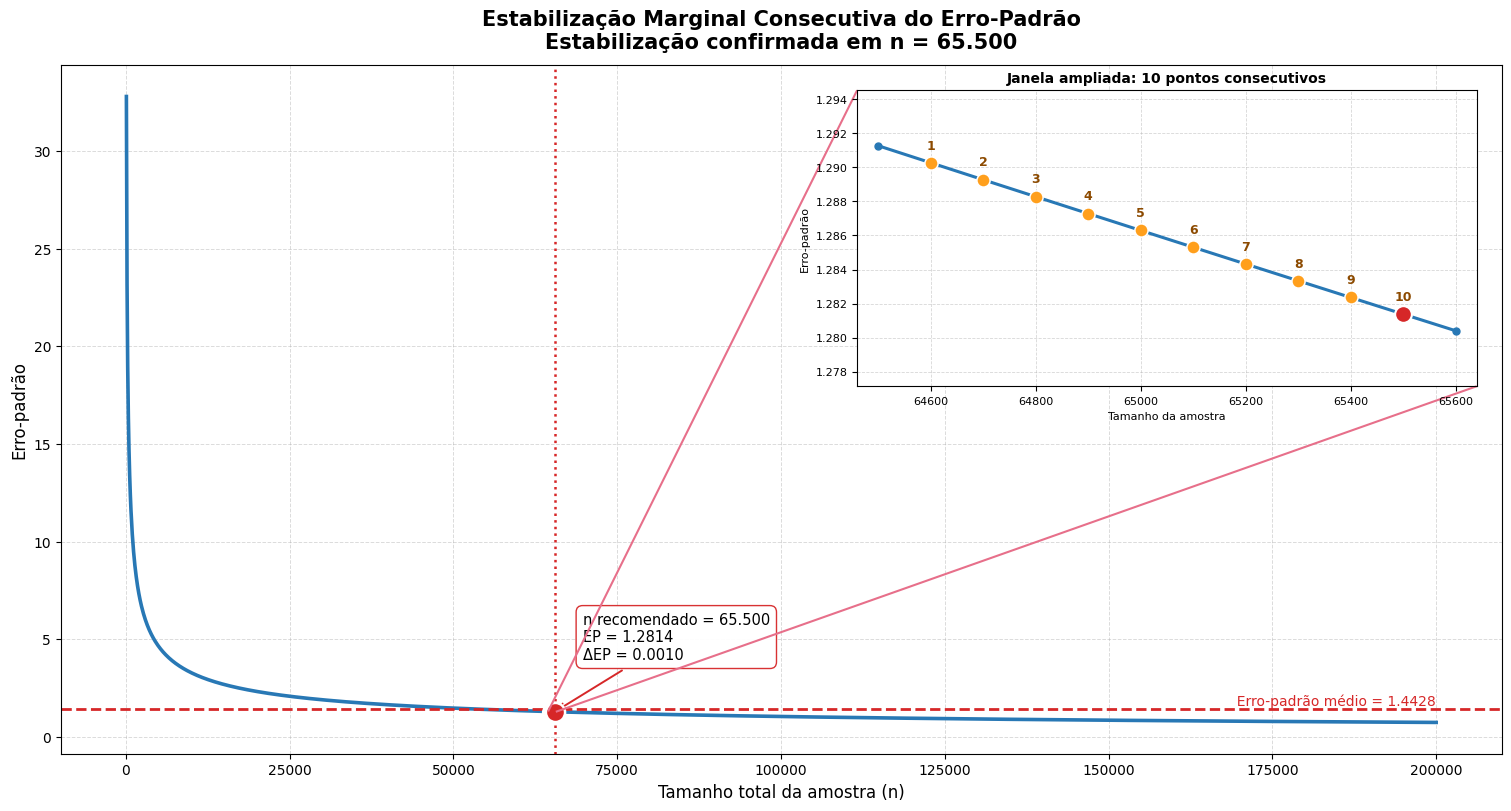


Procedimento empírico: VIP


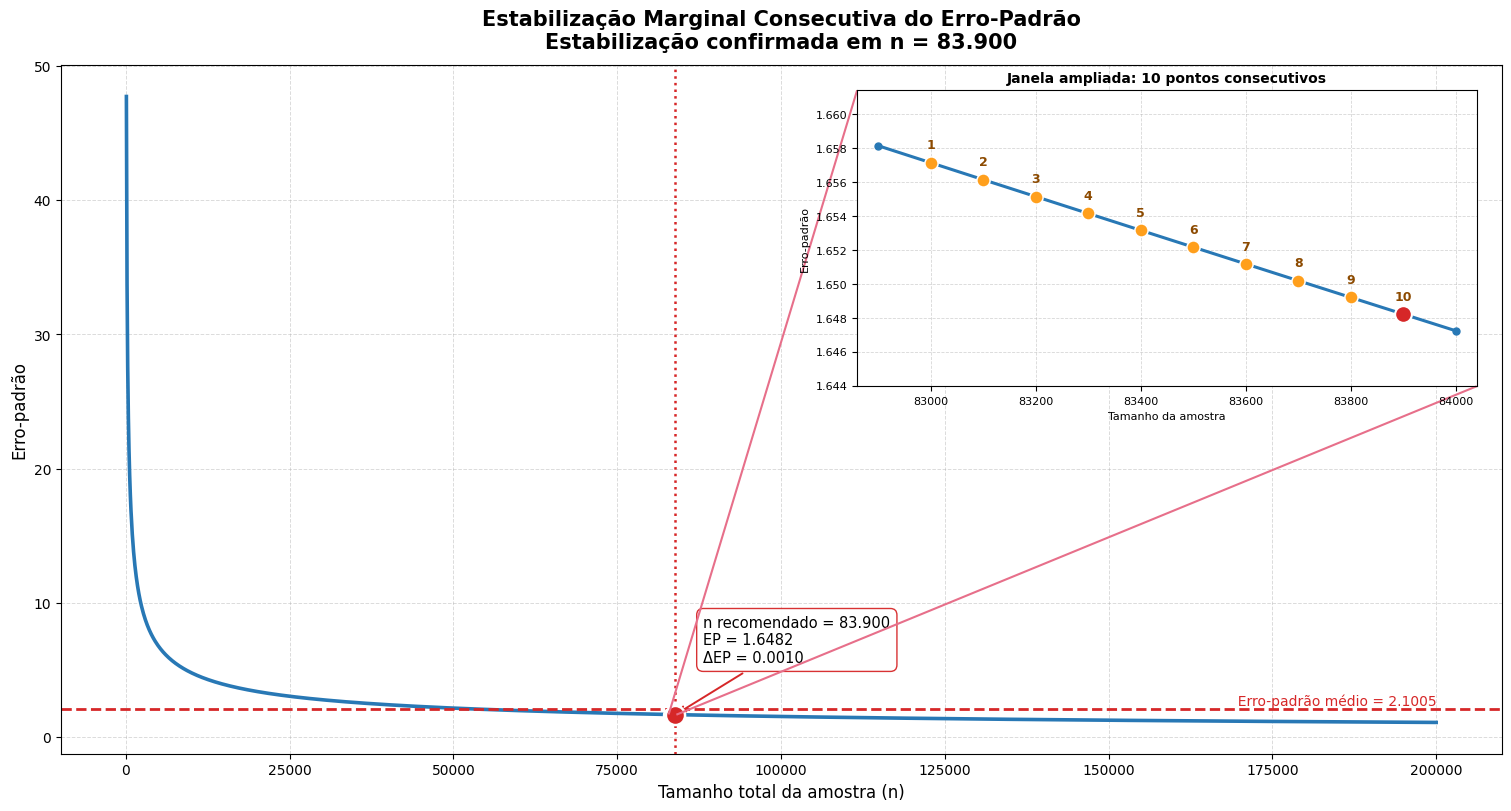


Procedimento empírico: PRIME


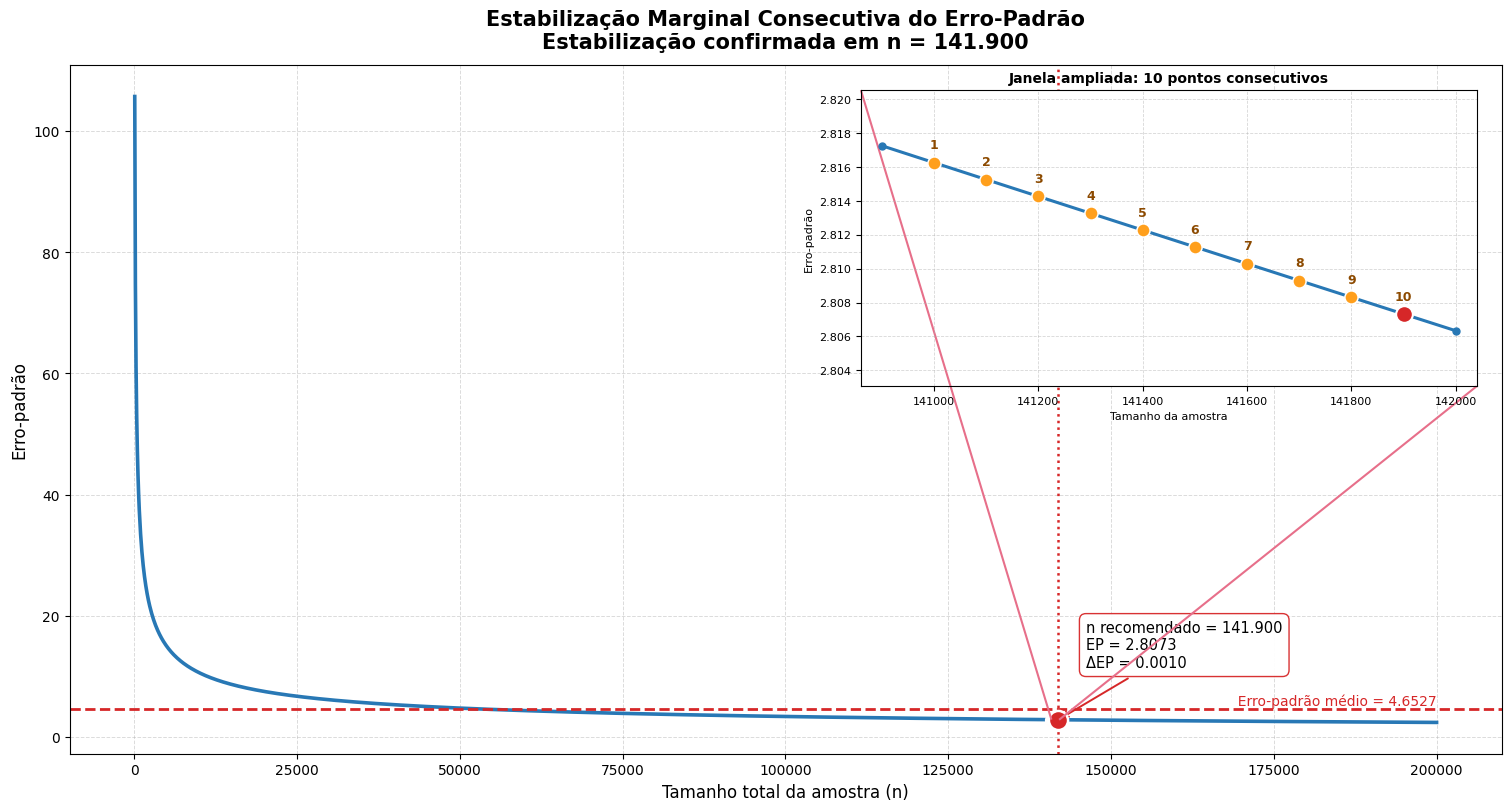


Procedimento empírico: GERAL


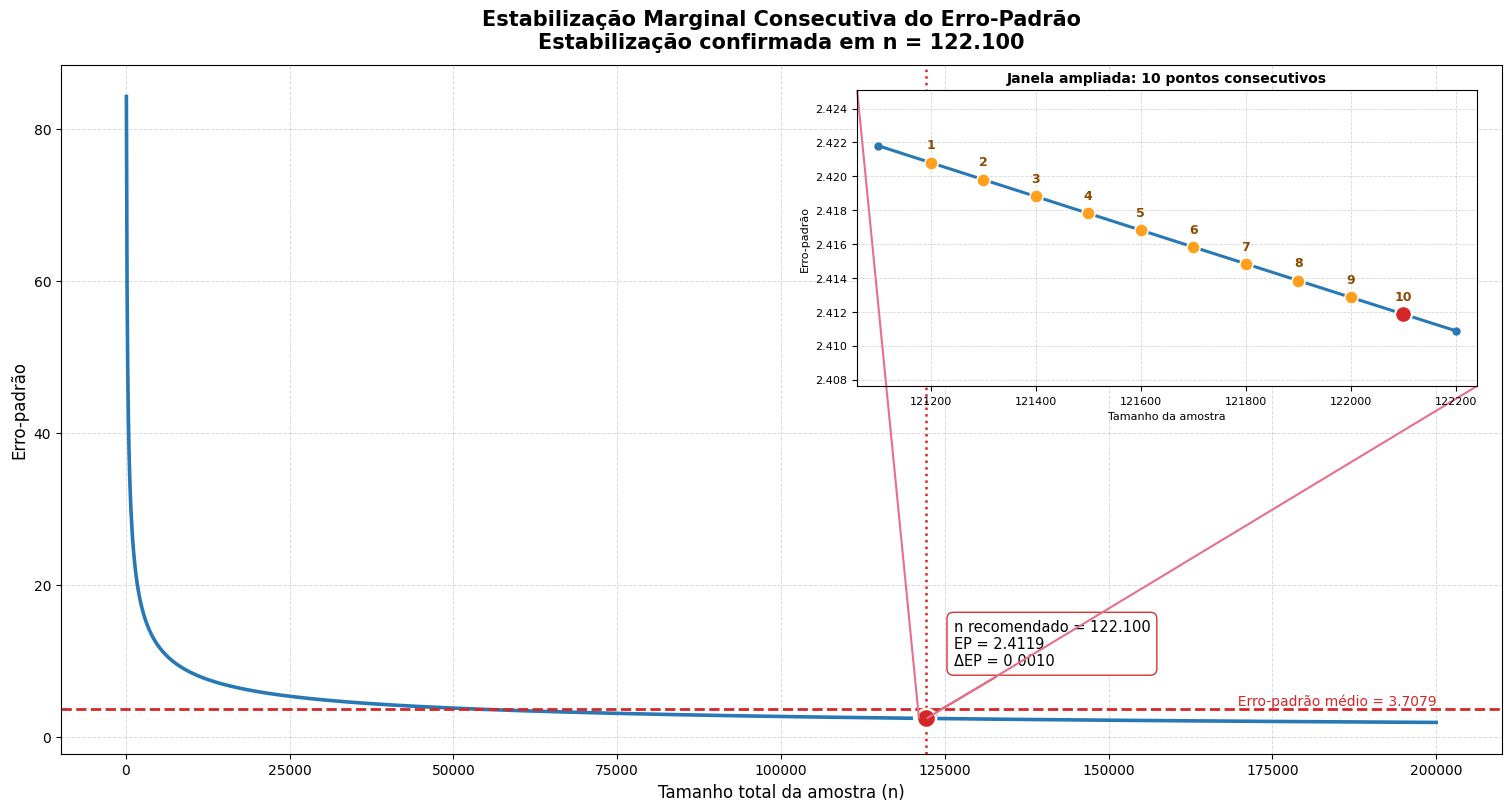


Procedimento teórico-empírico: estratificado com alocação de Neyman


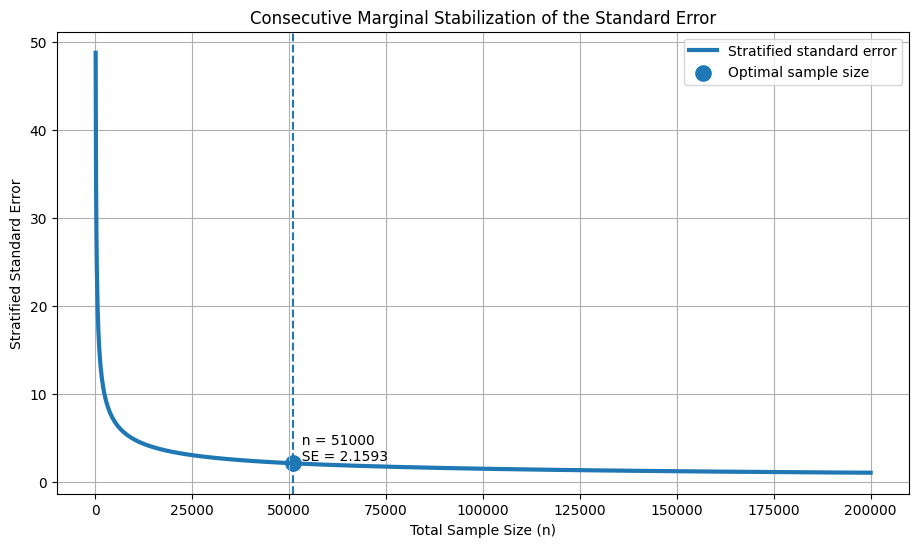


Resumo dos cinco resultados


,procedimento,grupo,desvio_padrao,inicio_estabilizacao,n_recomendado,erro_padrao_no_n
0,Empírico (erro padrão),ESSENTIAL,327.9431,"64,600.0000",65500,1.2814
1,Empírico (erro padrão),VIP,477.4157,"83,000.0000",83900,1.6482
2,Empírico (erro padrão),PRIME,"1,057.5067","141,000.0000",141900,2.8073
3,Empírico (erro padrão),GERAL,842.7760,"121,200.0000",122100,2.4119
4,Teórico-empírico (Neyman),ESTRATIFICADO,NaN,NaN,51000,2.1593



Alocação de Neyman no tamanho encontrado por esse procedimento


,Stratum,Population Weight (Wh),Std. Deviation (Sh),Neyman Weight (Wh x Sh),Allocated Sample (nh),Allocated Sample (%)
0,ESSENTIAL,0.5952,327.9431,195.1953,20414,0.4003
1,PRIME,0.1710,"1,057.5067",180.8393,18913,0.3708
2,VIP,0.2338,477.4157,111.6121,11673,0.2289



Tamanho ideal da amostra: 141,900 notas fiscais (Empírico (erro padrão), grupo PRIME).


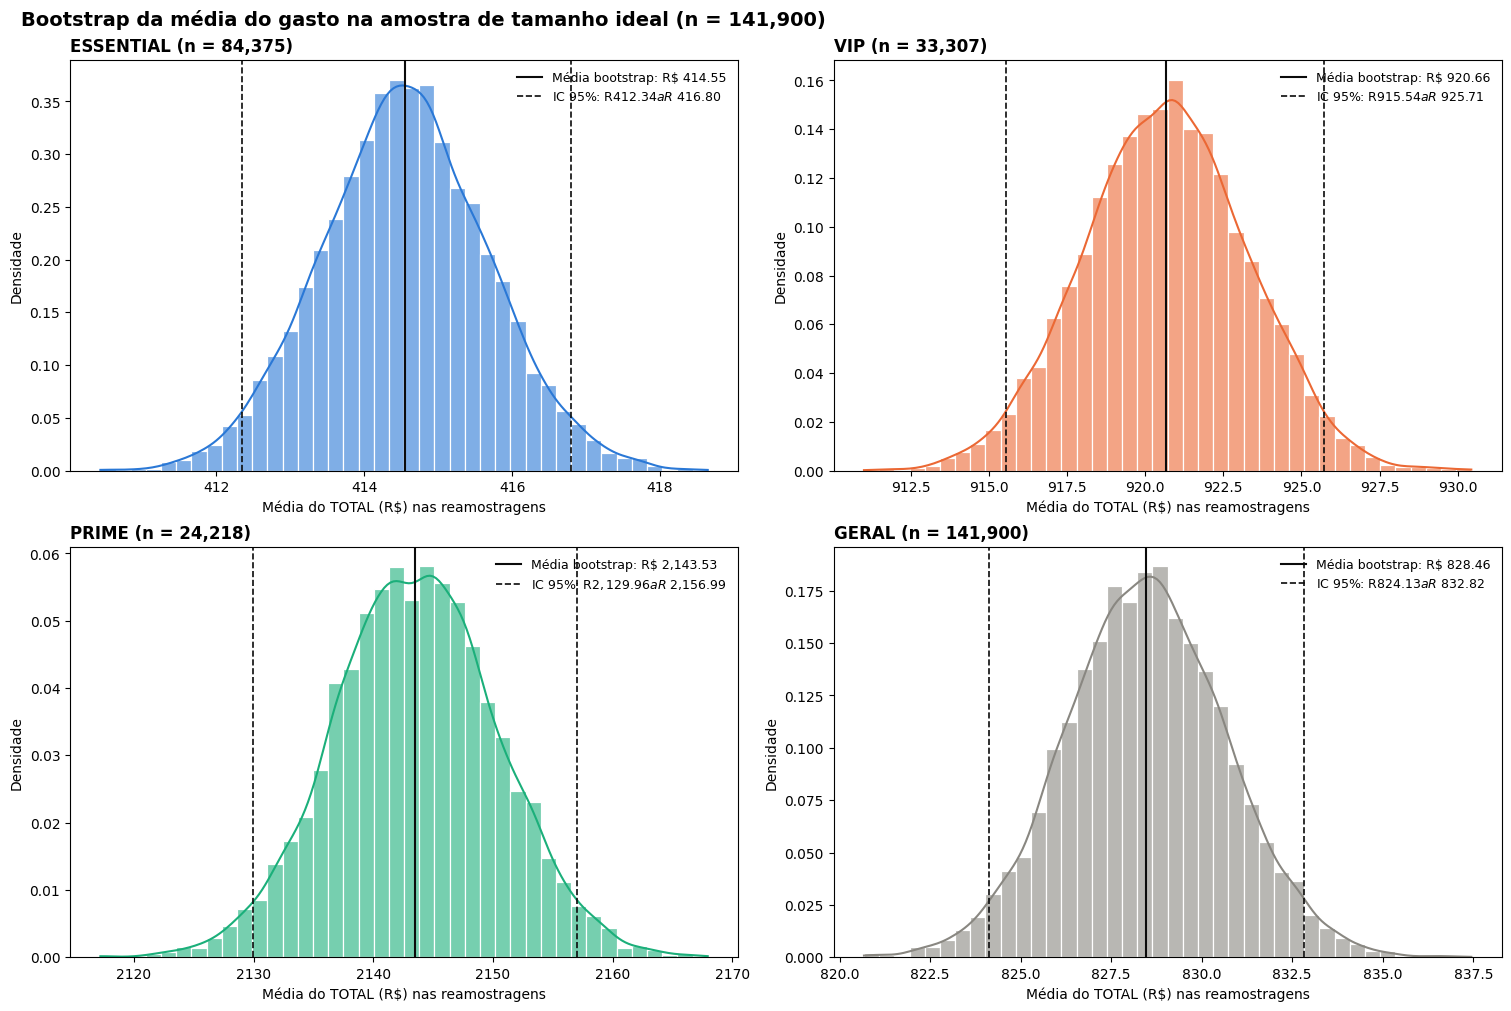


Análise bootstrap: intervalo de confiança e erro padrão


,n,media_amostral,ic_inferior,ic_superior,amplitude_ic,erro_padrao_bootstrap,erro_padrao_teorico
grupo,,,,,,,
ESSENTIAL,84375,414.5501,412.3413,416.7955,4.4542,1.1245,1.1202
VIP,33307,920.6280,915.5445,925.7101,10.1657,2.6237,2.6329
PRIME,24218,"2,143.7183","2,129.9647","2,156.9939",27.0292,6.8492,6.8135
GERAL,141900,828.4538,824.1332,832.8177,8.6845,2.2118,2.2339


In [24]:
# Executa a Atividade A1.1 e guarda os resultados para as próximas etapas
resultado_A1_1 = AtividadeA1_1()

### Resultados da A1.1

**Procedimento empírico (estabilização marginal do erro padrão, limiar de R\$ 0,001 com 10 pontos consecutivos):**

| Grupo | Desvio padrão (R\$) | Tamanho recomendado | Erro padrão no ponto (R\$) |
|---|---|---|---|
| ESSENTIAL | 327,94 | 65.500 | 1,28 |
| VIP | 477,42 | 83.900 | 1,65 |
| PRIME | 1.057,51 | **141.900** | 2,81 |
| GERAL | 842,78 | 122.100 | 2,41 |

**Procedimento teórico-empírico (Neyman):** estabilização em 51.000 notas, com erro padrão estratificado de R\$ 2,16. A alocação de Neyman distribui a amostra em 40% ESSENTIAL, 37% PRIME e 23% VIP. O PRIME recebe mais que o seu peso na população (17%) porque tem o maior desvio padrão. Como nesse procedimento o limiar é relativo (0,1% de redução), o ponto de estabilização depende principalmente do passo e do limiar escolhidos, e não da variabilidade dos dados. Por isso ele fica próximo de 50.000 em qualquer base.

**Tamanho ideal da amostra: 141.900 notas fiscais**, o maior dos cinco resultados (PRIME, o estrato de maior variabilidade). Esse tamanho atende a todos os outros grupos.

**Análise bootstrap (9.999 reamostragens, IC de 95%) na amostra de 141.900 notas:**

| Grupo | n | Média (R\$) | IC 95% (R\$) | Margem relativa | Erro padrão bootstrap | Erro padrão teórico |
|---|---|---|---|---|---|---|
| ESSENTIAL | 84.375 | 414,55 | 412,34 a 416,80 | ±0,54% | 1,12 | 1,12 |
| VIP | 33.307 | 920,63 | 915,54 a 925,71 | ±0,55% | 2,62 | 2,63 |
| PRIME | 24.218 | 2.143,72 | 2.129,96 a 2.156,99 | ±0,63% | 6,85 | 6,81 |
| GERAL | 141.900 | 828,45 | 824,13 a 832,82 | ±0,52% | 2,21 | 2,23 |

As distribuições bootstrap das médias têm formato de sino, como prevê o Teorema Central do Limite, e o erro padrão bootstrap praticamente coincide com o teórico (σ/√n). Os quatro intervalos de confiança contêm a média da base completa (R\$ 415,62, R\$ 919,49, R\$ 2.149,33 e R\$ 829,89). Isso confirma que uma amostra de 141.900 notas representa bem a população, com precisão parecida em todos os grupos (margem entre ±0,52% e ±0,63% da média).

In [25]:
help(AtividadeA1_1)

Help on function AtividadeA1_1 in module __main__:

AtividadeA1_1(
    df=None,
    alvo='TOTAL (R$)',
    estrato='TIPO DA CONTA',
    n_max=200000,
    passo=100,
    limiar=0.001,
    pontos_consecutivos=10,
    confianca=0.95,
    semente=42
)
    HELP: Atividade A1.1, determinação do tamanho ideal da amostra.

    O que a função faz, em ordem:
    1. Procedimento empírico (optimal_sample_size): curva de estabilização do erro padrão
       do gasto para ESSENTIAL, VIP, PRIME e GERAL, em 4 gráficos.
    2. Procedimento teórico-empírico (optimal_stratified_sample_size): erro padrão
       estratificado com alocação ótima de Neyman, em 1 gráfico.
    3. Define o tamanho ideal como o maior dos cinco resultados.
    4. Sorteia uma amostra com o tamanho ideal e faz a análise bootstrap da média do gasto
       em cada grupo, com intervalo de confiança e erro padrão.

    Parâmetros
    df: base usada como referência da população. Se não for informada, usa a table42_limpa.
    alvo: variáv

###Atividade A1.2: Analisar os outliers

**Como conduzi a A1.2**

Analisei os outliers do gasto (TOTAL R\$) na amostra de tamanho ideal sorteada na A1.1, com 141.900 notas.

1. **Critério:** IQR (1,5 vez a distância interquartil, o mesmo critério do boxplot), calculado **dentro de cada tipo de conta**. Se os estratos fossem misturados, notas PRIME seriam apontadas como outliers só por gastarem mais.
2. **Visualização:** boxplot por estrato e histogramas em escala normal (formato da distribuição) e logarítmica (caudas, onde os outliers aparecem), com os limites do IQR marcados.
3. **Impacto:** comparei média, desvio padrão e tamanho recomendado pelo procedimento empírico com e sem os outliers, para decidir se o tamanho ideal precisa ser recalculado.
4. **Visão geral:** percentual de outliers de todas as variáveis quantitativas em cada estrato.

Limites do IQR por estrato


,limite_inferior,limite_superior
ESSENTIAL,-151.2925,888.0075
VIP,-374.6025,"2,124.6975"
PRIME,"-1,344.1150","5,584.5650"


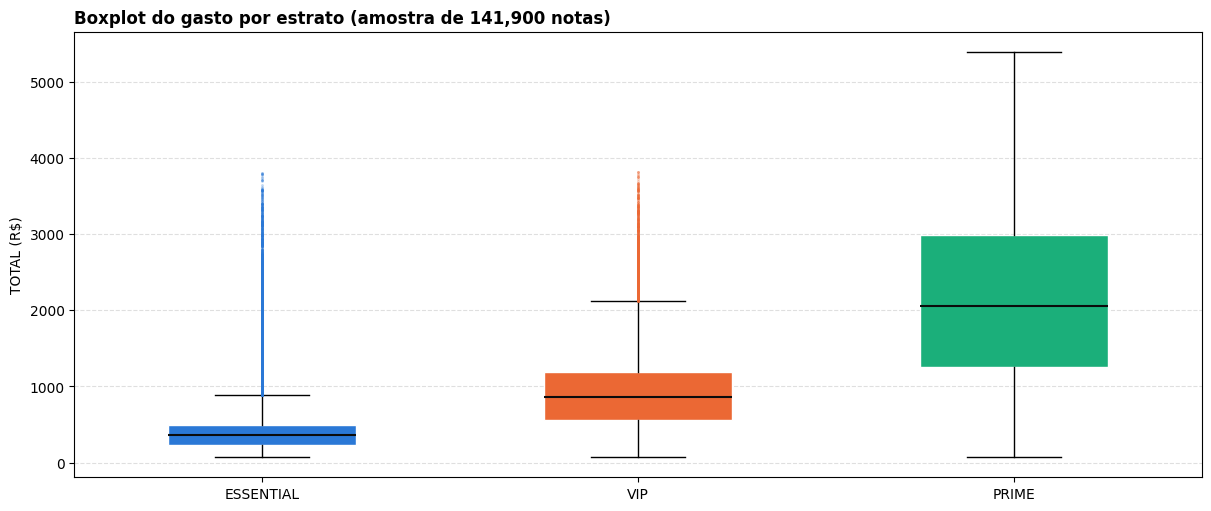

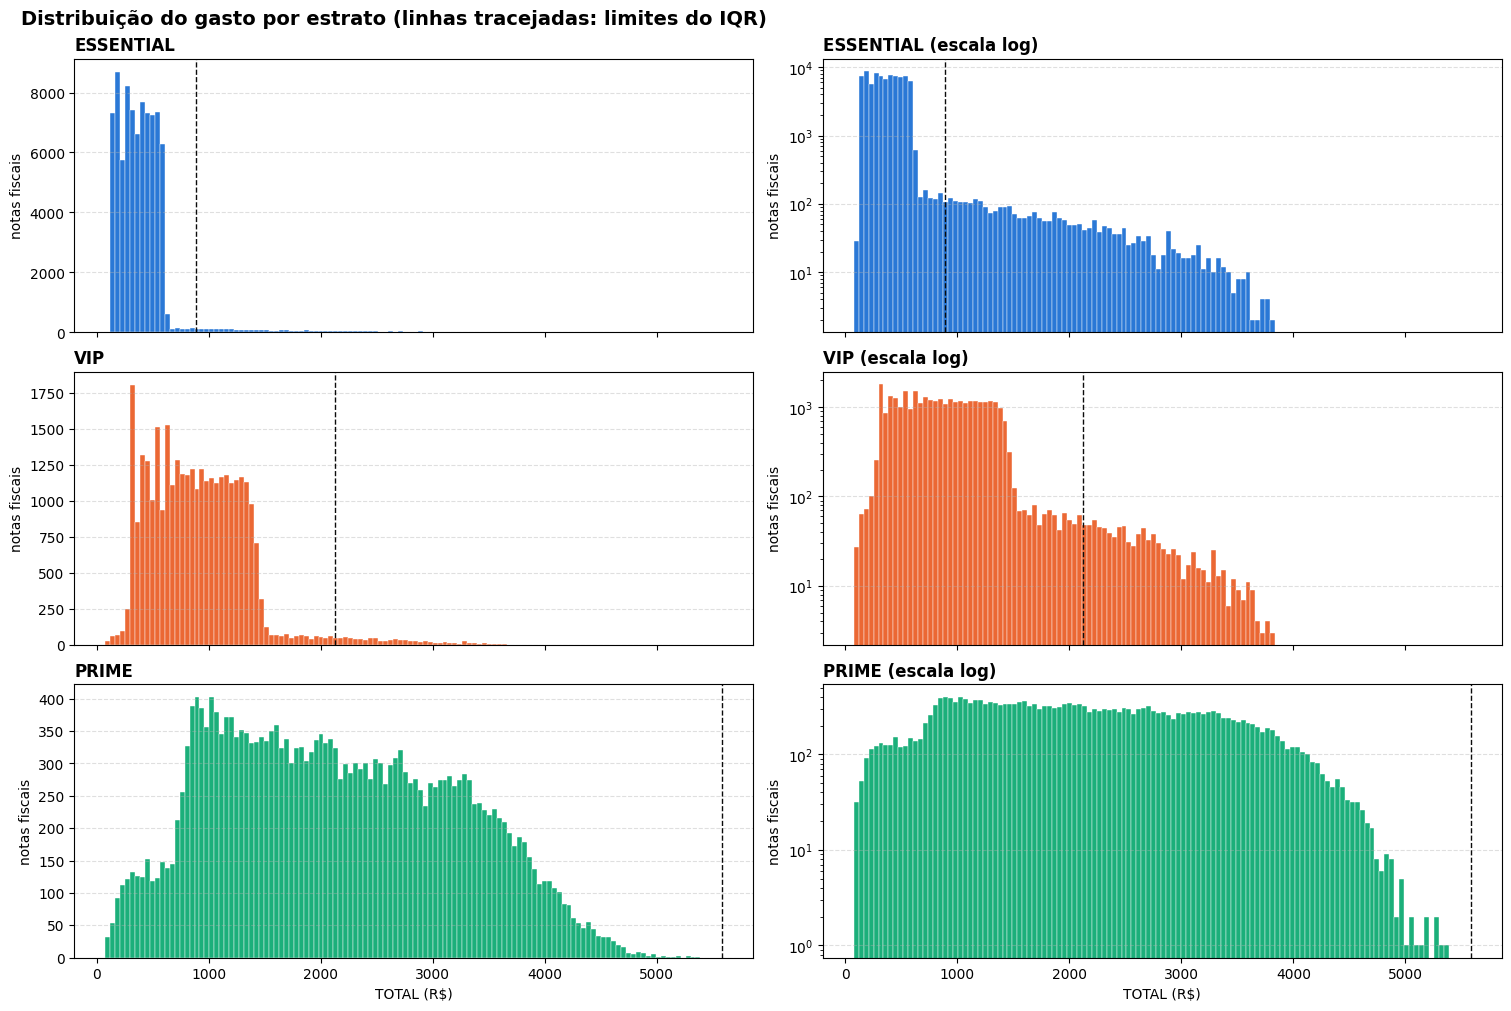


Impacto dos outliers no gasto e no tamanho recomendado


,n,outliers,%_outliers,media_com,media_sem,dif_media_%,desvio_com,desvio_sem,n_recomendado_com,n_recomendado_sem
grupo,,,,,,,,,,
ESSENTIAL,84375,3093,3.6658,414.5501,363.3575,-12.3490,325.3919,145.4808,65200,38500
VIP,33307,945,2.8372,920.6280,868.8405,-5.6252,480.5152,371.6807,84300,71200
PRIME,24218,0,0.0000,"2,143.7183","2,143.7183",0.0000,"1,060.3283","1,060.3283",142100,142100
GERAL,141900,4038,2.8457,828.4538,794.7687,-4.0660,841.5081,820.4167,122000,119900



Tamanho ideal pelo procedimento empírico: 142,100 com outliers e 142,100 sem outliers.

Percentual de outliers (IQR) por variável e estrato


,ESSENTIAL,VIP,PRIME
TOTAL (R$),3.6700,2.8400,0.0000
RENDA BRUTO (R$),6.3200,14.7700,11.0700
MEAN: alcohol,0.6500,0.7700,0.8900
MEAN: malic_acid,0.4300,0.3900,0.3400
MEAN: ash,0.6200,0.5600,0.7100
MEAN: alcalinity_of_ash,0.6800,0.6200,0.6900
MEAN: magnesium,0.7300,0.6800,0.6900
MEAN: total_phenols,0.6300,0.5900,0.6600
MEAN: flavanoids,0.3700,0.3500,0.3800
MEAN: nonflavanoid_phenols,0.5900,0.5300,0.4800


In [26]:
# Executa a Atividade A1.2 sobre a amostra de tamanho ideal da A1.1
resultado_A1_2 = AtividadeA1_2()

### Resultados da A1.2

**Limites do IQR por estrato (gasto, TOTAL R\$):** ESSENTIAL até R\$ 888,01, VIP até R\$ 2.124,70 e PRIME até R\$ 5.584,57. Os limites inferiores são negativos, então só existem outliers acima do limite superior.

| Grupo | Outliers | % | Média com → sem (R\$) | Desvio com → sem (R\$) | Tamanho recomendado com → sem |
|---|---|---|---|---|---|
| ESSENTIAL | 3.093 | 3,67% | 414,55 → 363,36 (−12,3%) | 325,39 → 145,48 | 65.200 → 38.500 |
| VIP | 945 | 2,84% | 920,63 → 868,84 (−5,6%) | 480,52 → 371,68 | 84.300 → 71.200 |
| PRIME | 0 | 0,00% | 2.143,72 (sem mudança) | 1.060,33 (sem mudança) | 142.100 → 142.100 |
| GERAL | 4.038 | 2,85% | 828,45 → 794,77 (−4,1%) | 841,51 → 820,42 | 122.000 → 119.900 |

**O que os gráficos mostram:** na escala logarítmica aparece um "piso" de notas espalhadas de forma quase uniforme entre cerca de R\$ 70 e R\$ 3.800 no ESSENTIAL e no VIP. É o padrão de erro aleatório inserido na base, o mesmo do createTable do material do professor. O IQR só detecta a parte desse piso que fica acima do limite superior. A parte que cai dentro da faixa normal do estrato não pode ser separada por esse critério. No PRIME, a faixa de gasto é tão larga que a contaminação fica toda escondida dentro dela, e nenhum outlier é apontado.

**Os outliers mudam o tamanho ideal?** Não. Eles afetam muito o ESSENTIAL (o desvio padrão cai 55% sem eles) e o VIP, mas o tamanho ideal é definido pelo PRIME, que não tem outliers pelo IQR. Com ou sem outliers, o procedimento empírico indica cerca de 142 mil notas. A pequena diferença em relação às 141.900 da A1.1 vem do desvio calculado na amostra, e não na base completa. **O tamanho ideal de 141.900 notas se mantém, e não é preciso recalcular.**

**Decisão:** mantive os outliers na amostra para as próximas etapas. O objetivo do Módulo 1 é caracterizar a população como ela é, e as amostras retiradas dela sempre vão conter essa contaminação. Além disso, a remoção pelo IQR seria só parcial. Os outliers ficam marcados para serem tratados na modelagem do Módulo 2.

**Outras variáveis:** a renda tem muitos outliers (6% a 15%), seguindo o mesmo padrão de contaminação do gasto. As 13 variáveis do vinho têm entre 0,3% e 0,9%, valor esperado para dados com distribuição normal (cerca de 0,7%). As que tiveram valores negativos removidos na preparação ficam perto da metade disso, porque a cauda inferior foi cortada.

In [27]:
help(AtividadeA1_2)

Help on function AtividadeA1_2 in module __main__:

AtividadeA1_2(
    amostra=None,
    alvo='TOTAL (R$)',
    estrato='TIPO DA CONTA',
    k=1.5,
    n_max=200000,
    passo=100,
    limiar=0.001,
    pontos_consecutivos=10
)
    HELP: Atividade A1.2, análise dos outliers na amostra de tamanho ideal.

    O que a função faz, em ordem:
    1. Calcula os limites de outlier pelo critério do IQR dentro de cada tipo de conta.
       Misturar os estratos faria notas PRIME parecerem outliers só por gastarem mais.
    2. Mostra o boxplot do gasto por estrato e os histogramas em escala normal e
       logarítmica, com os limites do IQR marcados.
    3. Mede quanto os outliers mudam a média, o desvio padrão e o tamanho recomendado
       pelo procedimento empírico da A1.1, para decidir se é preciso recalcular o tamanho ideal.
    4. Resume o percentual de outliers de todas as variáveis quantitativas por estrato.

    Parâmetros
    amostra: amostra analisada. Se não for informada, usa a amostr

###Atividade A1.3: Testes de Hipóteses ([Link](https://colab.research.google.com/drive/1_YGamH-qOWSNaCKG5kVlLiZPuXv5lT34?usp=sharing))

**Como conduzi a A1.3**

Sorteei duas amostras independentes da base tratada, SAMPLE 1 e SAMPLE 2, cada uma com o tamanho ideal de 141.900 notas definido na A1.1. As duas não têm nenhuma nota fiscal em comum. Todos os testes a seguir comparam essas duas amostras, usando o gasto (TOTAL R\$) como variável.

In [28]:
# Sorteio do SAMPLE 1 e do SAMPLE 2 com o tamanho ideal da A1.1
resultado_A1_3 = AtividadeA1_3()

SAMPLE 1: 141,900 notas | SAMPLE 2: 141,900 notas | notas em comum: 0


SAMPLE 1                           SAMPLE 2                      
                     count       mean        std        count       mean        std
TIPO DA CONTA                                                                      
ESSENTIAL      84,477.0000   413.8487   324.1451  84,539.0000   418.0250   331.6795
PRIME          24,150.0000 2,156.5499 1,058.7052  24,174.0000 2,149.5359 1,051.5044
VIP            33,273.0000   918.1418   477.2223  33,187.0000   927.0763   482.8712
GERAL         141,900.0000   828.6871   843.2768 141,900.0000   832.0590   841.6457

### Amostras sorteadas

Foram sorteadas duas amostras de 141.900 notas, sem nenhuma nota fiscal em comum. A composição e o gasto por estrato ficaram praticamente iguais nas duas:

| Grupo | SAMPLE 1: n / média (R\$) | SAMPLE 2: n / média (R\$) |
|---|---|---|
| ESSENTIAL | 84.477 / 413,85 | 84.539 / 418,03 |
| VIP | 33.273 / 918,14 | 33.187 / 927,08 |
| PRIME | 24.150 / 2.156,55 | 24.174 / 2.149,54 |
| GERAL | 141.900 / 828,69 | 141.900 / 832,06 |

As médias das duas amostras ficaram muito próximas entre si e da média da base completa, com diferenças de no máximo 1% em todos os grupos.

#### A1.3.1: Teste de Normalidade

Nesta ETAPA, você deve fazer o **TESTE DE HIPÓTESE DE NORMALIDADE: Anderson-Darling' Test (AD test)** sobre:

*   SAMPLE 1:
*   SAMPLE 2:

**Como conduzi o A1.3.1**

Apliquei o teste de Anderson-Darling dentro de cada tipo de conta, nas duas amostras, porque a normalidade esperada é a de cada estrato, e não a do conjunto geral. O GERAL entra só como referência. Além da função do professor, que compara a estatística com os valores críticos, calculei o p-valor do teste, a assimetria e a curtose. Também refiz o teste numa subamostra de 5.000 notas, como faz a função normalChart do material do professor, porque com amostras muito grandes o teste aponta como "não normal" até diferenças mínimas.


SAMPLE 1 | ESSENTIAL (n = 84,477)
DISTRIBUIÇÃO AMOSTRAL: stat = 7201.473
Intervalo de Confiança (15.0 %): Probably Not Gaussian.
Intervalo de Confiança (10.0 %): Probably Not Gaussian.
Intervalo de Confiança (5.0 %): Probably Not Gaussian.
Intervalo de Confiança (2.5 %): Probably Not Gaussian.
Intervalo de Confiança (1.0 %): Probably Not Gaussian.

SAMPLE 1 | VIP (n = 33,273)
DISTRIBUIÇÃO AMOSTRAL: stat = 495.877
Intervalo de Confiança (15.0 %): Probably Not Gaussian.
Intervalo de Confiança (10.0 %): Probably Not Gaussian.
Intervalo de Confiança (5.0 %): Probably Not Gaussian.
Intervalo de Confiança (2.5 %): Probably Not Gaussian.
Intervalo de Confiança (1.0 %): Probably Not Gaussian.

SAMPLE 1 | PRIME (n = 24,150)
DISTRIBUIÇÃO AMOSTRAL: stat = 154.961
Intervalo de Confiança (15.0 %): Probably Not Gaussian.
Intervalo de Confiança (10.0 %): Probably Not Gaussian.
Intervalo de Confiança (5.0 %): Probably Not Gaussian.
Intervalo de Confiança (2.5 %): Probably Not Gaussian.
Intervalo de C

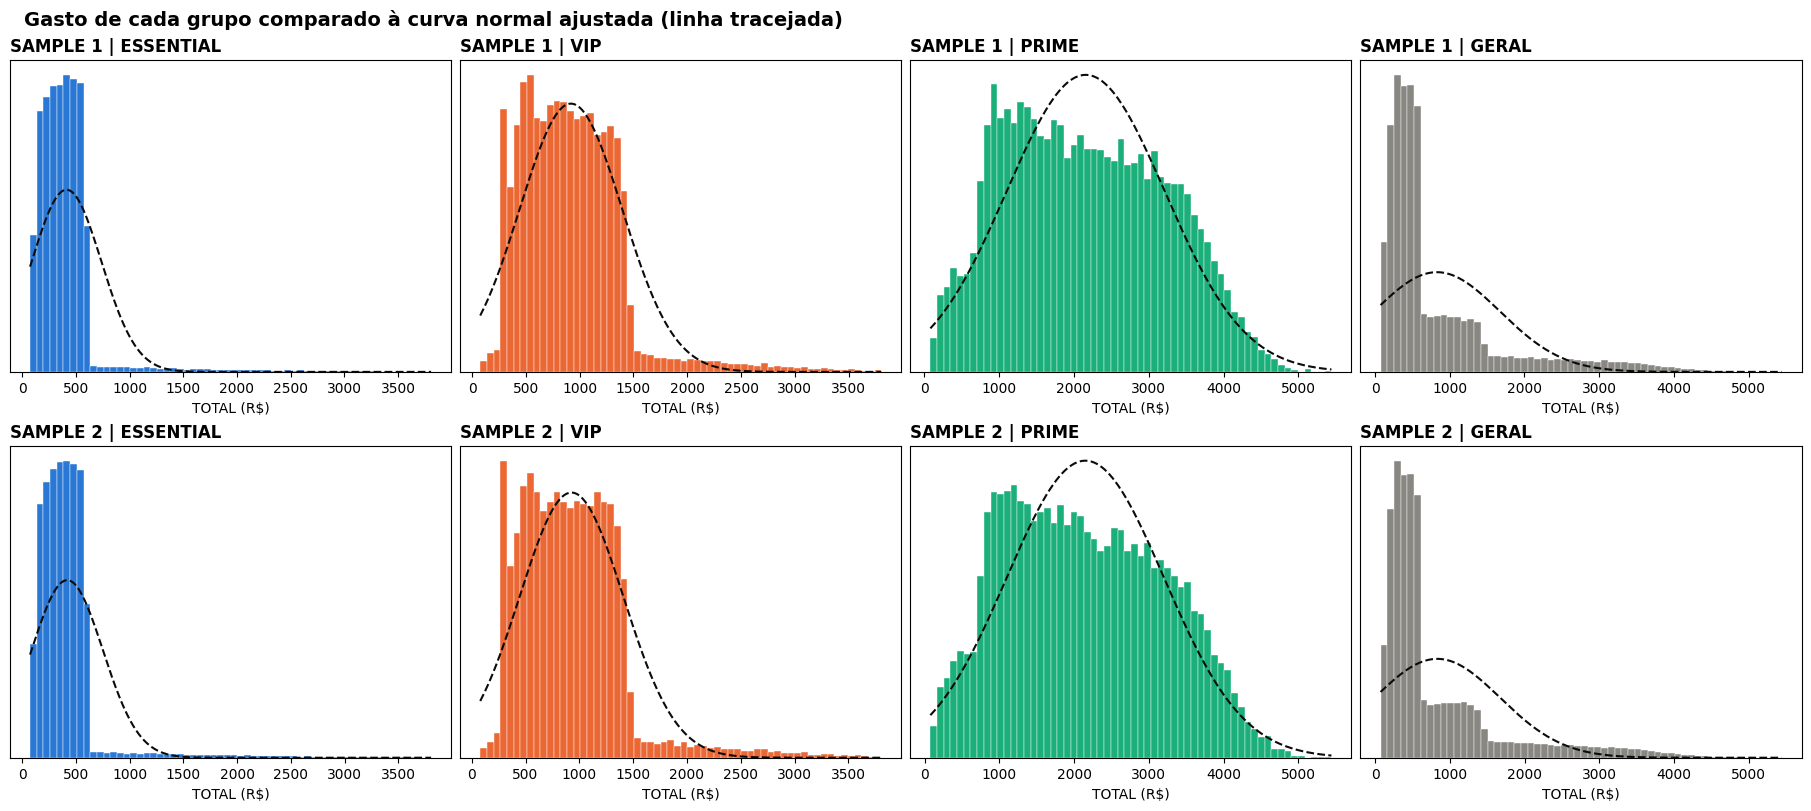


Resumo do teste de normalidade de Anderson-Darling


,amostra,grupo,n,estatistica_AD,p_valor,p_valor_subamostra_5000,assimetria,curtose,normal_pelo_teste_5%,normal_pela_subamostra_5%,normal_pela_heuristica
0,SAMPLE 1,ESSENTIAL,84477,"7,201.4728",0.0000,0.0000,4.7537,30.7677,False,False,False
1,SAMPLE 1,VIP,33273,495.8765,0.0000,0.0000,1.6145,5.0835,False,False,False
2,SAMPLE 1,PRIME,24150,154.9609,0.0000,0.0000,0.1978,-0.8783,False,False,False
3,SAMPLE 1,GERAL,141900,"13,508.6629",0.0000,0.0000,2.0511,3.8675,False,False,False
4,SAMPLE 2,ESSENTIAL,84539,"7,531.4481",0.0000,0.0000,4.6567,28.9931,False,False,False
5,SAMPLE 2,VIP,33187,500.2163,0.0000,0.0000,1.5938,4.9247,False,False,False
6,SAMPLE 2,PRIME,24174,149.0617,0.0000,0.0000,0.2103,-0.8574,False,False,False
7,SAMPLE 2,GERAL,141900,"13,312.2936",0.0000,0.0000,2.0311,3.7921,False,False,False


In [29]:
# Teste de normalidade de Anderson-Darling no SAMPLE 1 e no SAMPLE 2
resultado_A1_3_1 = AtividadeA1_3_1()

### Resultado do teste de normalidade

**Nenhum grupo segue uma distribuição normal, em nenhuma das duas amostras.** O teste de Anderson-Darling rejeitou a normalidade com p-valor ≈ 0 na amostra inteira e também na subamostra de 5.000 notas. Isso mostra que a rejeição não vem só do tamanho da amostra. O critério heurístico (assimetria e curtose entre −0,5 e 0,5) chega à mesma conclusão.

| Grupo | Assimetria (S1 / S2) | Curtose (S1 / S2) | Formato observado |
|---|---|---|---|
| ESSENTIAL | 4,75 / 4,66 | 30,8 / 29,0 | bloco achatado entre ~R\$ 130 e ~R\$ 620 + cauda longa à direita |
| VIP | 1,61 / 1,59 | 5,08 / 4,92 | corpo achatado + cauda à direita |
| PRIME | 0,20 / 0,21 | −0,88 / −0,86 | quase simétrico, mas achatado (platicúrtico) |
| GERAL | 2,05 / 2,03 | 3,87 / 3,79 | mistura dos três estratos, como esperado |

Dois fatores explicam o resultado. O primeiro é a contaminação aleatória identificada na A1.2, que cria caudas longas no ESSENTIAL e no VIP. O segundo é que o corpo de cada estrato é mais achatado que uma curva normal, o que fica visível nos histogramas.

**O ponto mais importante para a qualidade da amostragem:** o SAMPLE 1 e o SAMPLE 2 têm praticamente as mesmas estatísticas de teste, assimetria e curtose em todos os grupos. As duas amostras reproduzem o mesmo formato de distribuição. Elas não são normais, mas são consistentes entre si, e é isso que indica que representam a mesma população.

**Consequência para os próximos testes:** como os dados não são normais, os testes não paramétricos (Mann-Whitney, Kruskal-Wallis, Kolmogorov-Smirnov) são os mais adequados para comparar as distribuições. Para comparar as médias, os testes paramétricos (t e ANOVA) continuam válidos. Com amostras deste tamanho, a média amostral segue distribuição normal pelo Teorema Central do Limite, como o bootstrap da A1.1 mostrou.

In [30]:
help(AtividadeA1_3_1)

Help on function AtividadeA1_3_1 in module __main__:

AtividadeA1_3_1(
    amostras=None,
    alvo='TOTAL (R$)',
    estrato='TIPO DA CONTA',
    tamanho_subamostra=5000,
    semente=42
)
    HELP: Atividade A1.3.1, teste de normalidade de Anderson-Darling no SAMPLE 1 e no SAMPLE 2.

    Para cada amostra e para cada tipo de conta (e o geral, como referência):
    1. Roda a função Normality_Test do professor, que compara a estatística de
       Anderson-Darling com os valores críticos de 15%, 10%, 5%, 2,5% e 1%.
    2. Calcula o p-valor do mesmo teste na amostra inteira e numa subamostra de 5.000 notas,
       porque com amostras muito grandes o teste rejeita a normalidade até por diferenças mínimas.
    3. Calcula a assimetria e a curtose e aplica o critério heurístico do material do professor
       (normal quando as duas ficam entre -0,5 e 0,5).
    4. Desenha o histograma de cada grupo com a curva normal de mesma média e desvio.

    Hipóteses do teste
    H0: os dados seguem uma d

#### A1.3.2: Teste de Independência

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Testes de Independência: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

**Como conduzi o A1.3.2**

Para testar se o SAMPLE 1 e o SAMPLE 2 são independentes, formei pares de notas: a 1ª nota do SAMPLE 1 com a 1ª do SAMPLE 2, e assim por diante. Como as amostras foram sorteadas em ordem aleatória, se forem independentes, o gasto de uma nota não deve ter relação nenhuma com o gasto do seu par.

Hipóteses: H0: as amostras são independentes (correlação igual a zero). H1: existe dependência. Com p-valor acima de 5%, não se rejeita H0.

Testes aplicados, no geral e dentro de cada tipo de conta:
- **Pearson:** correlação linear, que pressupõe dados aproximadamente normais;
- **Spearman e Kendall:** correlação por postos (rankings), que não exige normalidade e é robusta a outliers;
- **Qui-quadrado:** independência entre as faixas de gasto (decis) dos pares, corrigindo o uso do exemplo do Tópico II, que passava os dados brutos para a função;
- **ANOVA da regressão:** teste F que verifica se o gasto do SAMPLE 1 explica o do SAMPLE 2.

O **gráfico bootstrap** mostra a distribuição da correlação de Spearman em 2.000 reamostragens dos pares. Se o intervalo de confiança de 95% contém o zero, as amostras são independentes.

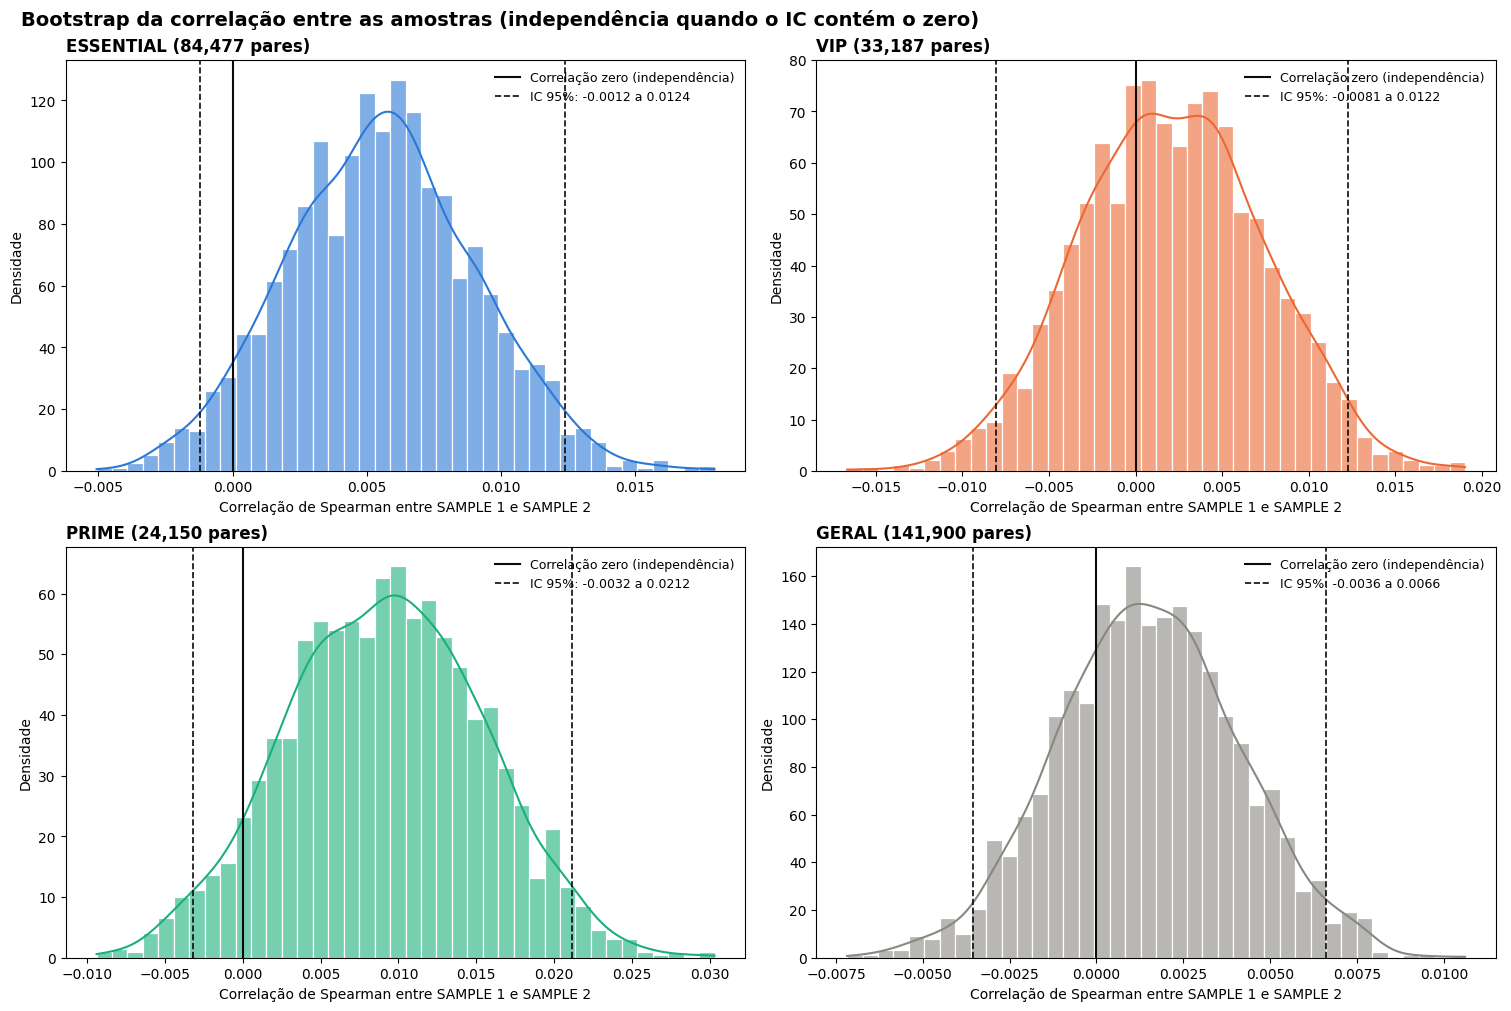


Testes de independência entre SAMPLE 1 e SAMPLE 2


,grupo,pares,teste,estatistica,p_valor,p_valor_%,conclusao_5%
0,ESSENTIAL,84477,Pearson,0.0047,0.1677,16.7655,Independentes
1,ESSENTIAL,84477,Spearman,0.0054,0.1179,11.7887,Independentes
2,ESSENTIAL,84477,Kendall,0.0036,0.1170,11.7020,Independentes
3,ESSENTIAL,84477,Qui-quadrado (decis),66.2052,0.8827,88.2694,Independentes
4,ESSENTIAL,84477,ANOVA da regressão (F),1.9038,0.1677,16.7655,Independentes
5,VIP,33187,Pearson,0.0039,0.4785,47.8490,Independentes
6,VIP,33187,Spearman,0.0022,0.6890,68.8997,Independentes
7,VIP,33187,Kendall,0.0015,0.6914,69.1377,Independentes
8,VIP,33187,Qui-quadrado (decis),85.7587,0.3376,33.7624,Independentes
9,VIP,33187,ANOVA da regressão (F),0.5023,0.4785,47.8490,Independentes



Bootstrap da correlação de Spearman


,spearman,ic_inferior,ic_superior,contem_zero
grupo,,,,
ESSENTIAL,0.0054,-0.0012,0.0124,True
VIP,0.0022,-0.0081,0.0122,True
PRIME,0.0089,-0.0032,0.0212,True
GERAL,0.0015,-0.0036,0.0066,True


In [31]:
# Testes de independência entre SAMPLE 1 e SAMPLE 2
resultado_A1_3_2 = AtividadeA1_3_2()

### Resultado do teste de independência

| Grupo | Pares | Pearson | Spearman | Kendall | Qui-quadrado | ANOVA da regressão | IC 95% bootstrap (Spearman) |
|---|---|---|---|---|---|---|---|
| ESSENTIAL | 84.477 | 16,8% | 11,8% | 11,7% | 88,3% | 16,8% | −0,0012 a 0,0124 |
| VIP | 33.187 | 47,8% | 68,9% | 69,1% | 33,8% | 47,8% | −0,0081 a 0,0122 |
| PRIME | 24.150 | 12,9% | 16,5% | 16,5% | 58,3% | 12,9% | −0,0032 a 0,0212 |
| GERAL | 141.900 | 70,0% | **58,1%** | 57,9% | 17,4% | 70,0% | −0,0036 a 0,0066 |

*(Valores das colunas de teste: p-valor.)*

Todos os 20 testes têm p-valor acima de 5%, e o menor deles é 11,7%. As correlações entre as amostras ficaram abaixo de 0,01 em todos os grupos, o que na prática é zero. Os quatro intervalos de confiança do bootstrap contêm o zero. A ANOVA da regressão deu exatamente o mesmo p-valor do Pearson, como esperado, porque com uma única variável explicativa os dois testes são equivalentes.

**Best fit:** o teste de **Spearman**. A A1.3.1 mostrou que o gasto não segue distribuição normal e tem caudas longas causadas pela contaminação. O Spearman trabalha com postos (rankings), não exige normalidade e não é afetado por outliers. O Kendall, da mesma família, confirma os resultados com p-valores quase idênticos. Pearson e ANOVA pressupõem normalidade e relação linear, e o qui-quadrado depende da escolha das faixas (decis), por isso ficam como confirmação.

**RESPONDER: SAMPLE 1 e SAMPLE 2 são INDEPENDENTES ???**

CONCLUIR / RESPONDER AQUI:
*   **Sim, o SAMPLE 1 e o SAMPLE 2 são independentes.** Pelo teste de melhor ajuste (Spearman), o p-valor no conjunto geral é de **58,1%**, muito acima do limite de 5%, e a correlação entre as amostras é de 0,0015, praticamente zero. Nos estratos, os p-valores de Spearman são 11,8% (ESSENTIAL), 68,9% (VIP) e 16,5% (PRIME), todos acima de 5%.
*   A conclusão é confirmada por todos os outros testes (Pearson, Kendall, qui-quadrado e ANOVA da regressão) e pelo bootstrap, cujo intervalo de confiança de 95% contém o zero nos quatro grupos. Isso garante que as duas amostras foram sorteadas sem influência uma da outra, condição necessária para os testes de distribuição e de médias a seguir.

#### A1.3.3: Teste de Distribuição

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste de Mesma Distribuição: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

**Como conduzi o A1.3.3**

Hipóteses: H0: o SAMPLE 1 e o SAMPLE 2 vêm da mesma distribuição. H1: as distribuições são diferentes. Com p-valor acima de 5%, não se rejeita H0.

Apliquei os testes do material do professor no geral e em cada tipo de conta:
- **Paramétricos:** t de Student, t pareado e ANOVA;
- **Não paramétricos:** Mann-Whitney U, Wilcoxon e Kruskal-Wallis;
- **Distribuição completa:** Kolmogorov-Smirnov e Anderson-Darling para k amostras.

Os seis primeiros comparam a posição (a média ou os postos) das amostras. Os dois últimos comparam a curva de distribuição inteira. O t pareado e o Wilcoxon foram feitos para amostras pareadas, como medidas antes e depois na mesma pessoa. Aqui as amostras são independentes, então eles aparecem só como referência.

**Gráficos:**
1. A distribuição acumulada (ECDF) das duas amostras sobreposta. Se as curvas coincidem, as distribuições são iguais.
2. O bootstrap da diferença entre as medianas (SAMPLE 1 − SAMPLE 2), com intervalo de confiança de 95%. Se ele contém o zero, não há diferença.

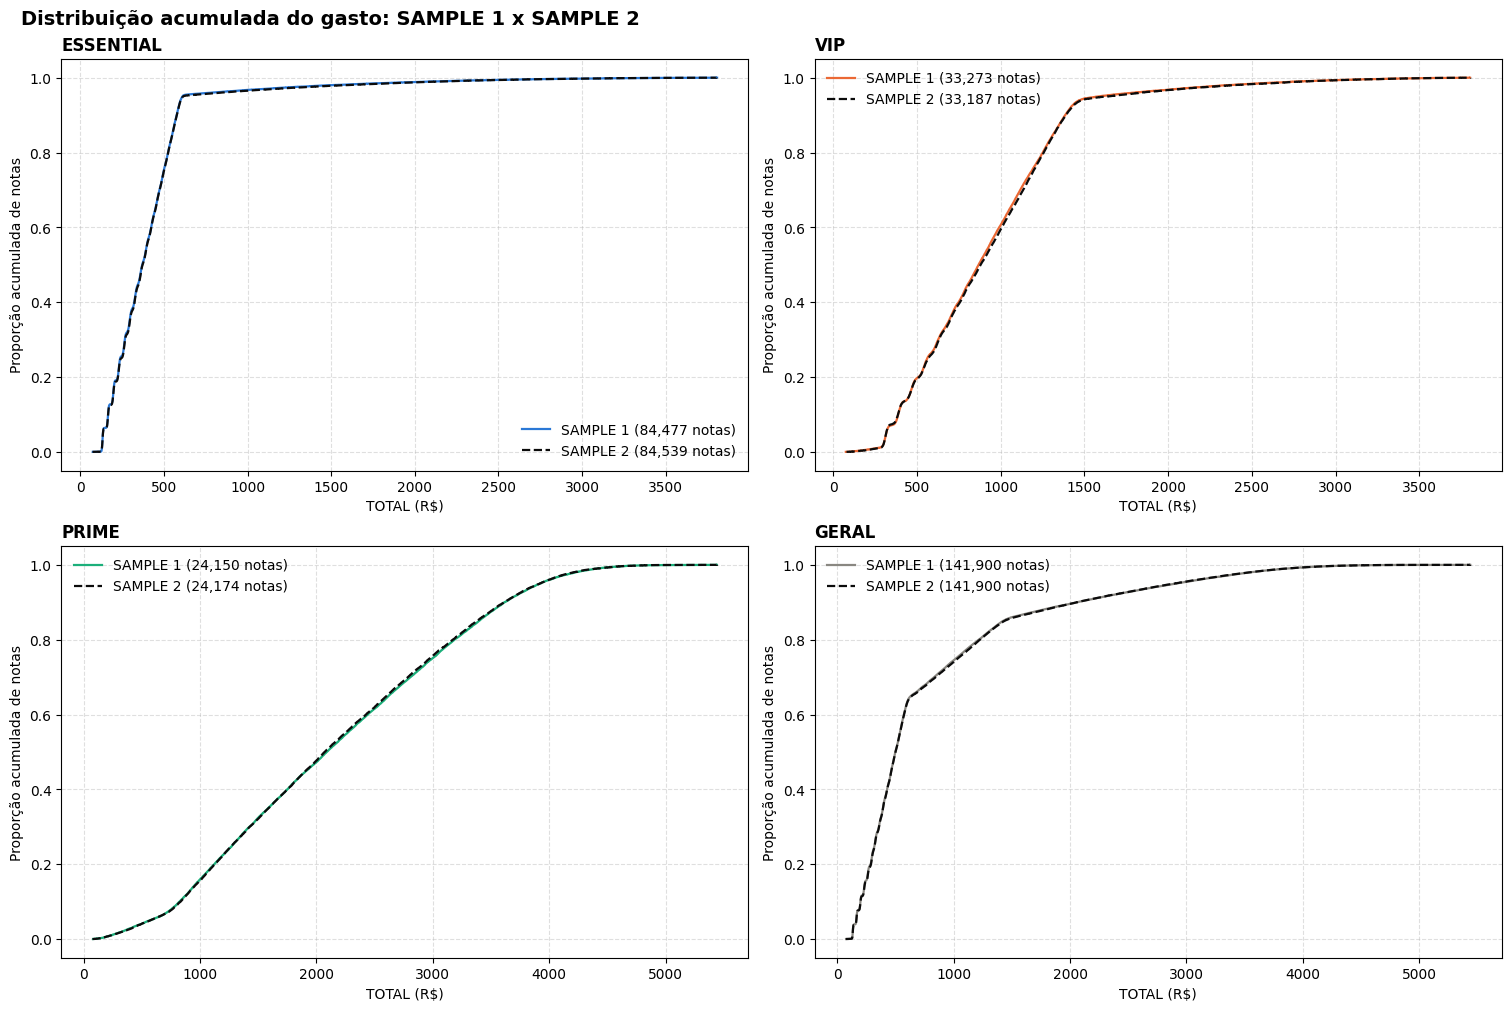

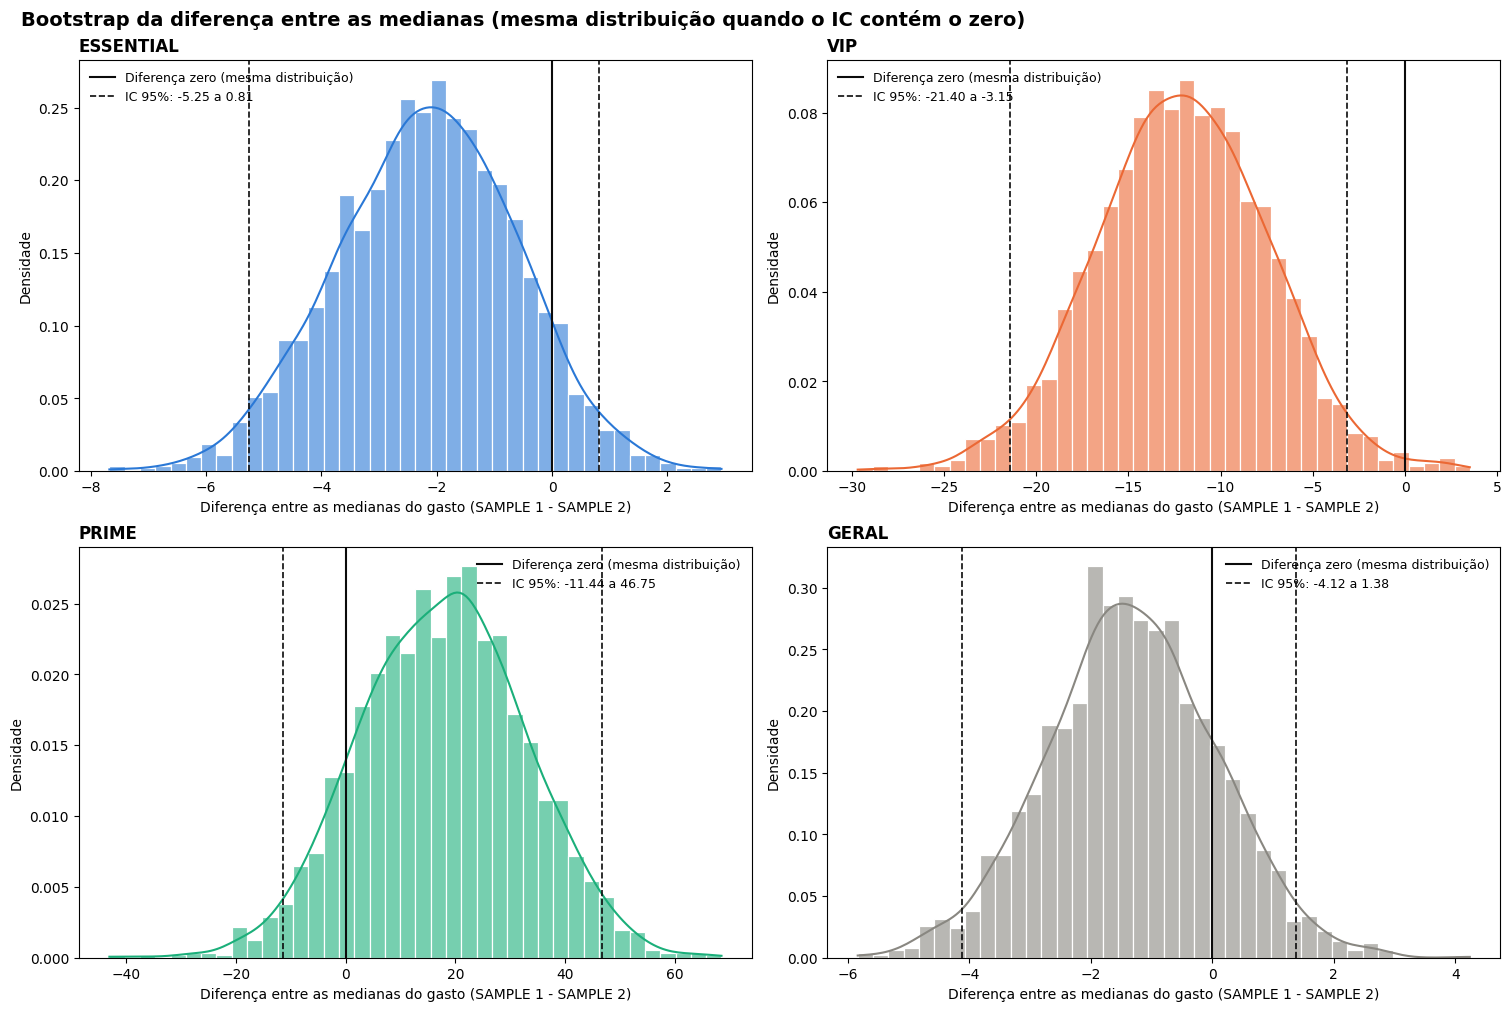


Testes de mesma distribuição entre SAMPLE 1 e SAMPLE 2


,grupo,teste,tipo,o_que_compara,estatistica,p_valor,p_valor_%,conclusao_5%
0,ESSENTIAL,t de Student,Paramétrico,compara as médias,-2.6178,0.0089,0.8850,Distribuições diferentes
1,ESSENTIAL,t pareado,Paramétrico,exige amostras pareadas (só referência),-2.6123,0.0090,0.8995,Distribuições diferentes
2,ESSENTIAL,ANOVA,Paramétrico,compara as médias,6.8530,0.0089,0.8850,Distribuições diferentes
3,ESSENTIAL,Mann-Whitney U,Não paramétrico,compara a posição (postos),"3,550,608,710.0000",0.0441,4.4085,Distribuições diferentes
4,ESSENTIAL,Wilcoxon,Não paramétrico,exige amostras pareadas (só referência),"1,770,771,590.5000",0.0631,6.3109,Mesma distribuição
5,ESSENTIAL,Kruskal-Wallis,Não paramétrico,compara a posição (postos),4.0533,0.0441,4.4085,Distribuições diferentes
6,ESSENTIAL,Kolmogorov-Smirnov,Não paramétrico,compara a distribuição inteira,0.0060,0.0963,9.6259,Mesma distribuição
7,ESSENTIAL,Anderson-Darling k-amostras,Não paramétrico,compara a distribuição inteira (p limitado a 25%),1.9464,0.0512,5.1241,Mesma distribuição
8,VIP,t de Student,Paramétrico,compara as médias,-2.3990,0.0164,1.6442,Distribuições diferentes
9,VIP,t pareado,Paramétrico,exige amostras pareadas (só referência),-2.3691,0.0178,1.7838,Distribuições diferentes



Bootstrap da diferença entre as medianas


,mediana_sample1,mediana_sample2,diferenca,ic_inferior,ic_superior,contem_zero
grupo,,,,,,
ESSENTIAL,369.6400,371.6700,-2.0300,-5.2502,0.8100,True
VIP,868.1700,880.1000,-11.9300,-21.4002,-3.1487,False
PRIME,"2,089.8600","2,071.7700",18.0900,-11.4372,46.7516,True
GERAL,498.1250,499.5050,-1.3800,-4.1206,1.3756,True


In [32]:
# Testes de mesma distribuição entre SAMPLE 1 e SAMPLE 2
resultado_A1_3_3 = AtividadeA1_3_3()

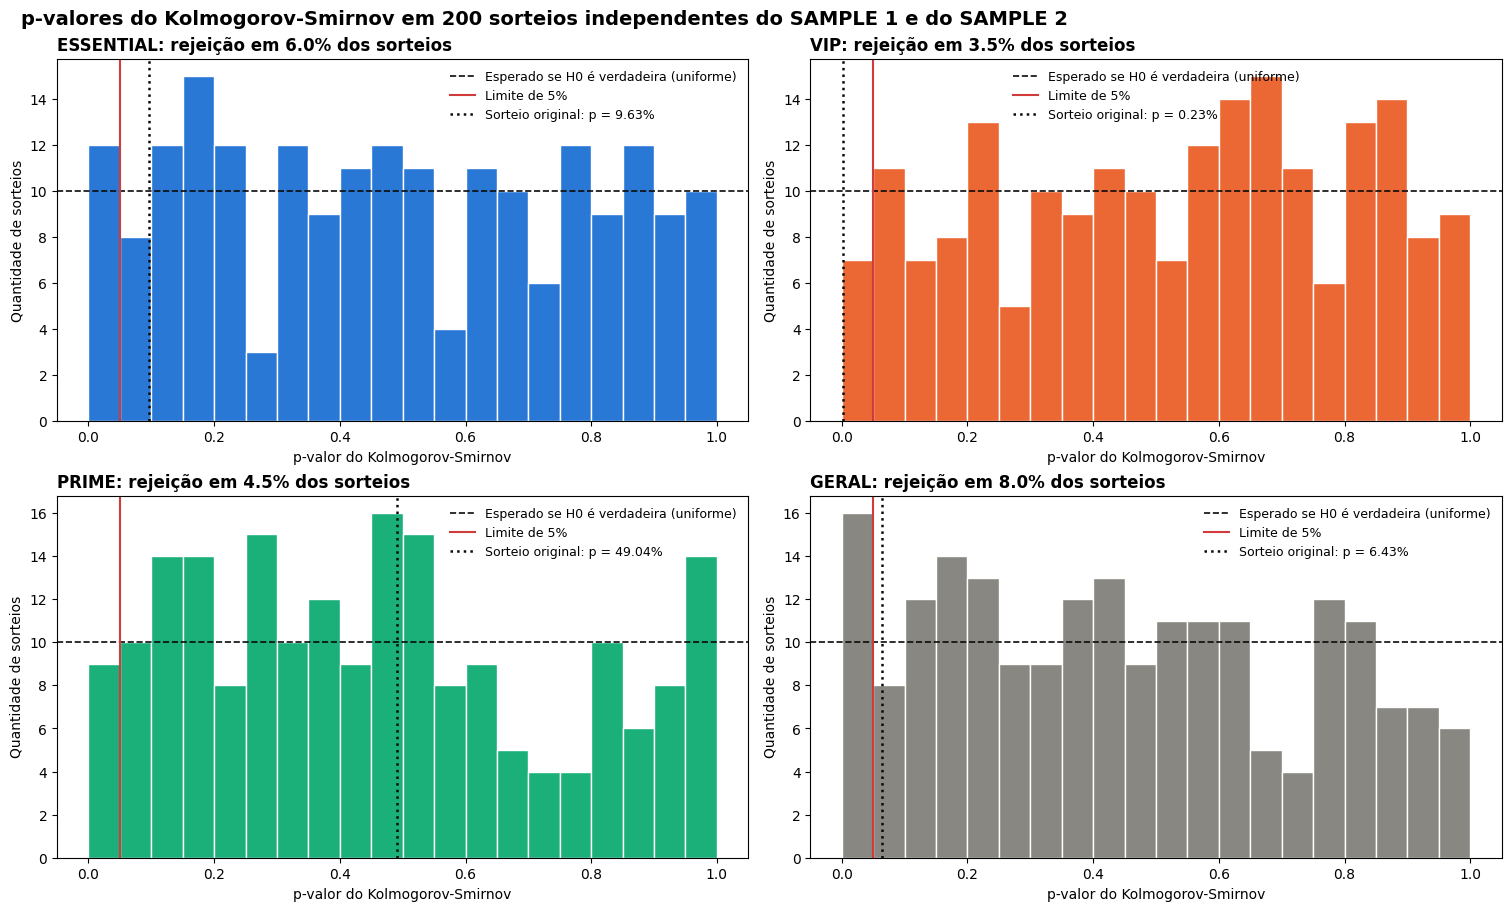


Taxa de rejeição da mesma distribuição em repetidos sorteios


,%_rejeicao_KS,%_rejeicao_ANOVA,%_esperado
grupo,,,
ESSENTIAL,6.0000,6.0000,5.0000
VIP,3.5000,2.5000,5.0000
PRIME,4.5000,6.0000,5.0000
GERAL,8.0000,7.5000,5.0000


In [33]:
# Repete o sorteio 200 vezes para verificar se a rejeição isolada é explicada pelo acaso
resultado_A1_3_3_repeticao = AtividadeA1_3_3_repeticao()

### Resultado do teste de mesma distribuição

**Sorteio original (p-valores):**

| Grupo | ANOVA | Mann-Whitney | **Kolmogorov-Smirnov** | Anderson-Darling | Diferença de medianas, IC 95% bootstrap (R\$) |
|---|---|---|---|---|---|
| ESSENTIAL | 0,89% | 4,41% | **9,63%** | 5,12% | −5,25 a 0,81 (contém o zero) |
| VIP | 1,64% | 1,55% | **0,23%** | 0,83% | −21,40 a −3,15 (não contém o zero) |
| PRIME | 46,50% | 50,82% | **49,04%** | ≥ 25% | −11,44 a 46,75 (contém o zero) |
| GERAL | 28,64% | 8,65% | **6,43%** | 7,30% | −4,12 a 1,38 (contém o zero) |

**Best fit:** o teste de **Kolmogorov-Smirnov**. A pergunta é se as duas amostras têm a mesma distribuição, e o KS compara a curva de distribuição acumulada inteira, e não só a média ou a mediana. Ele também é não paramétrico, o que é necessário porque a A1.3.1 mostrou que os dados não são normais. O Anderson-Darling para k amostras confirma os resultados. A ANOVA e o teste t comparam só as médias e pressupõem normalidade, por isso não são os mais adequados para esta pergunta.

No sorteio original, o GERAL, o PRIME e o ESSENTIAL têm a mesma distribuição pelo best fit. O VIP foi rejeitado (KS 0,23%), mas a diferença máxima entre as curvas acumuladas é de apenas 1,4 ponto percentual, e as medianas diferem em R\$ 11,93 (1,4%). No gráfico de distribuição acumulada, as curvas praticamente se sobrepõem.

**Essa rejeição é real ou acaso?** As duas amostras foram sorteadas da mesma base, então a hipótese de mesma distribuição é verdadeira por construção. Nessa situação, um teste a 5% rejeita a hipótese em cerca de 5% dos sorteios, só por acaso (erro do tipo I). Testando quatro grupos, a chance de pelo menos um dar "diferente" é de cerca de 18%. Para verificar, repeti o sorteio do SAMPLE 1 e do SAMPLE 2 **200 vezes**:

| Grupo | Rejeição pelo KS | Rejeição pela ANOVA | Esperado |
|---|---|---|---|
| ESSENTIAL | 6,0% | 6,0% | 5% |
| VIP | 3,5% | 2,5% | 5% |
| PRIME | 4,5% | 6,0% | 5% |
| GERAL | 8,0% | 7,5% | 5% |

Todas as taxas estão dentro da variação esperada para 200 sorteios (cerca de 2% a 8%), e os p-valores se distribuem de forma aproximadamente uniforme entre 0 e 1, como deve acontecer quando as amostras vêm da mesma população. O VIP, justamente o grupo rejeitado no sorteio original, teve uma das menores taxas de rejeição (3,5%). Isso mostra que o resultado do sorteio original foi uma ocorrência do acaso, e não uma diferença real entre as amostras.

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem a MESMA DISTRIBUIÇÃO DOS DADOS ???**

CONCLUIR / RESPONDER AQUI:
*   **Sim, o SAMPLE 1 e o SAMPLE 2 têm a mesma distribuição dos dados.** Pelo best fit (Kolmogorov-Smirnov), os p-valores são de 6,43% no GERAL, 9,63% no ESSENTIAL e 49,04% no PRIME, todos acima de 5%. O GERAL e o ESSENTIAL ficam mais próximos do limite, e o PRIME tem margem ampla.
*   No VIP, o sorteio original deu p-valor de 0,23%, mas a diferença é de apenas 1,4 ponto percentual entre as curvas. A repetição de 200 sorteios mostrou que os testes rejeitam a mesma distribuição em 2,5% a 8% das vezes, que é a taxa esperada só pelo acaso. Isso confirma que a rejeição do VIP foi um erro do tipo I, e que o procedimento de amostragem com o tamanho ideal gera amostras com a mesma distribuição.

#### A1.3.4: Teste das Médias Amostrais

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste das Médias Amostrais: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

**Como conduzi o A1.3.4**

Hipóteses: H0: as médias do gasto no SAMPLE 1 e no SAMPLE 2 são iguais. H1: as médias são diferentes. Com p-valor acima de 5%, não se rejeita H0.

Testes aplicados no geral e em cada tipo de conta:
- **t de Student:** o teste do exemplo do professor, que considera variâncias iguais nas duas amostras;
- **t de Welch:** a mesma comparação, sem exigir variâncias iguais;
- **ANOVA:** com dois grupos, equivale ao t de Student (F = t²).

Embora o gasto não seja normal (A1.3.1), testes de médias são válidos aqui. Com dezenas de milhares de notas, a média amostral segue distribuição normal pelo Teorema Central do Limite, como o bootstrap da A1.1 mostrou.

**Gráficos:**
1. O bootstrap da diferença entre as médias (SAMPLE 1 − SAMPLE 2), com intervalo de confiança de 95%. Se ele contém o zero, as médias são iguais.
2. As médias das duas amostras com os seus intervalos de confiança de 95%, lado a lado.

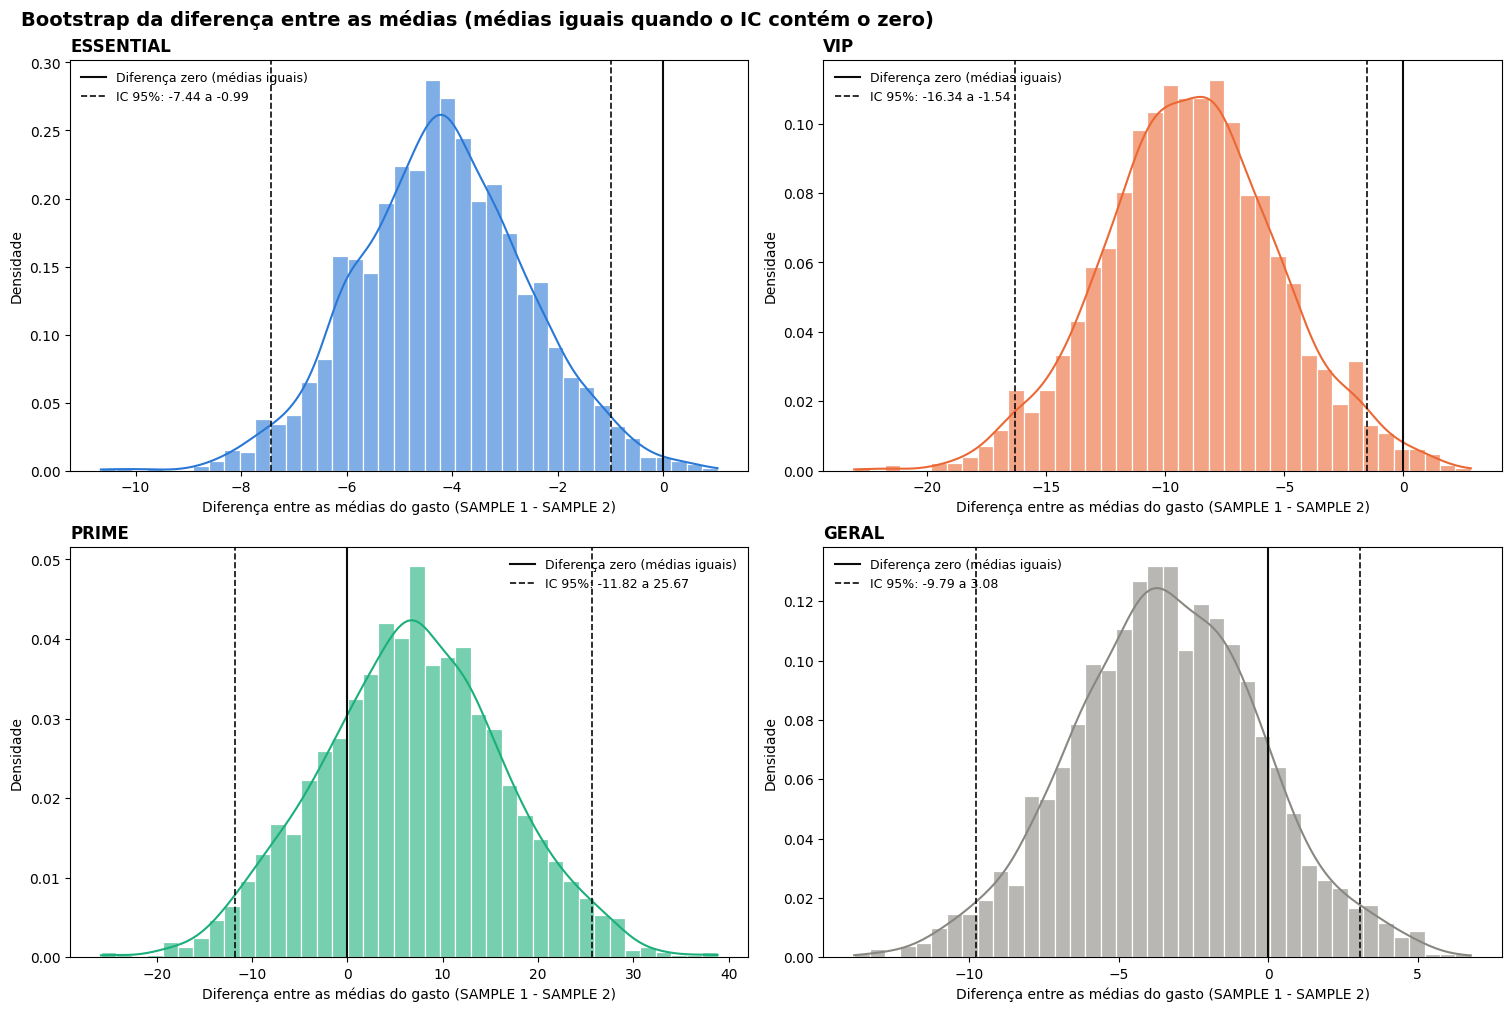

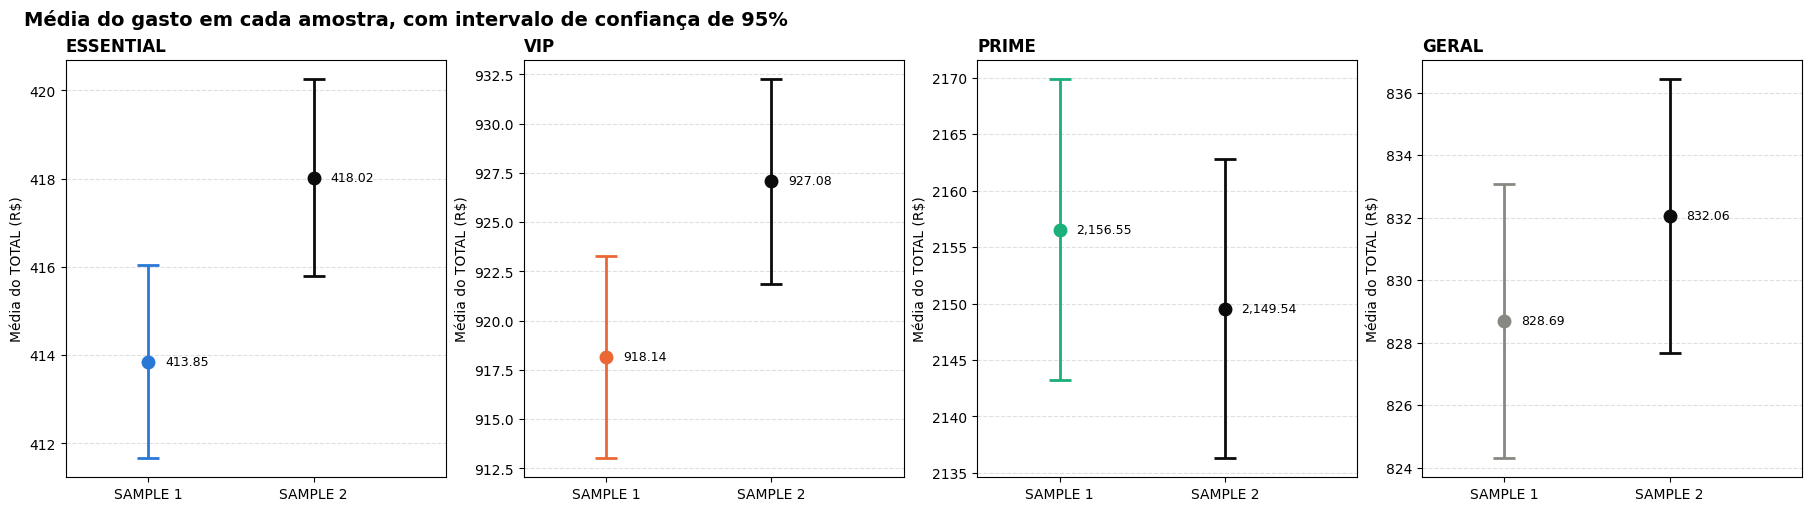


Médias do gasto em cada amostra


,media_sample1,ic_sample1,media_sample2,ic_sample2,diferenca,diferenca_%
grupo,,,,,,
ESSENTIAL,413.8487,411.66 a 416.03,418.0250,415.79 a 420.26,-4.1763,-0.9991
VIP,918.1418,913.01 a 923.27,927.0763,921.88 a 932.27,-8.9345,-0.9637
PRIME,"2,156.5499","2,143.20 a 2,169.90","2,149.5359","2,136.28 a 2,162.79",7.0140,0.3263
GERAL,828.6871,824.30 a 833.07,832.0590,827.68 a 836.44,-3.3719,-0.4052



Testes das médias amostrais entre SAMPLE 1 e SAMPLE 2


,grupo,teste,observacao,estatistica,p_valor,p_valor_%,conclusao_5%
0,ESSENTIAL,t de Student,variâncias iguais (exemplo do professor),-2.6178,0.0089,0.8850,Médias diferentes
1,ESSENTIAL,t de Welch,não exige variâncias iguais,-2.6178,0.0088,0.8850,Médias diferentes
2,ESSENTIAL,ANOVA,com dois grupos equivale ao t de Student,6.8530,0.0089,0.8850,Médias diferentes
3,VIP,t de Student,variâncias iguais (exemplo do professor),-2.3990,0.0164,1.6442,Médias diferentes
4,VIP,t de Welch,não exige variâncias iguais,-2.3990,0.0164,1.6444,Médias diferentes
5,VIP,ANOVA,com dois grupos equivale ao t de Student,5.7553,0.0164,1.6442,Médias diferentes
6,PRIME,t de Student,variâncias iguais (exemplo do professor),0.7307,0.4650,46.4986,Médias iguais
7,PRIME,t de Welch,não exige variâncias iguais,0.7307,0.4650,46.4987,Médias iguais
8,PRIME,ANOVA,com dois grupos equivale ao t de Student,0.5339,0.4650,46.4986,Médias iguais
9,GERAL,t de Student,variâncias iguais (exemplo do professor),-1.0661,0.2864,28.6378,Médias iguais



Bootstrap da diferença entre as médias


,diferenca_observada,ic_inferior,ic_superior,erro_padrao_bootstrap,contem_zero
grupo,,,,,
ESSENTIAL,-4.1763,-7.4370,-0.9871,1.6106,False
VIP,-8.9345,-16.3394,-1.5442,3.7054,False
PRIME,7.0140,-11.8212,25.6656,9.5943,True
GERAL,-3.3719,-9.7852,3.0752,3.1813,True



Taxa de rejeição de médias iguais (ANOVA) nos sorteios repetidos do A1.3.3


,%_rejeicao_ANOVA,%_esperado
grupo,,
ESSENTIAL,6.0000,5.0000
VIP,2.5000,5.0000
PRIME,6.0000,5.0000
GERAL,7.5000,5.0000


In [34]:
# Testes das médias amostrais entre SAMPLE 1 e SAMPLE 2
resultado_A1_3_4 = AtividadeA1_3_4()

### Resultado do teste das médias amostrais

| Grupo | Média SAMPLE 1 (R\$) | Média SAMPLE 2 (R\$) | Diferença | t de Welch (p-valor) | ANOVA (p-valor) | Diferença das médias, IC 95% bootstrap (R\$) |
|---|---|---|---|---|---|---|
| ESSENTIAL | 413,85 | 418,03 | −1,00% | 0,88% | 0,89% | −7,44 a −0,99 |
| VIP | 918,14 | 927,08 | −0,96% | 1,64% | 1,64% | −16,34 a −1,54 |
| PRIME | 2.156,55 | 2.149,54 | +0,33% | **46,50%** | 46,50% | −11,82 a 25,67 (contém o zero) |
| GERAL | 828,69 | 832,06 | −0,41% | **28,64%** | 28,64% | −9,79 a 3,08 (contém o zero) |

**Best fit:** o **t de Welch**. Com dezenas de milhares de notas, a média amostral segue distribuição normal pelo Teorema Central do Limite, então um teste paramétrico de médias é válido mesmo com o gasto não sendo normal. Entre os testes de médias, o Welch é o mais adequado porque não exige que as duas amostras tenham a mesma variância. Aqui ele deu praticamente o mesmo resultado do t de Student, porque as amostras têm tamanhos quase iguais. A ANOVA confirma: com dois grupos, a estatística F é o quadrado do t (6,853 = 2,6178²).

**Leitura:** no GERAL e no PRIME, as médias são iguais, com margem ampla (28,64% e 46,50%). No ESSENTIAL e no VIP, o sorteio original apontou diferença estatística, mas pequena: cerca de 1% (R\$ 4,18 e R\$ 8,93). Os intervalos de confiança das duas amostras se sobrepõem em parte no gráfico de médias.

**Essa diferença é real ou acaso?** As duas amostras vêm da mesma base, então as médias são iguais por construção, e uma rejeição só pode ser um erro do tipo I. Nos 200 sorteios repetidos no A1.3.3, a ANOVA rejeitou médias iguais em 6,0% das vezes no ESSENTIAL e em 2,5% no VIP, taxas compatíveis com os 5% esperados só pelo acaso. A diferença no sorteio original é, portanto, variação amostral, e não uma diferença real entre as amostras.

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem as MESMAS MÉDIAS AMOSTRAIS ???**

CONCLUIR / RESPONDER AQUI:
*   **Sim, o SAMPLE 1 e o SAMPLE 2 têm as mesmas médias amostrais.** Pelo best fit (t de Welch), o p-valor é de **28,64% no GERAL** e de 46,50% no PRIME, ambos bem acima de 5%. As médias gerais diferem só 0,41% (R\$ 828,69 contra R\$ 832,06).
*   No ESSENTIAL (p = 0,88%) e no VIP (p = 1,64%), o sorteio original apontou diferença de cerca de 1% nas médias. A repetição de 200 sorteios mostrou que essa rejeição acontece em 2,5% a 6% das vezes só pelo acaso, dentro do esperado para um teste a 5%. Isso confirma que o tamanho ideal de 141.900 notas gera amostras com médias consistentes.

##Atividade A2 ([Link](https://colab.research.google.com/drive/1w-72bl_qBnGIR8y9zcGYNcpar9b2JdwA?usp=sharing)): Estatística descritiva

**Como conduzi a A2**

A estatística descritiva foi feita sobre a amostra de tamanho ideal definida na A1.1 (141.900 notas fiscais), e não sobre a base completa. Como mostraram os testes da A1.3, essa amostra representa a população, então as medidas calculadas aqui são estimativas confiáveis das características dos clientes da UVVine.

###Atividade A2.1: Analisar as variáveis Quantitativas

**Como conduzi a A2.1**

Variáveis quantitativas analisadas: o gasto (TOTAL R\$), a renda bruta, o número de dependentes, a nota de satisfação e as 13 características dos vinhos.

1. **Medidas de resumo** de todas elas, com a função statistic do material do professor (média, mediana, moda, desvio padrão, quartis, mínimo, máximo e amplitude), mais o coeficiente de variação, a assimetria e a curtose.
2. **Gasto e renda por tipo de conta**, as duas variáveis centrais do negócio.
3. **Gráficos** da função normalChart para o gasto e a renda, em cada tipo de conta e no geral.
4. **Correlação de Spearman** entre as variáveis, para ver o que acompanha o gasto do cliente. Usei Spearman por ser robusta a dados não normais e a outliers. Esse resultado também prepara a modelagem do Módulo 2.

Medidas de resumo das variáveis quantitativas (amostra de tamanho ideal)


,média,mediana,moda,desvio_padrão,mínimo,Q1,Q3,máximo,amplitude,cv_%,assimetria,curtose
TOTAL (R$),828.4500,499.1600,131.1800,841.5100,74.6900,319.2900,"1,023.0700","5,388.7600","5,314.0700",101.5800,2.0500,3.9100
RENDA BRUTO (R$),"7,532.1000","3,349.4000","3,233.2200","6,590.0600","1,759.6900","3,237.0200","7,982.3200","31,333.7600","29,574.0700",87.4900,1.4900,0.8500
DEPENDENTES,1.0600,1.0000,1.0000,0.9500,0.0000,0.0000,1.0000,4.0000,4.0000,90.3200,1.1800,1.3800
NOTA DE SATISFAÇÃO (%),69.0100,68.6800,68.6800,1.4800,68.6800,68.6800,68.6800,92.2100,23.5300,2.1400,5.5200,34.8200
MEAN: alcohol,13.0000,13.0000,9.4000,0.8100,9.4000,12.4500,13.5500,16.6900,7.2900,6.2300,-0.0000,0.0100
MEAN: malic_acid,2.3800,2.3600,0.0000,1.0600,0.0000,1.6300,3.1000,7.0600,7.0600,44.3900,0.2000,-0.2300
MEAN: ash,2.3700,2.3700,1.1700,0.2700,1.1700,2.1800,2.5500,3.5900,2.4200,11.5500,0.0200,-0.0300
MEAN: alcalinity_of_ash,19.4900,19.4800,4.7500,3.3400,4.7500,17.2300,21.7500,34.0000,29.2500,17.1300,0.0100,-0.0000
MEAN: magnesium,99.7600,99.7600,42.2500,14.2400,42.2500,90.1200,109.3600,161.7600,119.5200,14.2800,0.0000,0.0000
MEAN: total_phenols,2.3000,2.3000,0.0100,0.6200,0.0100,1.8700,2.7200,5.0000,4.9900,27.1100,-0.0000,-0.0500



TOTAL (R$) por tipo de conta


,média,mediana,moda,desvio_padrão,mínimo,Q1,Q3,máximo,amplitude,cv_%,assimetria,curtose
ESSENTIAL,414.5500,369.5900,131.1800,325.3900,74.6900,238.4400,498.2700,"3,800.9800","3,726.2900",78.4900,4.7100,30.0100
VIP,920.6300,868.3100,315.9200,480.5200,78.8300,562.6400,"1,187.4600","3,817.5900","3,738.7600",52.1900,1.6300,5.0700
PRIME,"2,143.7200","2,062.1900",860.6700,"1,060.3300",78.4600,"1,254.1400","2,986.3100","5,388.7600","5,310.3000",49.4600,0.2200,-0.8600
GERAL,828.4500,499.1600,131.1800,841.5100,74.6900,319.2900,"1,023.0700","5,388.7600","5,314.0700",101.5800,2.0500,3.9100



RENDA BRUTO (R$) por tipo de conta


,média,mediana,moda,desvio_padrão,mínimo,Q1,Q3,máximo,amplitude,cv_%,assimetria,curtose
ESSENTIAL,"3,755.9300","3,256.9500","3,233.2200","2,411.0000","1,759.6900","3,198.1400","3,319.9800","21,190.5200","19,430.8300",64.1900,5.1800,27.1400
VIP,"8,359.0500","7,777.1700","7,517.6700","2,654.9700","1,801.0100","7,554.7000","8,020.5200","21,244.4500","19,443.4400",31.7600,2.8000,9.0800
PRIME,"19,550.9300","20,892.5600","2,943.7800","5,426.1200","1,862.2300","18,401.5600","22,914.5800","31,333.7600","29,471.5300",27.7500,-1.4700,1.8100
GERAL,"7,532.1000","3,349.4000","3,233.2200","6,590.0600","1,759.6900","3,237.0200","7,982.3200","31,333.7600","29,574.0700",87.4900,1.4900,0.8500


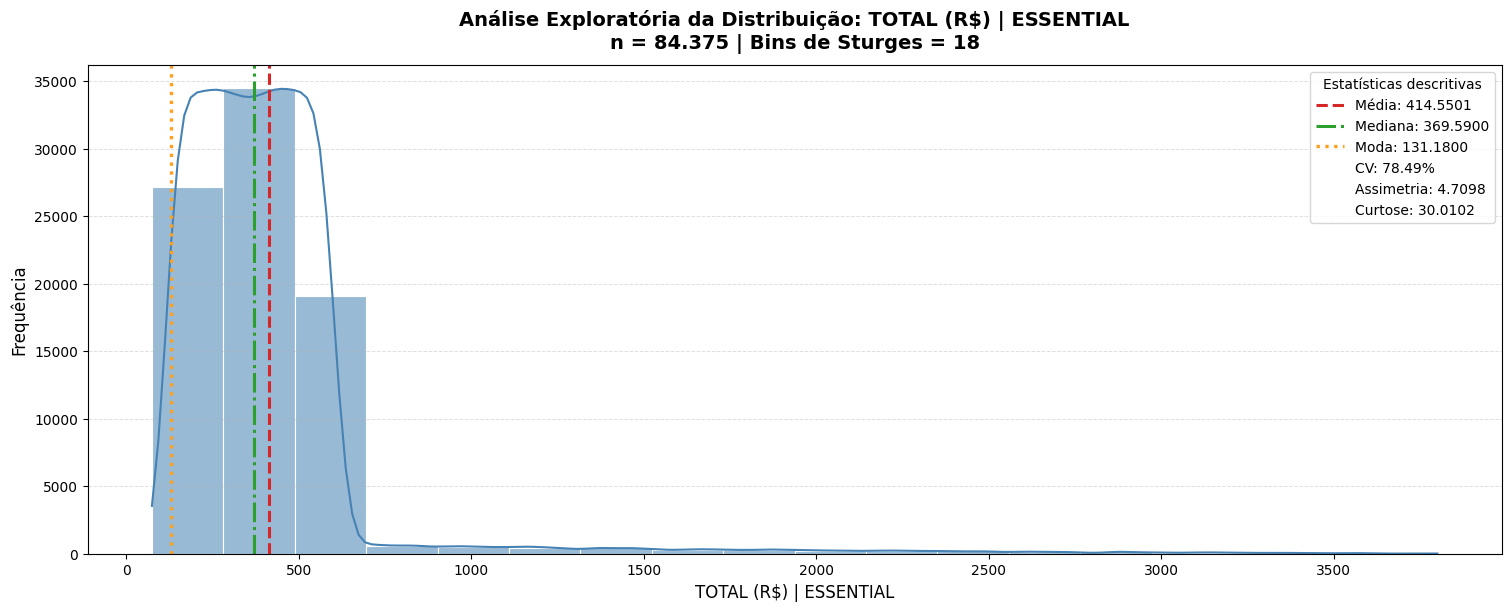


  ANÁLISE EXPLORATÓRIA DOS DADOS: TOTAL (R$) | ESSENTIAL

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 84375
     Mínimo        : 74.6900
     Máximo        : 3800.9800
     Média         : 414.5501
     Mediana       : 369.5900
     Moda          : 131.1800
     Desvio-padrão : 325.3919
     CV            : 78.49%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Alta dispersão relativa (CV ≥ 30%)
     Assimetria    : 4.7098 → Assimetria acentuada à direita (positiva)
     Curtose       : 30.0102 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.588538
     Valor-p       : 5.42784e-76
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




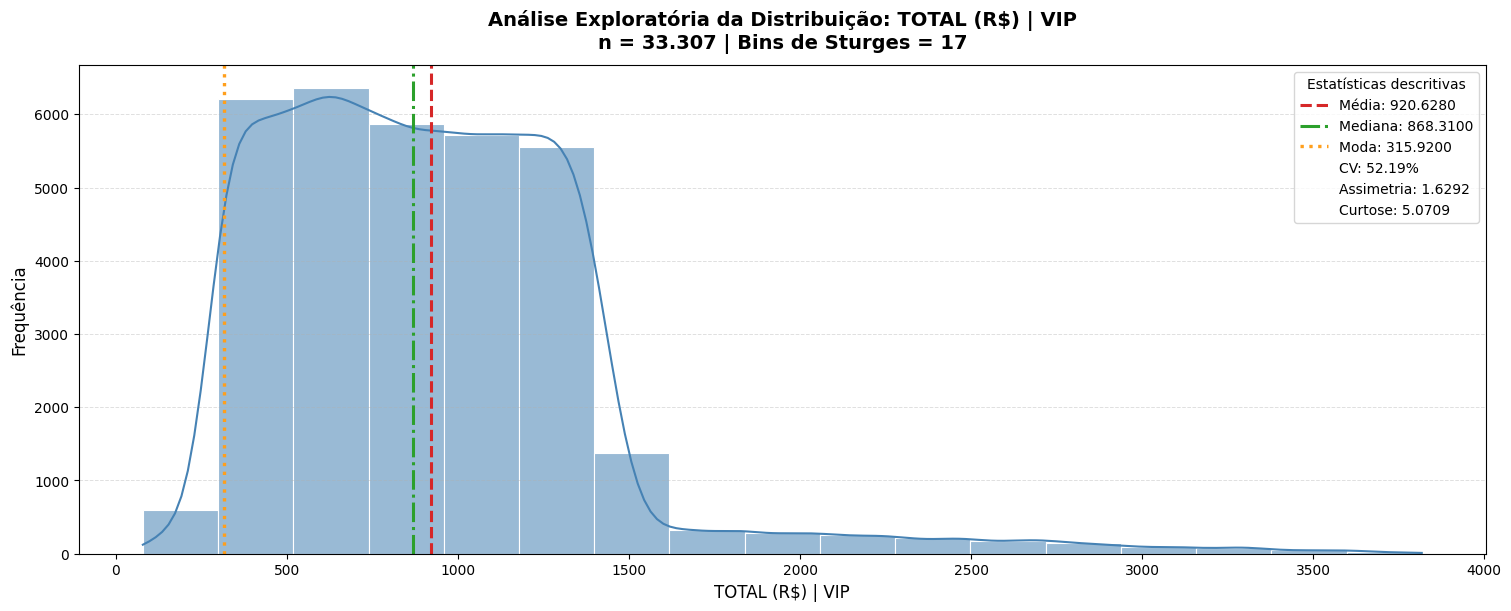


  ANÁLISE EXPLORATÓRIA DOS DADOS: TOTAL (R$) | VIP

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 33307
     Mínimo        : 78.8300
     Máximo        : 3817.5900
     Média         : 920.6280
     Mediana       : 868.3100
     Moda          : 315.9200
     Desvio-padrão : 480.5152
     CV            : 52.19%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Alta dispersão relativa (CV ≥ 30%)
     Assimetria    : 1.6292 → Assimetria acentuada à direita (positiva)
     Curtose       : 5.0709 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.899777
     Valor-p       : 3.01155e-49
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




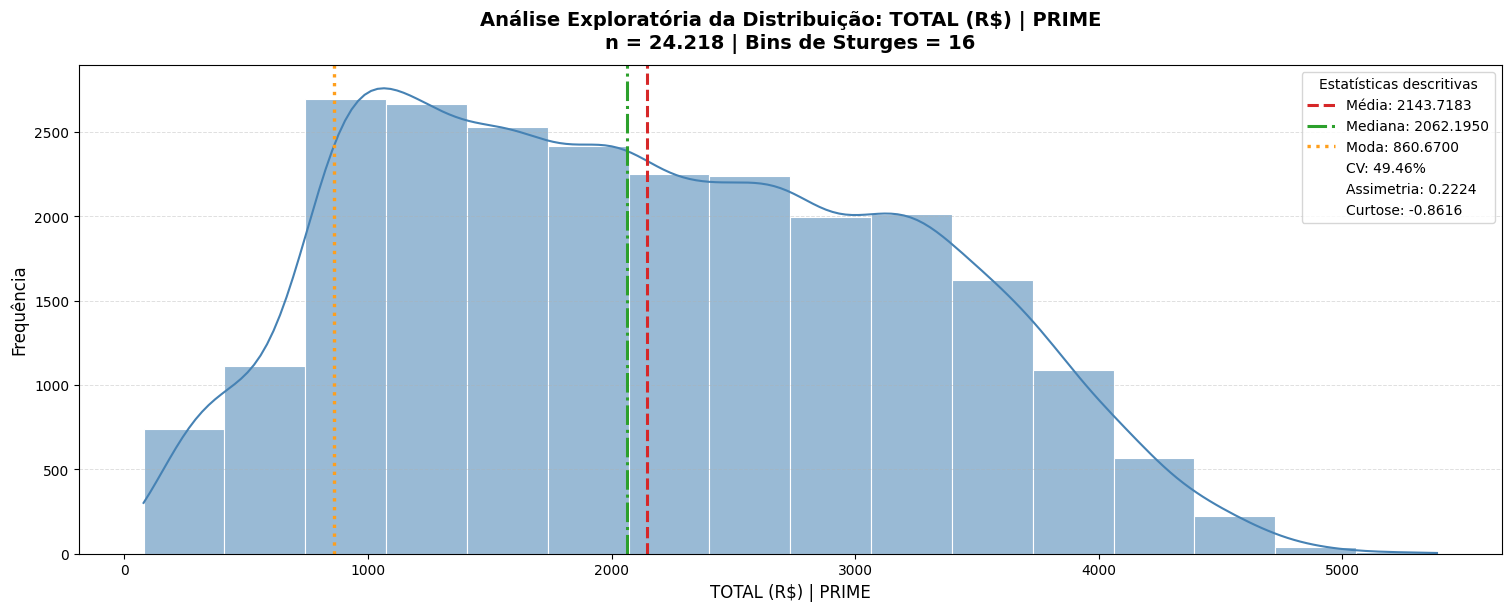


  ANÁLISE EXPLORATÓRIA DOS DADOS: TOTAL (R$) | PRIME

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 24218
     Mínimo        : 78.4600
     Máximo        : 5388.7600
     Média         : 2143.7183
     Mediana       : 2062.1950
     Moda          : 860.6700
     Desvio-padrão : 1060.3283
     CV            : 49.46%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Alta dispersão relativa (CV ≥ 30%)
     Assimetria    : 0.2224 → Distribuição aproximadamente simétrica
     Curtose       : -0.8616 → PLATICÚRTICA: distribuição relativamente mais achatada
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.975090
     Valor-p       : 1.07395e-28
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




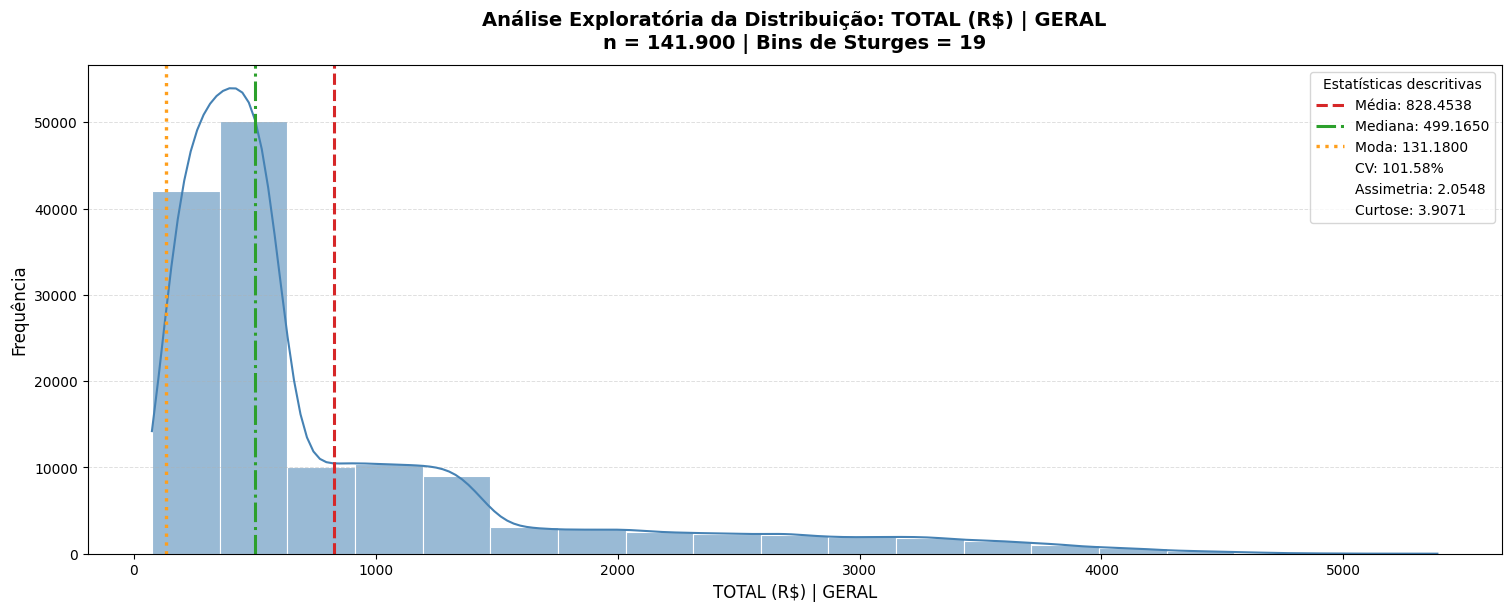


  ANÁLISE EXPLORATÓRIA DOS DADOS: TOTAL (R$) | GERAL

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 141900
     Mínimo        : 74.6900
     Máximo        : 5388.7600
     Média         : 828.4538
     Mediana       : 499.1650
     Moda          : 131.1800
     Desvio-padrão : 841.5081
     CV            : 101.58%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Alta dispersão relativa (CV ≥ 30%)
     Assimetria    : 2.0548 → Assimetria acentuada à direita (positiva)
     Curtose       : 3.9071 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.726132
     Valor-p       : 1.12889e-67
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




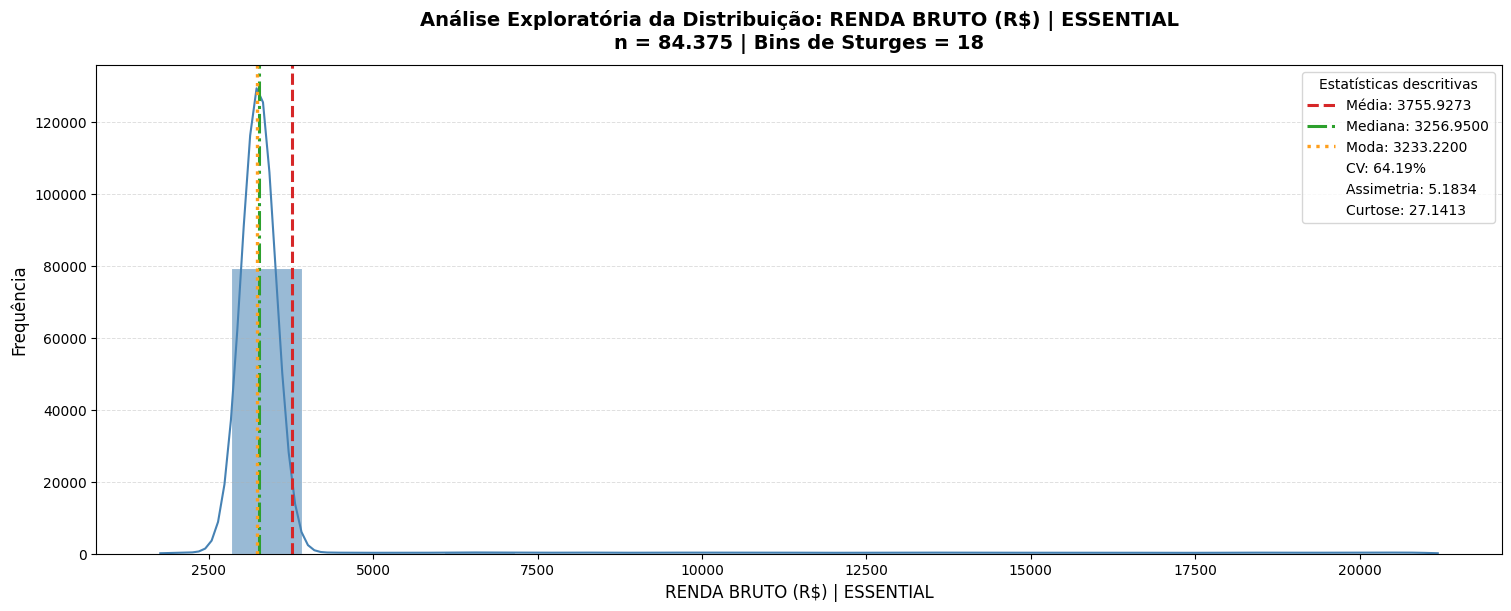


  ANÁLISE EXPLORATÓRIA DOS DADOS: RENDA BRUTO (R$) | ESSENTIAL

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 84375
     Mínimo        : 1759.6900
     Máximo        : 21190.5200
     Média         : 3755.9273
     Mediana       : 3256.9500
     Moda          : 3233.2200
     Desvio-padrão : 2411.0002
     CV            : 64.19%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Alta dispersão relativa (CV ≥ 30%)
     Assimetria    : 5.1834 → Assimetria acentuada à direita (positiva)
     Curtose       : 27.1413 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.239242
     Valor-p       : 1.73737e-89
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




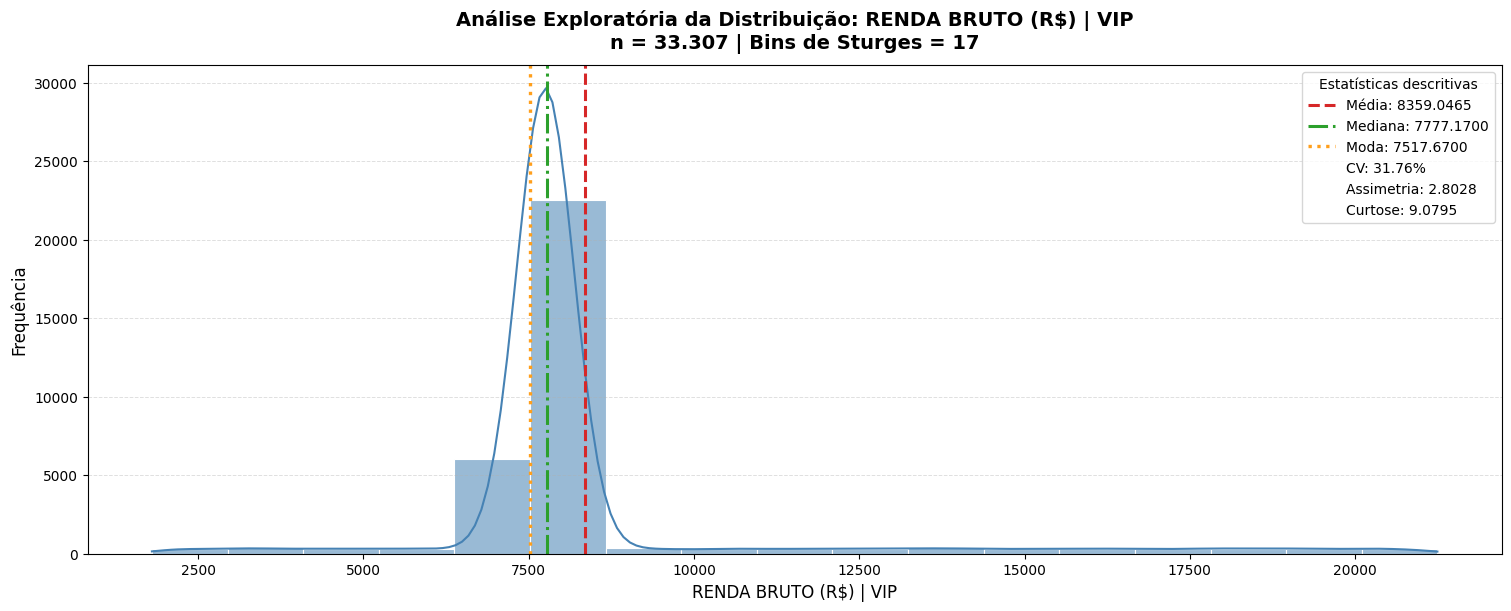


  ANÁLISE EXPLORATÓRIA DOS DADOS: RENDA BRUTO (R$) | VIP

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 33307
     Mínimo        : 1801.0100
     Máximo        : 21244.4500
     Média         : 8359.0465
     Mediana       : 7777.1700
     Moda          : 7517.6700
     Desvio-padrão : 2654.9742
     CV            : 31.76%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Alta dispersão relativa (CV ≥ 30%)
     Assimetria    : 2.8028 → Assimetria acentuada à direita (positiva)
     Curtose       : 9.0795 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.537802
     Valor-p       : 1.85326e-78
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




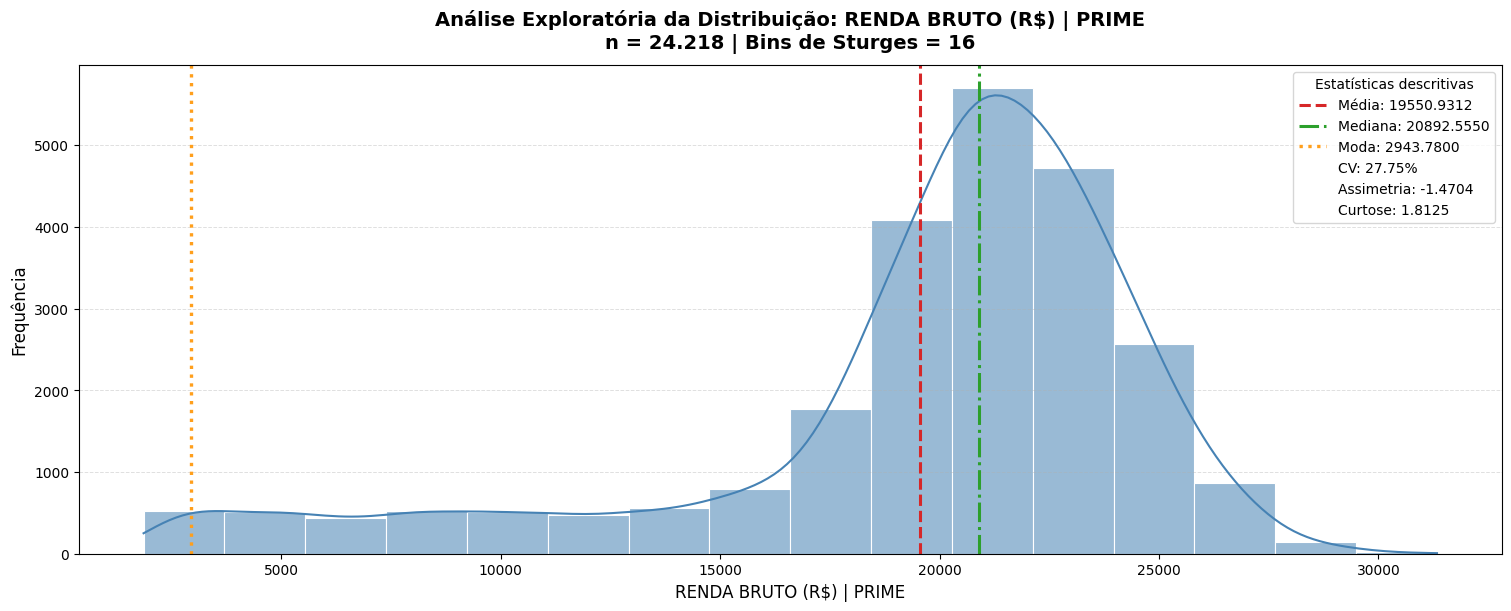


  ANÁLISE EXPLORATÓRIA DOS DADOS: RENDA BRUTO (R$) | PRIME

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 24218
     Mínimo        : 1862.2300
     Máximo        : 31333.7600
     Média         : 19550.9312
     Mediana       : 20892.5550
     Moda          : 2943.7800
     Desvio-padrão : 5426.1220
     CV            : 27.75%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Dispersão relativa moderada (15% ≤ CV < 30%)
     Assimetria    : -1.4704 → Assimetria acentuada à esquerda (negativa)
     Curtose       : 1.8125 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.852709
     Valor-p       : 5.98679e-56
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




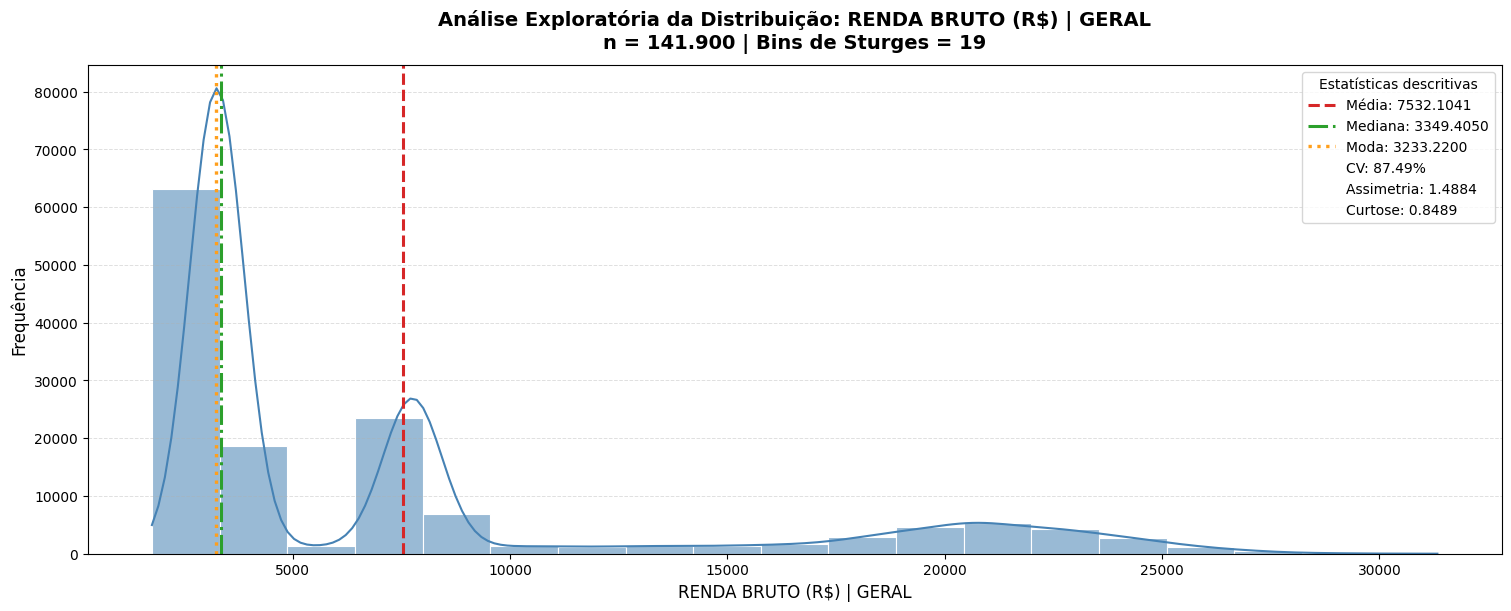


  ANÁLISE EXPLORATÓRIA DOS DADOS: RENDA BRUTO (R$) | GERAL

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 141900
     Mínimo        : 1759.6900
     Máximo        : 31333.7600
     Média         : 7532.1041
     Mediana       : 3349.4050
     Moda          : 3233.2200
     Desvio-padrão : 6590.0579
     CV            : 87.49%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Alta dispersão relativa (CV ≥ 30%)
     Assimetria    : 1.4884 → Assimetria acentuada à direita (positiva)
     Curtose       : 0.8489 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.695877
     Valor-p       : 9.09229e-70
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




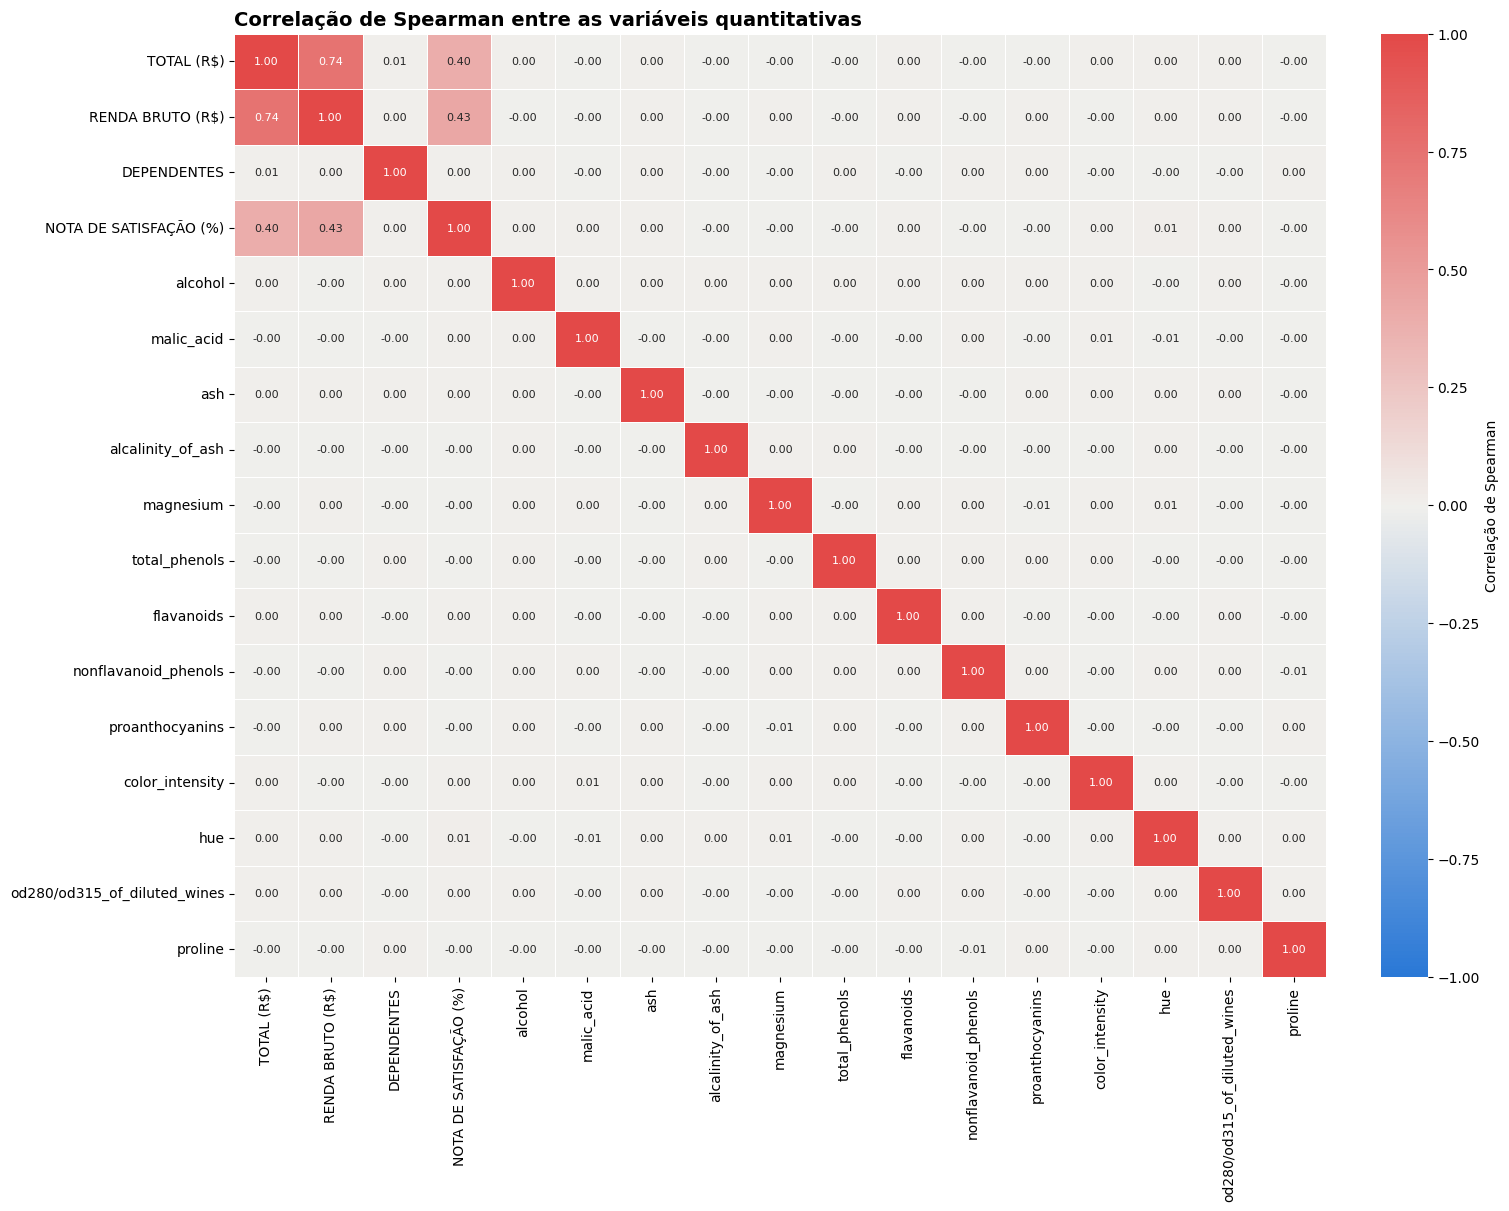


Correlação de cada variável com o gasto (da mais forte para a mais fraca)


,spearman_com_gasto
RENDA BRUTO (R$),0.7447
NOTA DE SATISFAÇÃO (%),0.3978
DEPENDENTES,0.0058
MEAN: nonflavanoid_phenols,-0.0044
MEAN: flavanoids,0.0043
MEAN: proline,-0.0038
MEAN: alcalinity_of_ash,-0.0038
MEAN: hue,0.0035
MEAN: od280/od315_of_diluted_wines,0.0031
MEAN: ash,0.0030


In [39]:
# Estatística descritiva das variáveis quantitativas na amostra de tamanho ideal
resultado_A2_1 = AtividadeA2_1()

### Resultados da A2.1

**Gasto (TOTAL R\$) por tipo de conta:**

| Grupo | Média | Mediana | Desvio padrão | Q1 a Q3 | CV | Assimetria | Curtose |
|---|---|---|---|---|---|---|---|
| ESSENTIAL | 414,55 | 369,59 | 325,39 | 238,44 a 498,27 | 78,5% | 4,71 | 30,01 |
| VIP | 920,63 | 868,31 | 480,52 | 562,64 a 1.187,46 | 52,2% | 1,63 | 5,07 |
| PRIME | 2.143,72 | 2.062,19 | 1.060,33 | 1.254,14 a 2.986,31 | 49,5% | 0,22 | −0,86 |
| GERAL | 828,45 | 499,16 | 841,51 | 319,29 a 1.023,07 | 101,6% | 2,05 | 3,91 |

O cliente PRIME gasta em média **5,2 vezes** mais que o ESSENTIAL, e o VIP, 2,2 vezes. No geral, a média (R\$ 828) fica muito acima da mediana (R\$ 499), porque a maioria das notas é ESSENTIAL (59%) e as notas PRIME puxam a média para cima. Por isso, o geral tem coeficiente de variação acima de 100% e não representa bem nenhum dos tipos de conta: **a análise do gasto deve ser sempre feita por estrato**. No ESSENTIAL e no VIP, a média fica acima da mediana por causa da cauda de contaminação identificada na A1.2. O PRIME é quase simétrico, mas achatado.

**Renda bruta (R\$) por tipo de conta:**

| Grupo | Média | Mediana | Q1 a Q3 | CV |
|---|---|---|---|---|
| ESSENTIAL | 3.755,93 | 3.256,95 | 3.198,14 a 3.319,98 | 64,2% |
| VIP | 8.359,05 | 7.777,17 | 7.554,70 a 8.020,52 | 31,8% |
| PRIME | 19.550,93 | 20.892,56 | 18.401,56 a 22.914,58 | 27,8% |
| GERAL | 7.532,10 | 3.349,40 | 3.237,02 a 7.982,32 | 87,5% |

A renda separa os tipos de conta com muita clareza. Metade dos clientes de cada tipo está numa faixa estreita: cerca de R\$ 3,2 mil no ESSENTIAL, R\$ 7,8 mil no VIP e R\$ 21 mil no PRIME. O histograma geral mostra três "picos", um por tipo de conta. Fora dessas faixas aparece o mesmo piso de contaminação visto no gasto, com valores espalhados entre cerca de R\$ 1,8 mil e R\$ 21 mil em todos os estratos.

**Demais variáveis quantitativas:**
- **Dependentes:** média de 1,06, com mediana e moda iguais a 1 (de 0 a 4).
- **Nota de satisfação:** a moda, a mediana e os dois quartis são iguais a 68,68%. A variável quase não varia, e as notas maiores (até 92,21%) aparecem praticamente só no PRIME, como visto na preparação dos dados.
- **Características dos vinhos:** todas são simétricas (assimetria perto de 0) e com curtose perto de 0, o formato de uma distribuição normal. As que tiveram valores negativos removidos na preparação começam em 0 e têm leve assimetria positiva (cerca de 0,2), efeito do corte da cauda inferior.
- **Observação sobre a moda:** em variáveis contínuas, em que quase nenhum valor se repete, a moda não é uma medida informativa. Nas variáveis dos vinhos, ela coincide com o mínimo.

**Correlação de Spearman com o gasto:**
- **Renda: 0,74**, uma relação forte. Quem ganha mais gasta mais.
- **Nota de satisfação: 0,40**, uma relação moderada. Mas, como a nota só varia no PRIME, essa correlação reflete principalmente o tipo de conta, e não uma relação direta entre satisfação e gasto.
- **Dependentes e as 13 características dos vinhos: praticamente zero** (todas abaixo de 0,006 em módulo). Elas não têm relação monotônica com o gasto. As características dos vinhos também não têm correlação entre si, diferente do conjunto Wine original, o que indica que foram simuladas de forma independente.

**Normalidade:** o teste de Shapiro-Wilk da função normalChart (subamostra de 5.000 notas) rejeitou a normalidade do gasto e da renda em todos os tipos de conta, confirmando o resultado do Anderson-Darling da A1.3.1.

**Implicação para o Módulo 2:** a renda é a variável mais promissora, tanto para prever o gasto (regressor) quanto para identificar o tipo de conta (classificador). As características dos vinhos e o número de dependentes, isoladamente, não mostram relação com o gasto.

###Atividade A2.2: Analisar as variáveis Qualitativas

**Como conduzi a A2.2**

Variáveis qualitativas analisadas: tipo de conta, região, sexo e estado civil. A opinião do cliente é analisada na A3, dedicada à pesquisa de satisfação.

1. **Tabelas de frequência** (absoluta, percentual e percentual acumulado) e **gráficos de Pareto**, que ordenam as categorias da mais frequente para a menos frequente e mostram quanto as principais concentram.
2. **Perfil de cada tipo de conta:** a distribuição de região, sexo, estado civil e dependentes dentro do ESSENTIAL, do VIP e do PRIME.
3. **Associação com o tipo de conta:** teste qui-quadrado de independência e **V de Cramér**, que mede a força da associação de 0 (nenhuma) a 1 (total). Com amostras grandes, o qui-quadrado aponta como significativas até associações mínimas, por isso o V de Cramér é a medida usada para interpretar.
4. **Gasto mediano por categoria** dentro de cada tipo de conta, para ver se o perfil do cliente muda o quanto ele gasta. Usei a mediana por ser resistente à contaminação identificada na A1.2.


Frequência: TIPO DA CONTA


,frequência,%,% acumulado
TIPO DA CONTA,,,
ESSENTIAL,84375,59.4600,59.4600
VIP,33307,23.4700,82.9300
PRIME,24218,17.0700,100.0000



Frequência: REGIÃO


,frequência,%,% acumulado
REGIÃO,,,
SUDESTE,95158,67.0600,67.0600
SUL,22583,15.9100,82.9700
CENTRO-OESTE,12765,9.0000,91.9700
NORDESTE,8563,6.0300,98.0000
NORTE,2831,2.0000,100.0000



Frequência: SEXO


,frequência,%,% acumulado
SEXO,,,
MASCULINO,123378,86.9500,86.9500
FEMININO,18522,13.0500,100.0000



Frequência: ESTADO CIVIL


,frequência,%,% acumulado
ESTADO CIVIL,,,
CASADO,78088,55.0300,55.0300
SOLTEIRO,52643,37.1000,92.1300
DESQUITADO(A) / VIÚVO(A),11169,7.8700,100.0000


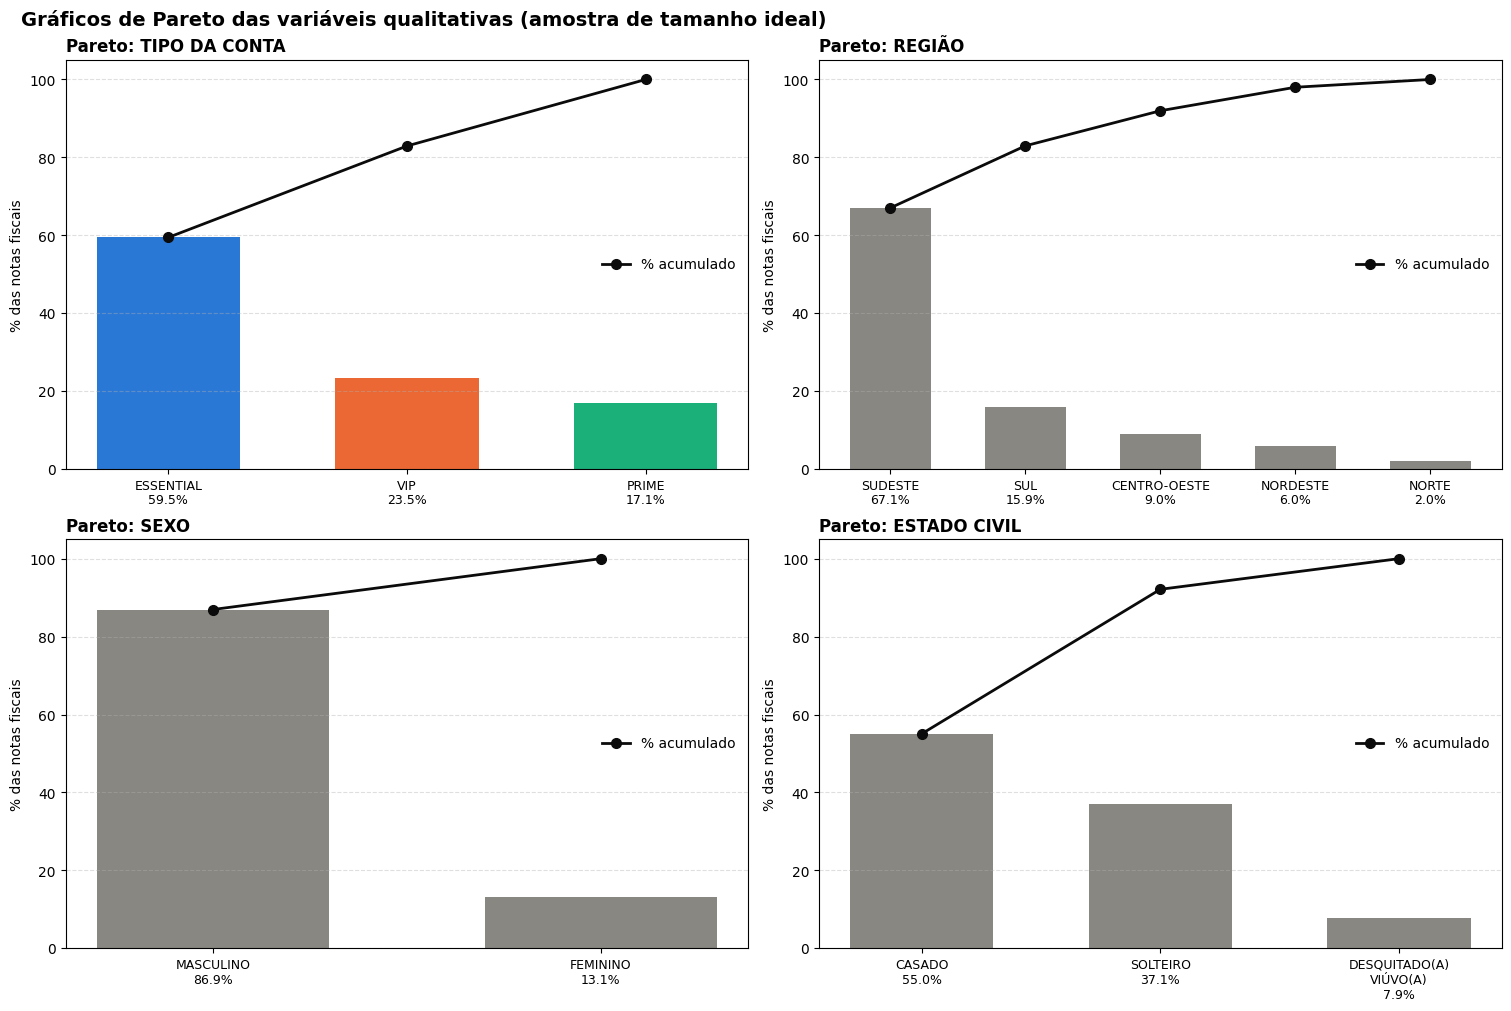

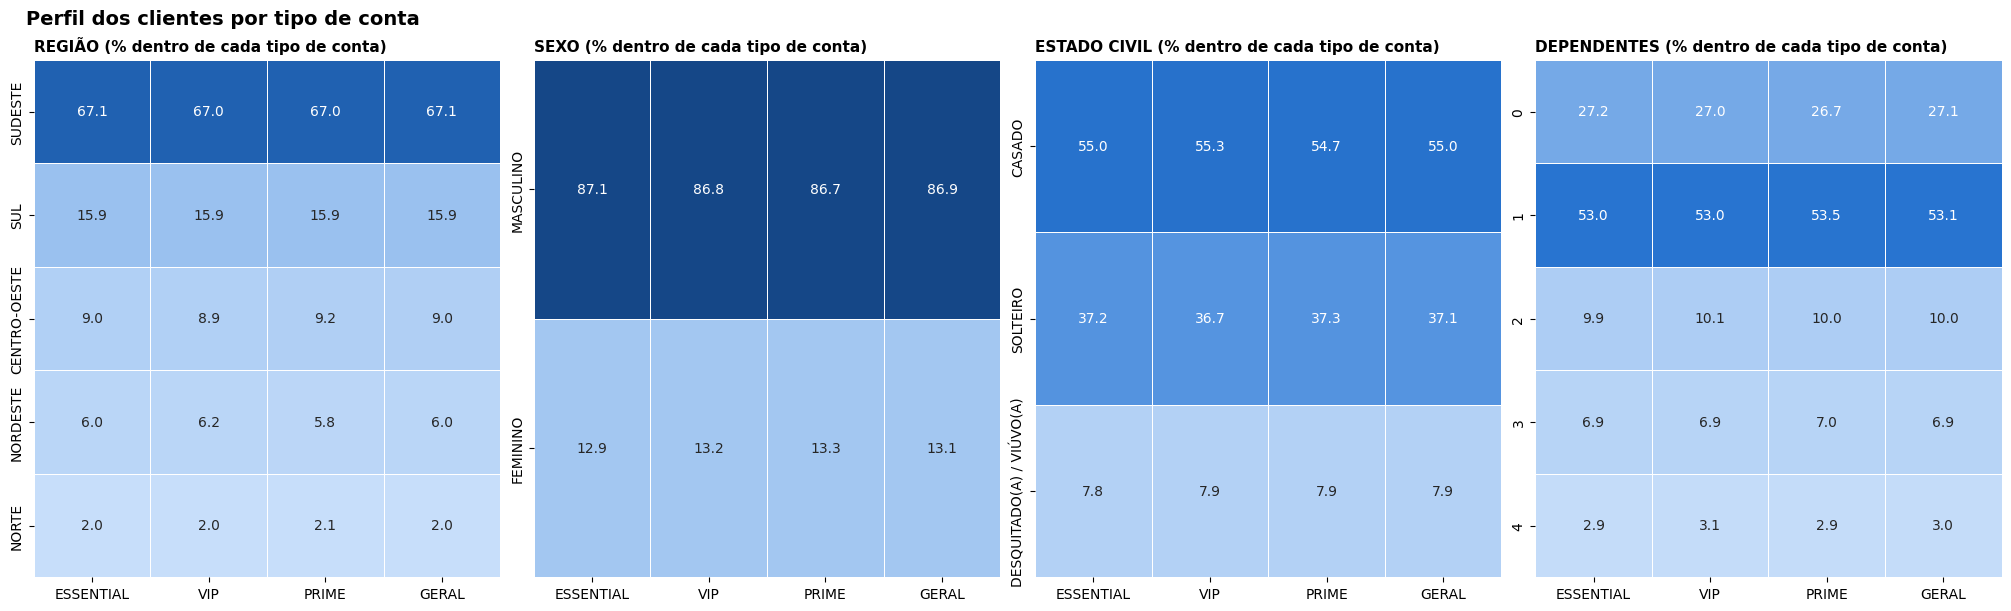


Associação de cada variável com o tipo de conta (qui-quadrado e V de Cramér)


,qui_quadrado,graus_de_liberdade,p_valor,v_de_cramer,força_da_associação
variável,,,,,
REGIÃO,7.9362,8,0.4397,0.0053,desprezível
SEXO,2.2726,2,0.3210,0.0040,desprezível
ESTADO CIVIL,3.0119,4,0.5558,0.0033,desprezível
DEPENDENTES,5.4290,8,0.7109,0.0044,desprezível



Gasto mediano (R$) por REGIÃO e tipo de conta


TIPO DA CONTA,ESSENTIAL,VIP,PRIME,GERAL
REGIÃO,,,,
CENTRO-OESTE,370.8200,877.5800,"2,082.7800",502.2200
NORDESTE,364.7300,859.4000,"2,072.7100",498.7500
NORTE,383.3600,852.2500,"2,072.6200",507.1400
SUDESTE,369.2500,868.6800,"2,053.7600",498.5600
SUL,370.5300,864.8800,"2,090.5500",499.3000



Gasto mediano (R$) por SEXO e tipo de conta


TIPO DA CONTA,ESSENTIAL,VIP,PRIME,GERAL
SEXO,,,,
FEMININO,376.1700,872.5000,"2,028.7400",500.4800
MASCULINO,368.6800,867.7800,"2,066.5600",498.9800



Gasto mediano (R$) por ESTADO CIVIL e tipo de conta


TIPO DA CONTA,ESSENTIAL,VIP,PRIME,GERAL
ESTADO CIVIL,,,,
CASADO,370.2000,869.8800,"2,082.7800",501.2400
DESQUITADO(A) / VIÚVO(A),370.0100,894.4100,"2,006.2300",504.6200
SOLTEIRO,368.1000,860.2300,"2,037.6900",494.9800



Gasto mediano (R$) por DEPENDENTES e tipo de conta


TIPO DA CONTA,ESSENTIAL,VIP,PRIME,GERAL
DEPENDENTES,,,,
0,370.3600,862.8400,"2,056.3300",495.8600
1,368.6100,870.3100,"2,055.0000",499.4400
2,367.2200,875.8400,"2,102.4200",505.1000
3,371.8700,863.2200,"2,067.6700",499.5900
4,386.5000,851.3300,"2,133.9300",503.1500


In [41]:
# Estatística descritiva das variáveis qualitativas na amostra de tamanho ideal
resultado_A2_2 = AtividadeA2_2()

### Resultados da A2.2

**Distribuição das variáveis qualitativas (amostra de 141.900 notas):**

| Variável | Categorias (da mais para a menos frequente) |
|---|---|
| Tipo de conta | ESSENTIAL 59,5% · VIP 23,5% · PRIME 17,1% |
| Região | Sudeste 67,1% · Sul 15,9% · Centro-Oeste 9,0% · Nordeste 6,0% · Norte 2,0% |
| Sexo | Masculino 86,9% · Feminino 13,1% |
| Estado civil | Casado 55,0% · Solteiro 37,1% · Desquitado(a)/Viúvo(a) 7,9% |

Os gráficos de Pareto mostram uma base de clientes concentrada. Sudeste e Sul somam 83% das notas, os homens são quase 87%, e casados e solteiros somam 92%. Dois em cada três clientes estão no Sudeste.

**Perfil por tipo de conta:** região, sexo, estado civil e número de dependentes têm praticamente **a mesma distribuição nos três tipos de conta**. As diferenças entre ESSENTIAL, VIP e PRIME não passam de 0,6 ponto percentual em nenhuma categoria. O teste qui-quadrado confirma: não há associação entre essas variáveis e o tipo de conta (p-valores entre 32,1% e 71,1%). O V de Cramér ficou abaixo de 0,006 em todas, ou seja, na prática zero.

| Variável | p-valor (qui-quadrado) | V de Cramér | Associação |
|---|---|---|---|
| Região | 43,97% | 0,0053 | desprezível |
| Sexo | 32,10% | 0,0040 | desprezível |
| Estado civil | 55,58% | 0,0033 | desprezível |
| Dependentes | 71,09% | 0,0044 | desprezível |

**Gasto por perfil:** dentro de cada tipo de conta, o gasto mediano é praticamente o mesmo em qualquer região, sexo, estado civil ou número de dependentes. No ESSENTIAL ele fica em torno de R\$ 370, no VIP em torno de R\$ 865 e no PRIME em torno de R\$ 2.060. As variações maiores aparecem no PRIME, em categorias com poucas notas (como 4 dependentes ou desquitados/viúvos), e não seguem nenhum padrão.

**Conclusão:** o perfil demográfico do cliente (onde mora, sexo, estado civil e dependentes) não diferencia os tipos de conta e não muda o quanto o cliente gasta. O que separa os clientes é o tipo de conta e, junto com ele, a renda (A2.1). Para o Módulo 2, isso indica que essas variáveis devem contribuir pouco para os modelos de classificação e de regressão. A renda é o principal candidato a variável explicativa.

##Atividade A3: Resultado da Pesquisa de Satisfação

Fazer o resultado da Pesquisa de satisfação do cliente em porcentagem (%):
* Geral
* Por Sexo

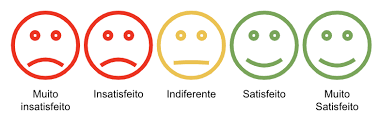

**Como conduzi a A3**

A pesquisa de satisfação foi analisada na amostra de tamanho ideal (141.900 notas), no geral e por sexo.

1. **A3.1 · Discretização:** as 25 frases de opinião foram agrupadas nos 5 níveis da escala de satisfação do enunciado (Muito insatisfeito, Insatisfeito, Indiferente, Satisfeito e Muito satisfeito). Os grupos foram identificados na preparação dos dados: as frases de cada nível aparecem com a mesma frequência.
2. **A3.2 · Bootstrap:** para cada nível, e para os indicadores de satisfação, calculei o intervalo de confiança de 95% com 9.999 reamostragens, no geral e por sexo. Também comparei homens e mulheres com o teste qui-quadrado, o V de Cramér e o bootstrap da diferença entre os percentuais de satisfeitos.
3. **A3.3 · Resultado final:** uma tabela com os percentuais e intervalos de confiança e um gráfico de barras divergentes, o formato padrão para escalas de satisfação.

**Indicadores usados:** % de satisfeitos (Satisfeito + Muito satisfeito), % de insatisfeitos (Insatisfeito + Muito insatisfeito), saldo de satisfação (satisfeitos − insatisfeitos) e nota média, numa escala de 1 a 5.

###Atividade A3.1: Discretizar a Variável Qualitativa (OPINIÃO DO CLIENTE)

In [45]:
# Discretização da OPINIÃO DO CLIENTE na escala de satisfação de 5 pontos
resultado_A3_1 = AtividadeA3_1()

Discretização das 25 frases de opinião na escala de satisfação


,OPINIÃO DO CLIENTE,NÍVEL DA OPINIÃO,SATISFAÇÃO,notas,%
0,Ótimo! Tudo ocorreu maravilhosamente bem com a UVVine,5,Muito satisfeito,888,0.6300
1,"Excelente experiência, recomendo muito a UVVine",5,Muito satisfeito,854,0.6000
2,"Serviço impecável, adorei o clube: UVVine",5,Muito satisfeito,853,0.6000
3,Superou expectativas o atendimento na UVVine,5,Muito satisfeito,846,0.6000
4,"Produto perfeito, chegou antes do prazo de previsão. Top demais a UVVine",5,Muito satisfeito,832,0.5900
5,Fiquei satisfeito com o serviço da UVVine,4,Satisfeito,22092,15.5700
6,"Serviço eficiente, recomendo o clube: UVVine",4,Satisfeito,21987,15.4900
7,Entrega foi boa e rápida na UVVine,4,Satisfeito,21902,15.4300
8,Gostei do atendimento prestado pela UVVine,4,Satisfeito,21843,15.3900
9,Funcionou bem e me atendeu no prazo certo a UVVine,4,Satisfeito,21651,15.2600



Resumo por nível da escala


,notas,%
SATISFAÇÃO,,
Muito insatisfeito,1378,0.9700
Insatisfeito,5445,3.8400
Indiferente,21329,15.0300
Satisfeito,109475,77.1500
Muito satisfeito,4273,3.0100


**O que a discretização mostrou**

- As 25 frases de opinião foram classificadas e nenhuma das 141.900 notas da amostra ficou sem nível.
- Cada nível da escala reúne 5 frases. Dentro de um mesmo nível, as frases aparecem praticamente com a mesma frequência; cada frase de "Satisfeito", por exemplo, responde por cerca de 15,4% das notas. Isso confirma que o agrupamento feito na preparação dos dados está coerente: as frases de um nível são variações da mesma resposta.
- As respostas estão muito concentradas: Satisfeito 77,15%, Indiferente 15,03%, Insatisfeito 3,84%, Muito satisfeito 3,01% e Muito insatisfeito 0,97%.

###Atividade A3.2: Análise Bootstrap do resultado da Pesquisa de Satisfação

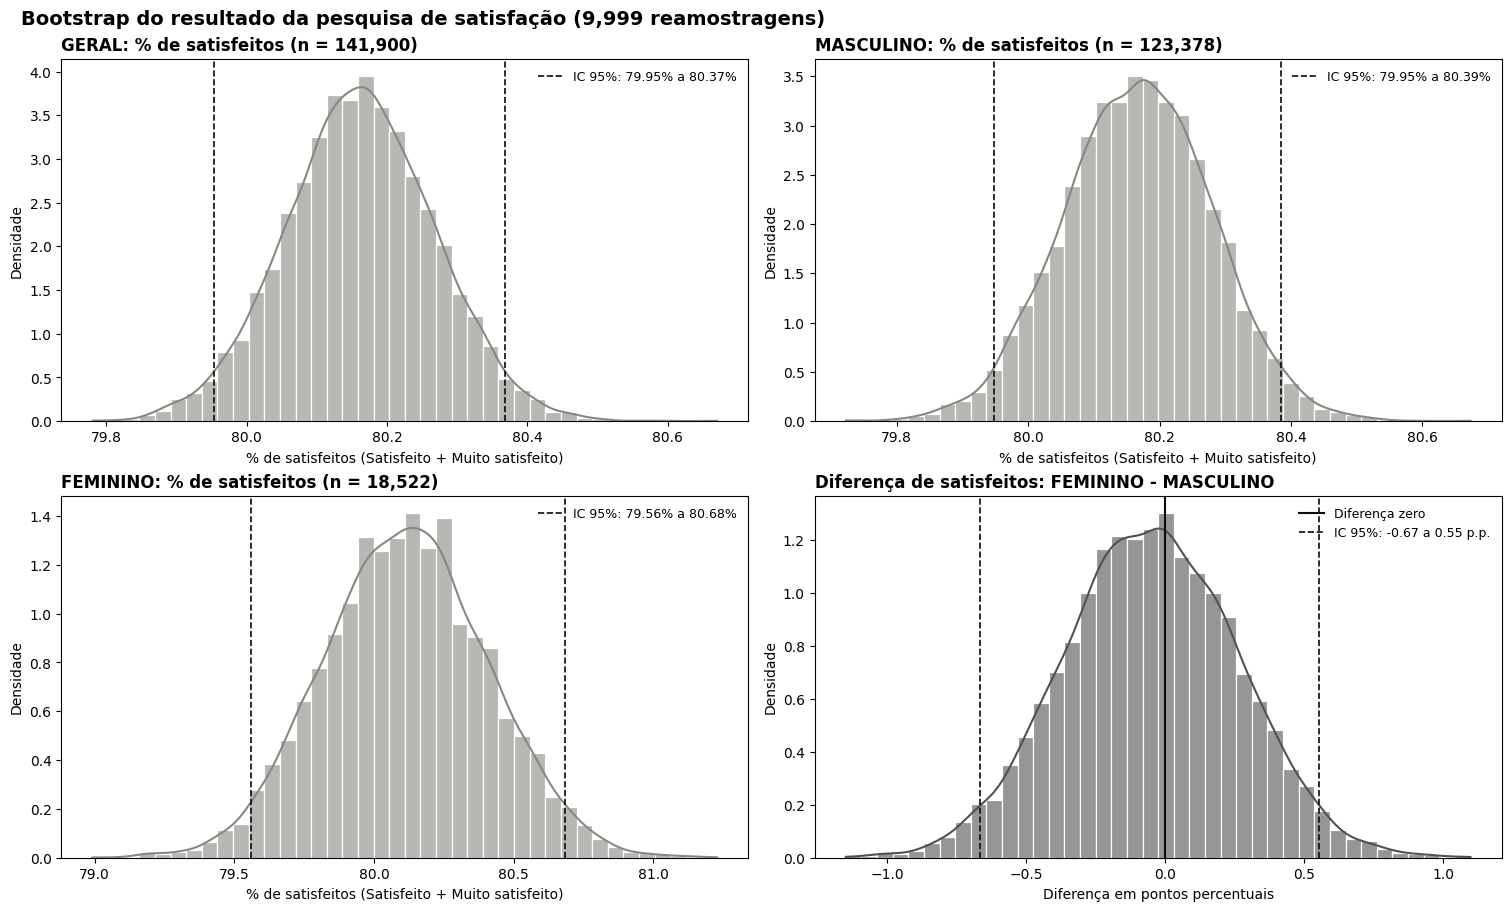


Percentual de cada nível, com intervalo de confiança


,grupo,nível,n,valor,ic_inferior,ic_superior,erro_padrao
0,GERAL,Muito insatisfeito,141900,0.9710,0.9200,1.0230,0.0260
1,GERAL,Insatisfeito,141900,3.8370,3.7370,3.9390,0.0520
2,GERAL,Indiferente,141900,15.0310,14.8440,15.2130,0.0950
3,GERAL,Satisfeito,141900,77.1490,76.9290,77.3690,0.1110
4,GERAL,Muito satisfeito,141900,3.0110,2.9220,3.0990,0.0450
5,MASCULINO,Muito insatisfeito,123378,0.9620,0.9080,1.0170,0.0280
6,MASCULINO,Insatisfeito,123378,3.8280,3.7240,3.9370,0.0540
7,MASCULINO,Indiferente,123378,15.0420,14.8480,15.2410,0.1010
8,MASCULINO,Satisfeito,123378,77.1470,76.9160,77.3790,0.1180
9,MASCULINO,Muito satisfeito,123378,3.0200,2.9260,3.1160,0.0480



Indicadores de satisfação, com intervalo de confiança


,grupo,indicador,valor,ic_inferior,ic_superior,erro_padrao
0,GERAL,Satisfeitos (4 e 5),80.1610,79.9530,80.3690,0.1060
1,GERAL,Insatisfeitos (1 e 2),4.8080,4.6960,4.9220,0.0570
2,GERAL,Saldo (satisfeitos - insatisfeitos),75.3520,75.0730,75.6290,0.1410
3,GERAL,Nota média (1 a 5),3.7740,3.7710,3.7770,0.0020
4,MASCULINO,Satisfeitos (4 e 5),80.1670,79.9490,80.3860,0.1130
5,MASCULINO,Insatisfeitos (1 e 2),4.7900,4.6720,4.9110,0.0610
6,MASCULINO,Saldo (satisfeitos - insatisfeitos),75.3770,75.0820,75.6660,0.1500
7,MASCULINO,Nota média (1 a 5),3.7740,3.7710,3.7780,0.0020
8,FEMININO,Satisfeitos (4 e 5),80.1160,79.5590,80.6830,0.2920
9,FEMININO,Insatisfeitos (1 e 2),4.9290,4.6160,5.2530,0.1600



Comparação entre homens e mulheres


,qui_quadrado,graus_de_liberdade,p_valor,v_de_cramer,dif_satisfeitos_fem_menos_masc_pp,ic_inferior_pp,ic_superior_pp,ic_contem_zero
SEXO x SATISFAÇÃO,1.3181,4,0.8583,0.0030,-0.0519,-0.6667,0.5519,True


In [46]:
# Análise bootstrap do resultado da pesquisa de satisfação, geral e por sexo
resultado_A3_2 = AtividadeA3_2()

**O que o bootstrap mostrou**

- Os intervalos de confiança são estreitos. No geral, 80,16% das notas vêm de clientes satisfeitos (IC 95%: 79,95% a 80,37%) e 4,81% de insatisfeitos (4,70% a 4,92%). O saldo de satisfação é de 75,35 pontos percentuais e a nota média é 3,77 numa escala de 1 a 5.
- As distribuições bootstrap têm formato de sino. O erro padrão do % de satisfeitos (0,106 ponto percentual) é praticamente igual ao da fórmula da proporção, a raiz de p(1 − p)/n. Ou seja, o bootstrap confirma a teoria.
- O intervalo das mulheres é mais largo (79,56% a 80,68%) só porque o grupo é menor: são 18.522 notas, contra 123.378 dos homens.
- Homens e mulheres respondem da mesma forma. O teste qui-quadrado deu p-valor de 85,83% e o V de Cramér foi 0,003, praticamente zero. A diferença de satisfeitos entre mulheres e homens é de −0,05 ponto percentual, com IC de −0,67 a 0,55, que contém o zero. Por isso, não rejeito a hipótese de que a satisfação independe do sexo.

###Atividade A3.3: Resultado Final da Pesquisa de Satisfação

Resultado final da pesquisa de satisfação (valor e intervalo de confiança de 95%)


,GERAL,MASCULINO,FEMININO
Muito insatisfeito,1.0% (0.9 a 1.0),1.0% (0.9 a 1.0),1.0% (0.9 a 1.2)
Insatisfeito,3.8% (3.7 a 3.9),3.8% (3.7 a 3.9),3.9% (3.6 a 4.2)
Indiferente,15.0% (14.8 a 15.2),15.0% (14.8 a 15.2),15.0% (14.4 a 15.5)
Satisfeito,77.1% (76.9 a 77.4),77.1% (76.9 a 77.4),77.2% (76.6 a 77.8)
Muito satisfeito,3.0% (2.9 a 3.1),3.0% (2.9 a 3.1),3.0% (2.7 a 3.2)
Satisfeitos (4 e 5),80.2% (80.0 a 80.4),80.2% (79.9 a 80.4),80.1% (79.6 a 80.7)
Insatisfeitos (1 e 2),4.8% (4.7 a 4.9),4.8% (4.7 a 4.9),4.9% (4.6 a 5.3)
Saldo (satisfeitos - insatisfeitos),75.4 p.p. (75.1 a 75.6),75.4 p.p. (75.1 a 75.7),75.2 p.p. (74.4 a 76.0)
Nota média (1 a 5),3.77 (3.77 a 3.78),3.77 (3.77 a 3.78),3.77 (3.76 a 3.78)


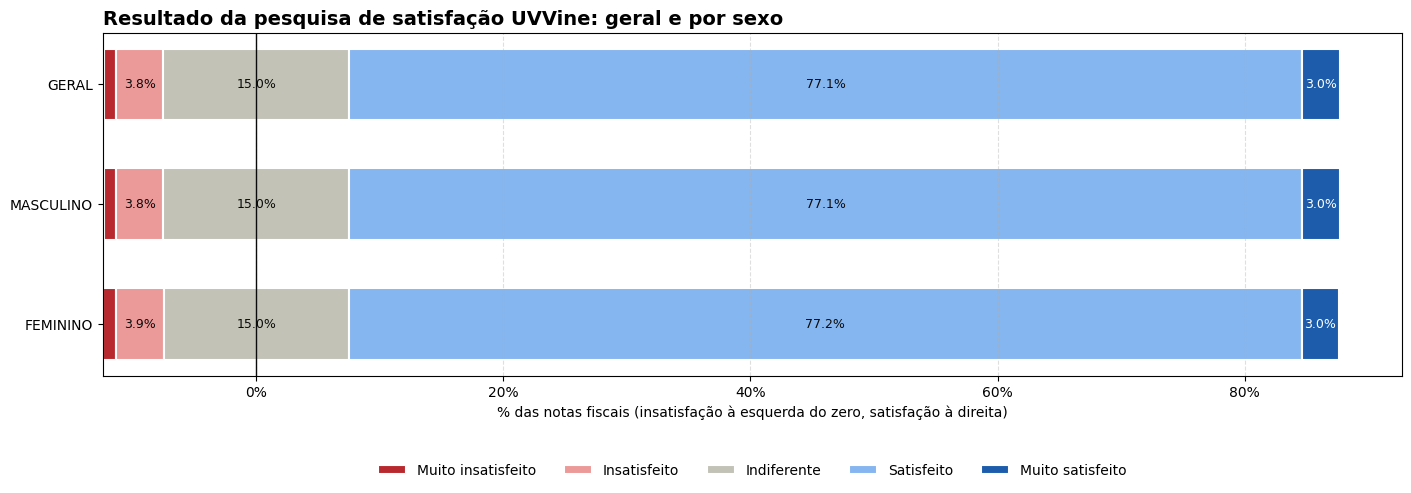

In [49]:
# Resultado final da pesquisa de satisfação
resultado_A3_3 = AtividadeA3_3()

**Resultado final da pesquisa de satisfação**

- Cerca de 4 em cada 5 notas (80,2%) vêm de clientes satisfeitos, e menos de 5% vêm de insatisfeitos. O resultado é o mesmo para homens e mulheres: as três barras do gráfico são praticamente idênticas.
- A satisfação, porém, é "morna": 77,1% marcaram Satisfeito e apenas 3,0% Muito satisfeito. A nota média de 3,77 fica abaixo de 4 justamente porque quase ninguém chega ao topo da escala e 15% se dizem indiferentes.
- Para o negócio, isso quer dizer que o clube não tem um problema de insatisfação, e sim de encantamento. A maior oportunidade é transformar satisfeitos e indiferentes em muito satisfeitos. As frases dos insatisfeitos mostram onde agir: cordialidade e qualidade do atendimento, política de cashback, preço médio e atrasos na entrega. Cada uma aparece em menos de 1% das notas.

# RELATÓRIO FINAL - PARTE 1

## Relatório Final · Parte 1 · UVVine

### Qual é o tamanho ideal da amostra?

**O tamanho ideal da amostra é de 141.900 notas fiscais**, sorteadas aleatoriamente, analisadas por tipo de conta (ESSENTIAL, VIP e PRIME) e tendo como alvo o gasto do cliente (TOTAL R\$).

Com esse tamanho, a UVVine estima o gasto médio com uma margem de erro de cerca de ±0,5% a ±0,6% da média, com 95% de confiança, em todos os tipos de conta. Como a população foi tratada como infinita, esse tamanho não depende do total de notas da base. Ele serve para qualquer nova análise feita nas mesmas condições.

### 1. Base de dados e preparação

- A base original tem 1.120.000 notas fiscais e 23 colunas, sem valores nulos nem linhas duplicadas.
- Removi 72.477 notas (6,47%) com medidas de vinho negativas, o que é fisicamente impossível. A remoção mudou a média do gasto em no máximo 0,056% e manteve a proporção dos tipos de conta.
- Corrigi a escala de opinião: três frases tinham um espaço duplo invisível que deixava 173.755 notas sem classificação.
- **Base final:** 1.047.523 notas fiscais, com ESSENTIAL 59,5%, VIP 23,4% e PRIME 17,1%.

### 2. Justificativa pela Atividade A1 (Estratificação amostral)

**Os cinco procedimentos:**

| Procedimento | Grupo | Tamanho recomendado |
|---|---|---|
| Estabilização marginal do erro padrão | ESSENTIAL | 65.500 |
| Estabilização marginal do erro padrão | VIP | 83.900 |
| Estabilização marginal do erro padrão | **PRIME** | **141.900** |
| Estabilização marginal do erro padrão | GERAL | 122.100 |
| Amostra estratificada ótima (Neyman) | Estratificado | 51.000 |

- **Escolha do tamanho:** segui a regra de ficar com o maior dos cinco resultados. O PRIME define o tamanho porque é o tipo de conta com maior variabilidade no gasto (desvio padrão de R\$ 1.057,51), e esse tamanho atende a todos os outros grupos.
- **Ressalva sobre Neyman:** o resultado de 51.000 depende principalmente do limiar relativo e do passo escolhidos, e não da variabilidade dos dados. Por isso não o usei como referência principal.
- **Confirmação pelo bootstrap:** com 9.999 reamostragens, os intervalos de confiança de 95% contêm a média da base completa nos quatro grupos:

| Grupo | Média na amostra (R\$) | IC 95% (R\$) | Média da base (R\$) |
|---|---|---|---|
| ESSENTIAL | 414,55 | 412,34 a 416,80 | 415,62 |
| VIP | 920,63 | 915,54 a 925,71 | 919,49 |
| PRIME | 2.143,72 | 2.129,96 a 2.156,99 | 2.149,33 |
| GERAL | 828,45 | 824,13 a 832,82 | 829,89 |

  O erro padrão do bootstrap coincidiu com o teórico.
- **Outliers (A1.2):** pelo critério do IQR, os outliers somam 3,67% no ESSENTIAL, 2,84% no VIP e 0% no PRIME. Removê-los não muda o tamanho ideal, que é definido pelo PRIME. Por isso não foi preciso recalcular, e eles foram mantidos para tratamento no Módulo 2.
- **Testes de hipóteses (A1.3):** sorteei duas amostras de 141.900 notas, sem nenhuma nota em comum.

| Pergunta | Resposta | Best fit | p-valor no GERAL |
|---|---|---|---|
| O gasto é normal em cada estrato? | Não | Anderson-Darling | rejeitada em todos os grupos |
| As amostras são independentes? | **Sim** | Spearman | 58,08% |
| Têm a mesma distribuição? | **Sim** | Kolmogorov-Smirnov | 6,43% |
| Têm as mesmas médias? | **Sim** | t de Welch | 28,64% |

  As poucas rejeições isoladas (no VIP e no ESSENTIAL) foram explicadas como erro do tipo I. Em 200 sorteios repetidos, as taxas de rejeição ficaram perto dos 5% esperados só pelo acaso. Ou seja, **duas amostras quaisquer de 141.900 notas contam a mesma história sobre a população**, e é isso que torna esse tamanho confiável.

### 3. Justificativa pela Atividade A2 (Estatística descritiva)

- **A amostra reproduz a população:** ESSENTIAL 59,5%, VIP 23,5% e PRIME 17,1%, as mesmas proporções da base completa.
- **Os tipos de conta são mundos diferentes:**

| Tipo de conta | Gasto médio (R\$) | Renda mediana (R\$) | Participação no faturamento da amostra |
|---|---|---|---|
| ESSENTIAL | 414,55 | 3.256,95 | cerca de 30% |
| VIP | 920,63 | 7.777,17 | cerca de 26% |
| PRIME | 2.143,72 | 20.892,56 | cerca de 44% |

  O cliente PRIME gasta 5,2 vezes mais que o ESSENTIAL. Ele representa 17% das notas, mas cerca de 44% do faturamento. Por isso o gasto precisa ser analisado por tipo de conta: no geral, a média (R\$ 828) fica muito acima da mediana (R\$ 499) e não representa nenhum grupo.
- **A renda é a variável que mais explica o gasto:** correlação de Spearman de 0,74, com faixas de renda quase sem sobreposição entre os tipos de conta.
- **O que não explica o gasto:**
  - região, sexo, estado civil e dependentes têm a mesma distribuição nos três tipos de conta (V de Cramér abaixo de 0,006) e não mudam o gasto mediano dentro de cada tipo;
  - as 13 características dos vinhos têm correlação praticamente zero com o gasto.
- **Perfil do cliente:** 67,1% no Sudeste, 86,9% homens e 55,0% casados.

### 4. Pesquisa de satisfação (Atividade A3)

| Indicador | Geral | Masculino | Feminino |
|---|---|---|---|
| Satisfeitos (Satisfeito + Muito satisfeito) | 80,2% | 80,2% | 80,1% |
| Insatisfeitos (Insatisfeito + Muito insatisfeito) | 4,8% | 4,8% | 4,9% |
| Muito satisfeitos | 3,0% | 3,0% | 3,0% |
| Nota média (1 a 5) | 3,77 | 3,77 | 3,77 |

- Quatro em cada cinco clientes estão satisfeitos, e homens e mulheres avaliam o clube da mesma forma (qui-quadrado com p-valor de 85,83%).
- A satisfação, porém, é "morna": só 3% estão muito satisfeitos e 15% estão indiferentes.

### 5. Recomendações para a gestão da UVVine

1. **Adotar 141.900 notas fiscais como tamanho padrão de amostra** para acompanhar o gasto e a satisfação, sempre separando os resultados por tipo de conta.
2. **Priorizar o cliente PRIME:** é o grupo de maior faturamento e o que mais varia, e por isso o que exige mais dados para ser medido.
3. **Segmentar pela renda e pelo tipo de conta, e não pelo perfil demográfico.** Na base analisada, região, sexo e estado civil não diferenciam o gasto.
4. **Trabalhar o encantamento do cliente:** o desafio não é a insatisfação, e sim transformar satisfeitos e indiferentes em muito satisfeitos. As opiniões negativas apontam onde agir: cordialidade e qualidade do atendimento, cashback, preço médio e atrasos na entrega.
5. **Corrigir a qualidade dos dados na origem:**
   - medidas de vinho negativas;
   - espaços duplos nas frases de opinião;
   - a nota de satisfação, que em 92,4% das notas é exatamente 68,68% e só varia no PRIME;
   - valores aleatórios espalhados no gasto e na renda, que contaminam os dois.

### 6. Limitações e observações

- O gasto não segue distribuição normal em nenhum grupo. Por isso, usei testes não paramétricos nas perguntas de distribuição. Nas médias, o t de Welch é válido pelo Teorema Central do Limite.
- O tamanho de 141.900 foi calculado para o estrato PRIME e aplicado ao total da amostra, como pede a regra do maior dos cinco. Mesmo com 24.218 notas PRIME na amostra, a precisão desse grupo (±0,63%) ficou próxima à dos demais.
- Os outliers foram mantidos para retratar a população como ela é. Eles serão tratados nos modelos do Módulo 2 (clusterizador, regressor do gasto e classificador do tipo de conta), em que a renda é a variável mais promissora.

In [51]:
%%shell
# Converte o notebook para HTML. Depois, o HTML é impresso em PDF no navegador.
jupyter nbconvert --to html /content/Projeto_Integrador_WORKFLOW_PARTE_1.ipynb

[NbConvertApp] Converting notebook /content/Projeto_Integrador_WORKFLOW_PARTE_1.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 28 image(s).
[NbConvertApp] Writing 6897986 bytes to /content/Projeto_Integrador_WORKFLOW_PARTE_1.html
